# Base-paper figures, tables, curves & matrices — reproduced with YOUR improved models (train **and** test) + Boruta-SHAP
Paper: Mukherjee et al. (2025), *J. Asian Earth Sci.* 293, 106764. Same 61 features, same 6 models, same 16 (window × threshold) combos — models use the **final improved recipes**.

| Paper item | Here | Notes |
|---|---|---|
| Fig. 1a (base map: faults + elevation) | ✘ | needs DEM / fault shapefiles (GIS data), not in your catalogue |
| Fig. 1b (event map by magnitude) | ✔ §A | |
| Fig. 2 (workflow flowchart) | ✔ §A | |
| Fig. 3 (histogram of events per magnitude range) | ✔ §A | |
| Table 1 (61 features) | ✔ §A | |
| Fig. 4, S1–S3 (correlation matrix, plain full heatmap) | ✔ §A | features don't depend on the window → one matrix covers 7/10/15/30 d |
| **Fig. 5, 6 (Boruta-SHAP ranking, train & test set)** | ✔ §A | own implementation: shadow features + RandomForest + SHAP (paper Appendix 1) |
| Table 2 (training samples, k-fold) | ✔ §C | yours: no under-sampling, so full training set; 5-fold CV |
| Table 3 (hyper-parameters) | ✔ §C | yours are tuned **per combo** (7-day shown, all in CSV) |
| Fig. 7 (learning curves, mag ≥ 4, 7 d) | ✔ §C | train/CV accuracy and loss |
| Fig. 8, S10–S12 (confusion matrices) | ✔ §C | **train (CV) and test** |
| Fig. 9, S14–S16 (ROC curves + AUC) | ✔ §C | **train (CV) and test** |
| Tables 4–7 (TN, FP, FN, TP, Precision, Recall, F1, Accuracy, AUC) | ✔ §C | **train (CV) and test**, one table per window |
| Table 8, 9 (train / test accuracy) + Fig. 10, 11 (bar charts) | ✔ §C | plus paper-vs-yours comparison |

**Order:** §A (data figures + Boruta-SHAP) runs in minutes → §B trains the models (**slow, resumable**: every finished combo is stored in `paper_artifacts/`) → §C draws everything from those stored predictions.

**Env switches:** `EQ_WINDOWS=7,10` run only some windows · `EQ_COMBOS=weak` thresholds 4.0/4.5 only · `EQ_MODELS=SVM,ANN` subset · `EQ_BORUTA_ALL=1` Boruta-SHAP for all windows (default: 7 d like the paper) · `EQ_LEARNING=0` skip learning curves · `EQ_FAST=0` heavy search · `EQ_TINY=1` smoke test only.
All figures are also saved as PNG in `paper_figures/` (zipped at the end).

In [1]:
import os, time, json, bisect, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import randint, uniform, loguniform
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.experimental import enable_halving_search_cv  # noqa
from sklearn.model_selection import (StratifiedKFold, train_test_split, RandomizedSearchCV,
                                     HalvingRandomSearchCV, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, QuantileTransformer, PowerTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score, accuracy_score, roc_auc_score)
from xgboost import XGBClassifier
warnings.filterwarnings('ignore'); os.environ['PYTHONWARNINGS'] = 'ignore'
if not hasattr(np, 'bool'):  np.bool  = bool
if not hasattr(np, 'int'):   np.int   = int
if not hasattr(np, 'float'): np.float = float
pd.set_option('display.max_columns', 100)

RNG_SEED  = 42
DATA_PATH = os.environ.get('EQ_DATA', 'Homogenous_data_depth-Eventplot (1).xlsx')
FAST   = os.environ.get('EQ_FAST', '1') == '1'
TINY   = os.environ.get('EQ_TINY', '0') == '1'
COMBOS = os.environ.get('EQ_COMBOS', 'all')
RUN_MODELS = [m.strip() for m in os.environ.get('EQ_MODELS', 'kNN,SVM,DT,RF,XGBoost,ANN').split(',')]
SPLIT_MODE = os.environ.get('EQ_SPLIT', 'random')         # 'random' (stratified, as in all earlier runs) | 'chronological'
SEARCH_CV = 3
# classical models (kNN, DT, RF, XGBoost)
N_ITER = {'kNN': 8, 'DT': 20, 'RF': 8, 'XGBoost': 12} if FAST else {'kNN': 15, 'DT': 40, 'RF': 20, 'XGBoost': 30}
# SVM
SVM_CANDIDATES, SVM_TUNE_THRESHOLD = (24 if FAST else 60), True
# ANN
if TINY:   ANN_ITER, ANN_MEMBERS, TOP_K, MAX_ITER, SEARCH_ROWS, SEARCH_MEMBERS, BIG = 3, 2, 2, 40, 1500, 1, False
elif FAST: ANN_ITER, ANN_MEMBERS, TOP_K, MAX_ITER, SEARCH_ROWS, SEARCH_MEMBERS, BIG = 12, 3, 2, 100, 4000, 1, False
else:      ANN_ITER, ANN_MEMBERS, TOP_K, MAX_ITER, SEARCH_ROWS, SEARCH_MEMBERS, BIG = 24, 5, 3, 200, 8000, 2, True
if TINY:   N_ITER = {'kNN': 2, 'DT': 3, 'RF': 2, 'XGBoost': 2}; SVM_CANDIDATES = 6
np.random.seed(RNG_SEED)
print(dict(FAST=FAST, TINY=TINY, COMBOS=COMBOS, SPLIT_MODE=SPLIT_MODE, models=RUN_MODELS, cores=os.cpu_count()))

# ---- extras for the paper-figure notebook ----
import joblib, subprocess, sys, shutil
from joblib import Parallel, delayed
from scipy.stats import binomtest
from sklearn.metrics import roc_curve, log_loss
try:
    import shap
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'shap']); import shap
WINDOWS_RUN = [int(x) for x in os.environ.get('EQ_WINDOWS', '7,10,15,30').split(',')]
BORUTA_ALL  = os.environ.get('EQ_BORUTA_ALL', '0') == '1'
LEARNING    = os.environ.get('EQ_LEARNING', '1') == '1'
BORUTA_TRIALS = 6 if TINY else (15 if FAST else 30)
FIG_DIR, ART_DIR = 'paper_figures', 'paper_artifacts'
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(ART_DIR, exist_ok=True)
print('windows to train:', WINDOWS_RUN, '| Boruta trials:', BORUTA_TRIALS, '| shap', shap.__version__)

{'FAST': True, 'TINY': False, 'COMBOS': 'all', 'SPLIT_MODE': 'random', 'models': ['kNN', 'SVM', 'DT', 'RF', 'XGBoost', 'ANN'], 'cores': 4}
windows to train: [7, 10, 15, 30] | Boruta trials: 15 | shap 0.52.0


## 0. Catalogue → the paper's 61 features → labels (same code as your final notebook)

In [2]:
def load_catalog(path):
    df = pd.read_excel(path, sheet_name='Sheet1')
    df = df.sort_values(['year', 'month', 'day', 'hour', 'min', 'second']).reset_index(drop=True)
    df['t_days'] = ((df['year'] - df['year'].min()) * 365.25
                     + (df['month'] - 1) * 30.44
                     + df['day']
                     + df['hour'] / 24
                     + df['min'] / 1440
                     + df['second'] / 86400)
    df['t_days'] = df['t_days'] - df['t_days'].min()
    df = df.drop_duplicates(subset=['year', 'month', 'day', 'hour', 'min',
                                     'magnitude', 'lattitude', 'longitude'])
    return df.reset_index(drop=True)

raw_df = load_catalog(DATA_PATH)
print(raw_df.shape)
raw_df.head()


(14994, 12)


,year,month,day,hour,min,second,lattitude,longitude,depth,magnitude,energy,t_days
0,1803,9,1,5,53,28,27.5,77.7,0.0,6.8,1602.366677,0.00
1,1816,5,26,5,53,28,30.0,80.0,0.0,6.5,359.261977,4651.49
2,1833,8,26,5,53,28,27.5,86.5,0.0,7.5,52470.284610,10952.06
3,1842,3,5,5,53,28,30.0,78.0,0.0,5.5,2.459853,14066.11
4,1843,4,11,5,53,28,30.0,80.0,0.0,5.0,0.203544,14467.80


In [3]:
LOG10E = np.log10(np.e)

def gr_least_squares(mags):
    """Eqs. (3)-(5): least-squares fit of log10(N>=M) vs M."""
    order = np.sort(mags)[::-1]
    N = np.arange(1, len(order) + 1)
    logN = np.log10(N)
    M = order
    n = len(M)
    sM, slogN, sMlogN, sM2 = M.sum(), logN.sum(), (M * logN).sum(), (M ** 2).sum()
    denom = (sM ** 2 - n * sM2)
    if denom == 0:
        return np.nan, np.nan, logN, M
    b = (n * sMlogN - sM * slogN) / denom
    a = (slogN + b * sM) / n
    return a, b, logN, M

def gr_max_likelihood(mags):
    """Eqs. (6)-(7): Bender (1983) maximum-likelihood a,b."""
    mean_m, min_m = mags.mean(), mags.min()
    denom = mean_m - min_m
    if denom <= 0:
        return np.nan, np.nan
    b = LOG10E / denom
    n = len(mags)
    a = np.log10(n) + b * min_m
    return a, b

def window_features(win, t_now, full_df):
    M = win['magnitude'].values
    n = len(M)
    T_Days = max(win['t_days'].iloc[-1] - win['t_days'].iloc[0], 1e-6)          # Eq (1)

    a_lsq, b_lsq, logN, Msorted = gr_least_squares(M)                          # Eqs (3)-(5)
    a_lik, b_lik = gr_max_likelihood(M)                                       # Eqs (6)-(7)
    Mean_Mag = M.mean()                                                        # Eq (2)
    Energy = np.sum(np.sqrt(10 ** (11.8 + 1.5 * M))) / T_Days                  # Eq (8)

    # Eq (9): Habermann z-test, R1/R2 = event rate in 15d / 30d windows ending at t_now
    w15 = full_df[(full_df['t_days'] > t_now - 15) & (full_df['t_days'] <= t_now)]
    w30 = full_df[(full_df['t_days'] > t_now - 45) & (full_df['t_days'] <= t_now - 15)]
    n1, n2 = len(w15), len(w30)
    R1, R2 = n1 / 15.0, n2 / 30.0
    s1 = w15['magnitude'].std(ddof=0) if n1 > 1 else 0
    s2 = w30['magnitude'].std(ddof=0) if n2 > 1 else 0
    denom_z = np.sqrt((s1 ** 2 / max(n1, 1)) + (s2 ** 2 / max(n2, 1)))
    Z = (R1 - R2) / denom_z if denom_z > 0 else 0.0

    # Eq (10): max magnitude in last 7 days
    w7 = full_df[(full_df['t_days'] > t_now - 7) & (full_df['t_days'] <= t_now)]
    x6 = w7['magnitude'].max() if len(w7) else M[-1]

    # Eq (11): mean recurrence interval of "characteristic" events (M>=5.0 proxy)
    char = win[win['magnitude'] >= 5.0]
    if len(char) >= 2:
        dt = np.diff(char['t_days'].values)
        mu = dt.mean()
        c_val = dt.std(ddof=0) / mu if mu > 0 else 0.0                         # Eq (18)
    else:
        mu, c_val = T_Days, 0.0

    feats = {'T_Days': T_Days, 'b_lik': b_lik, 'b_lsq': b_lsq, 'a_lik': a_lik, 'a_lsq': a_lsq}

    # Eq (14): std dev of b-value
    feats['std_b_lik'] = 2.3 * b_lik ** 2 * np.sqrt(np.sum((M - Mean_Mag) ** 2) / (n * (n - 1))) if not np.isnan(b_lik) else np.nan
    feats['std_b_lsq'] = 2.3 * b_lsq ** 2 * np.sqrt(np.sum((M - Mean_Mag) ** 2) / (n * (n - 1))) if not np.isnan(b_lsq) else np.nan

    # Eq (17): T_Rec for M0 = 4.0 ... 6.0 in 0.1 steps (21 values) x 2 methods = 42 features
    for tag, a_, b_ in [('lik', a_lik, b_lik), ('lsq', a_lsq, b_lsq)]:
        for M0 in np.round(np.arange(4.0, 6.01, 0.1), 1):
            feats[f'T_Rec_{tag}_{M0}'] = T_Days / (10 ** (a_ - b_ * M0)) if not np.isnan(a_) else np.nan

    feats.update(Mean_Mag=Mean_Mag, Energy=Energy, Z_Value=Z, x6=x6, mu=mu, C=c_val)

    # Eq (12): probability of M>=6.5 (GR exceedance)
    feats['x7_mlk'] = 10 ** (a_lik - b_lik * 6.5) if not np.isnan(b_lik) else np.nan
    feats['x7_lsq'] = 10 ** (a_lsq - b_lsq * 6.5) if not np.isnan(b_lsq) else np.nan

    # Eq (13): deviation from GR law
    pred_lik = a_lik - b_lik * Msorted if not np.isnan(a_lik) else np.full(n, np.nan)
    pred_lsq = a_lsq - b_lsq * Msorted if not np.isnan(a_lsq) else np.full(n, np.nan)
    feats['NU_mlik'] = np.sum((logN - pred_lik) ** 2) / (n - 1)
    feats['NU_lsq'] = np.sum((logN - pred_lsq) ** 2) / (n - 1)

    # Eqs (15)-(16): magnitude deficit
    feats['M_def_Lik'] = (a_lik / b_lik) - M.max() if b_lik else np.nan
    feats['M_def_lsq'] = (a_lsq / b_lsq) - M.max() if b_lsq else np.nan

    feats['Actual_Mag'] = M[-1]
    return feats

def compute_all_features(df, n_window=50):
    rows, idxs = [], []
    for i in range(n_window - 1, len(df)):
        win = df.iloc[i - n_window + 1: i + 1]
        feats = window_features(win, df['t_days'].iloc[i], df)
        rows.append(feats); idxs.append(i)
    feat_df = pd.DataFrame(rows, index=idxs)
    feat_df['event_idx'] = idxs
    feat_df['t_days'] = df['t_days'].iloc[idxs].values
    return feat_df


In [4]:
FEAT_CACHE = 'engineered_features_61.csv'
if os.path.exists(FEAT_CACHE):
    feat_df = pd.read_csv(FEAT_CACHE); print('loaded cached features', feat_df.shape)
else:
    feat_df = compute_all_features(raw_df, n_window=50); feat_df.to_csv(FEAT_CACHE, index=False)
FEATURE_COLS = [c for c in feat_df.columns if c not in ('Actual_Mag', 'event_idx', 't_days')]
print(feat_df.shape, '|', len(FEATURE_COLS), 'input features')

(14945, 64) | 61 input features


In [5]:
def clean_features(X_df):
    X = X_df.replace([np.inf, -np.inf], np.nan)
    X = X.clip(lower=X.quantile(0.01), upper=X.quantile(0.99), axis=1)
    X = X.fillna(X.median())
    return X

feat_df_clean = feat_df.copy()
feat_df_clean[FEATURE_COLS] = clean_features(feat_df[FEATURE_COLS])


In [6]:
def make_labels(raw_df, feat_df, window_days, threshold):
    times = raw_df['t_days'].values
    mags = raw_df['magnitude'].values
    order = np.argsort(times)
    times_sorted, mags_sorted = times[order], mags[order]
    labels = np.zeros(len(feat_df), dtype=int)
    for k, t_now in enumerate(feat_df['t_days'].values):
        lo = bisect.bisect_right(times_sorted, t_now)
        hi = bisect.bisect_right(times_sorted, t_now + window_days)
        if hi > lo:
            labels[k] = 1 if mags_sorted[lo:hi].max() >= threshold else 0
    return labels


## 0b. Helpers + the six final model recipes (same as your final notebook)

In [7]:
def split_train_test(feat_df, labels, train_frac=0.75, seed=RNG_SEED, mode=None):
    mode = mode or SPLIT_MODE
    X = feat_df[FEATURE_COLS].values
    if mode == 'chronological':
        n = int(round(len(X) * train_frac)); return X[:n], labels[:n], X[n:], labels[n:]
    Xtr, Xte, ytr, yte = train_test_split(X, labels, train_size=train_frac, random_state=seed, stratify=labels)
    return Xtr, ytr, Xte, yte

def metrics_from_preds(y_true, y_pred, y_score=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    auc = roc_auc_score(y_true, y_score) if (y_score is not None and len(np.unique(y_true)) > 1) else np.nan
    return dict(TN=tn, FP=fp, FN=fn, TP=tp, Precision=precision_score(y_true, y_pred, zero_division=0),
                Recall=recall_score(y_true, y_pred, zero_division=0), F1=f1_score(y_true, y_pred, zero_division=0),
                Accuracy=accuracy_score(y_true, y_pred), AUC=auc)

def get_score(model, X):
    return model.predict_proba(X)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X)

TFS = [QuantileTransformer(output_distribution='normal', n_quantiles=500, random_state=RNG_SEED),
       PowerTransformer(), StandardScaler()]

# ---------- kNN / DT / RF / XGBoost : per-combo RandomizedSearchCV ----------
def classical_specs(spw, seed=RNG_SEED):
    cw = [None, 'balanced']
    return {
      'kNN': (Pipeline([('sc', StandardScaler()), ('m', KNeighborsClassifier())]),
              {'m__n_neighbors': randint(3, 40), 'm__p': [1, 2], 'm__weights': ['uniform']}),
      'DT':  (DecisionTreeClassifier(random_state=seed),
              {'max_depth': randint(3, 20), 'min_samples_split': randint(2, 20), 'min_samples_leaf': randint(1, 10),
               'criterion': ['gini', 'entropy'], 'class_weight': cw}),
      'RF':  (RandomForestClassifier(random_state=seed, n_jobs=1),
              {'n_estimators': randint(100, 400), 'max_depth': randint(4, 20), 'min_samples_leaf': randint(1, 8),
               'min_samples_split': randint(2, 12), 'max_features': ['sqrt', 'log2', 0.5], 'class_weight': cw}),
      'XGBoost': (XGBClassifier(random_state=seed, eval_metric='logloss', tree_method='hist', n_jobs=1),
              {'max_depth': randint(3, 10), 'learning_rate': uniform(0.03, 0.17), 'n_estimators': randint(80, 400),
               'subsample': uniform(0.5, 0.5), 'colsample_bytree': uniform(0.5, 0.5), 'min_child_weight': randint(1, 8),
               'reg_alpha': uniform(0, 1), 'reg_lambda': uniform(0.5, 2.5), 'scale_pos_weight': [1.0, spw]}),
    }

def run_classical(name, est, dist, X_tr, y_tr, X_te, y_te, inner):
    search = RandomizedSearchCV(est, dist, n_iter=N_ITER[name], scoring='accuracy', cv=inner,
                                random_state=RNG_SEED, n_jobs=-1, refit=True).fit(X_tr, y_tr)
    model = search.best_estimator_
    cvp = cross_val_predict(model, X_tr, y_tr, cv=StratifiedKFold(5, shuffle=True, random_state=RNG_SEED), n_jobs=-1)
    yp = model.predict(X_te)
    return (metrics_from_preds(y_tr, cvp), {**metrics_from_preds(y_te, yp, get_score(model, X_te)), 'Acc_default_thr': np.nan}, yp)

# ---------- SVM : Halving search + quantile transform + threshold tuning ----------
def best_threshold(scores, y):
    cands = np.unique(np.quantile(scores, np.linspace(0.05, 0.95, 91)))
    return cands[int(np.argmax([accuracy_score(y, (scores >= t).astype(int)) for t in cands]))]

def run_svm(X_tr, y_tr, X_te, y_te, inner):
    est = Pipeline([('tf', TFS[0]), ('m', SVC(kernel='rbf', cache_size=1500, random_state=RNG_SEED))])
    dist = {'tf': TFS, 'm__C': loguniform(1, 1e4), 'm__gamma': loguniform(1e-4, 1), 'm__class_weight': [None, 'balanced']}
    search = HalvingRandomSearchCV(est, dist, n_candidates=SVM_CANDIDATES, factor=3, min_resources=1000, scoring='accuracy',
                                   cv=inner, random_state=RNG_SEED, n_jobs=-1, refit=True).fit(X_tr, y_tr)
    model = search.best_estimator_
    cvs = cross_val_predict(model, X_tr, y_tr, cv=StratifiedKFold(5, shuffle=True, random_state=RNG_SEED),
                            method='decision_function', n_jobs=-1)
    t_use = best_threshold(cvs, y_tr) if SVM_TUNE_THRESHOLD else 0.0
    sc = model.decision_function(X_te); yp = (sc >= t_use).astype(int)
    return (metrics_from_preds(y_tr, (cvs >= t_use).astype(int)),
            {**metrics_from_preds(y_te, yp, sc), 'Acc_default_thr': accuracy_score(y_te, (sc >= 0).astype(int))}, yp)

# ---------- ANN : seed-ensemble MLPs + oversampling + top-k ensemble ----------
class MLPEnsemble2(BaseEstimator, ClassifierMixin):
    """Seed-ensemble of MLPs; optional minority oversampling per member (no data is discarded)."""
    def __init__(self, hidden_layer_sizes=(64, 32), activation='relu', solver='adam', alpha=1e-5,
                 learning_rate_init=1e-3, batch_size=256, oversample=False, n_members=3,
                 max_iter=200, random_state=42):
        self.hidden_layer_sizes=hidden_layer_sizes; self.activation=activation; self.solver=solver
        self.alpha=alpha; self.learning_rate_init=learning_rate_init; self.batch_size=batch_size
        self.oversample=oversample; self.n_members=n_members; self.max_iter=max_iter; self.random_state=random_state
    def fit(self, X, y):
        self.classes_ = np.unique(y); rng = np.random.RandomState(self.random_state); self.members_ = []
        for i in range(self.n_members):
            idx = np.arange(len(y))
            if self.oversample:
                pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
                small, big = (pos, neg) if len(pos) < len(neg) else (neg, pos)
                idx = np.concatenate([idx, rng.choice(small, size=len(big) - len(small), replace=True)])
            kw = dict(hidden_layer_sizes=self.hidden_layer_sizes, activation=self.activation, solver=self.solver,
                      alpha=self.alpha, max_iter=self.max_iter, early_stopping=False, tol=1e-5,
                      random_state=self.random_state + i)
            if self.solver == 'adam':
                kw.update(learning_rate_init=self.learning_rate_init, batch_size=min(self.batch_size, len(idx)), n_iter_no_change=20)
            self.members_.append(MLPClassifier(**kw).fit(X[idx], y[idx]))
        return self
    def predict_proba(self, X): return np.mean([m.predict_proba(X) for m in self.members_], axis=0)
    def predict(self, X): return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

class AvgProba(BaseEstimator, ClassifierMixin):
    """Average predict_proba of several (unfitted) pipelines — the top-k configs from the search."""
    def __init__(self, models=None): self.models = models
    def fit(self, X, y):
        self.classes_ = np.unique(y); self.fitted_ = [clone(m).fit(X, y) for m in self.models]; return self
    def predict_proba(self, X): return np.mean([m.predict_proba(X) for m in self.fitted_], axis=0)
    def predict(self, X): return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

HIDDEN = [(32, 16), (64, 32), (128, 64), (64, 32, 16)] + ([(128, 64, 32), (64, 64, 64), (256, 128)] if BIG else [])

def run_ann(X_tr, y_tr, X_te, y_te, inner):
    est = Pipeline([('tf', TFS[0]), ('m', MLPEnsemble2(n_members=SEARCH_MEMBERS, max_iter=MAX_ITER, random_state=RNG_SEED))])
    dist = {'tf': TFS, 'm__hidden_layer_sizes': HIDDEN, 'm__activation': ['relu', 'tanh'],
            'm__solver': ['adam', 'lbfgs'] if BIG else ['adam'], 'm__alpha': loguniform(1e-7, 1e-2),
            'm__learning_rate_init': loguniform(5e-4, 1e-2), 'm__batch_size': [128, 256, 512], 'm__oversample': [False, True]}
    Xs, ys = X_tr, y_tr
    if len(y_tr) > SEARCH_ROWS:
        Xs, _, ys, _ = train_test_split(X_tr, y_tr, train_size=SEARCH_ROWS, random_state=RNG_SEED, stratify=y_tr)
    search = RandomizedSearchCV(est, dist, n_iter=ANN_ITER, scoring='accuracy', cv=inner, random_state=RNG_SEED,
                                n_jobs=-1, refit=False).fit(Xs, ys)
    res = pd.DataFrame(search.cv_results_).sort_values('rank_test_score').head(TOP_K)
    plist = [{**p, 'm__n_members': ANN_MEMBERS} for p in res['params']]
    model = AvgProba(models=[clone(est).set_params(**p) for p in plist]).fit(X_tr, y_tr)      # final: ALL rows
    one = clone(est).set_params(**{**plist[0], 'm__n_members': 1})
    cvp = cross_val_predict(one, X_tr, y_tr, cv=StratifiedKFold(3, shuffle=True, random_state=RNG_SEED), n_jobs=-1)
    sc = model.predict_proba(X_te)[:, 1]; yp = (sc >= 0.5).astype(int)
    return (metrics_from_preds(y_tr, cvp), {**metrics_from_preds(y_te, yp, sc), 'Acc_default_thr': accuracy_score(y_te, yp)}, yp)

## A. Data figures + Boruta-SHAP (fast)
### A1. Fig. 1b — event map by magnitude · Fig. 3 — histogram · Table 1 — the 61 features

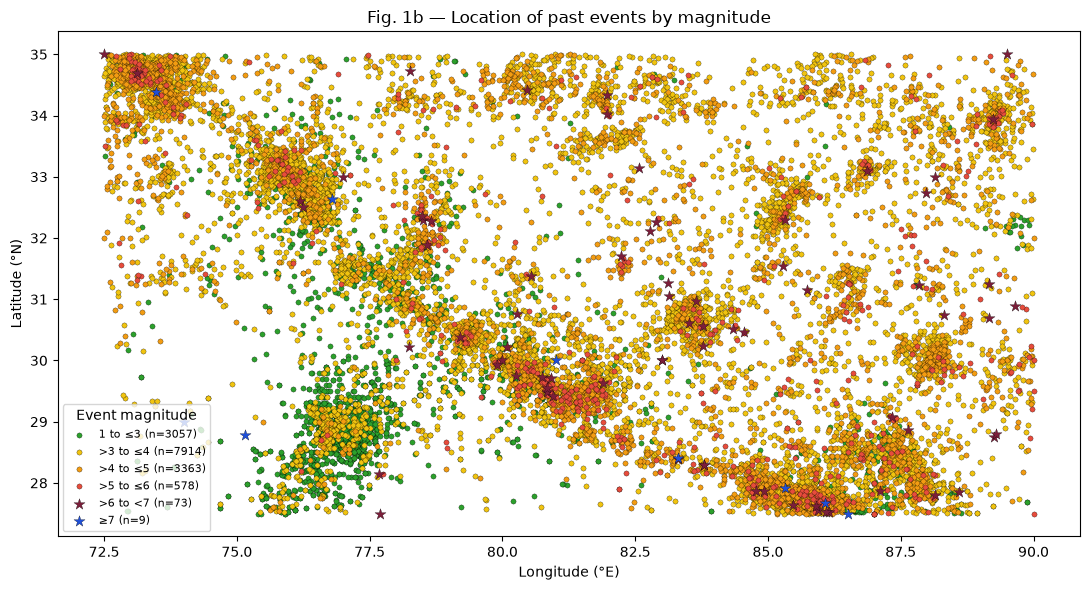

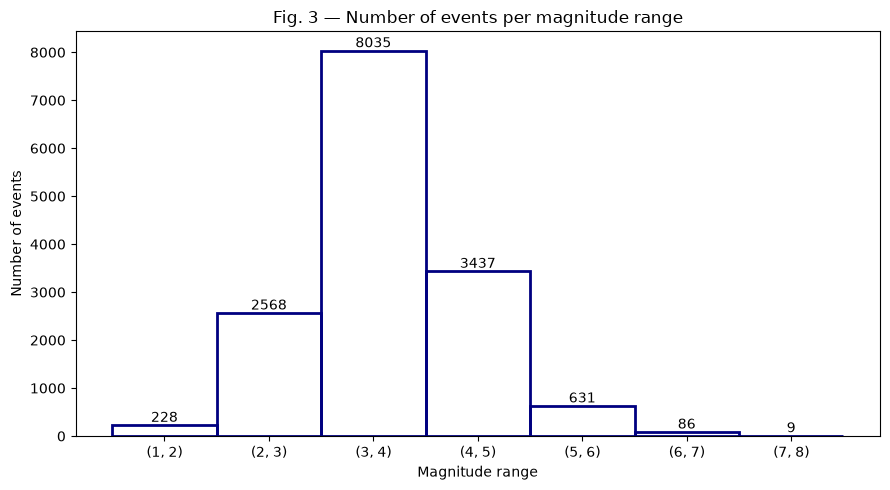

Table 1 — 61 features (paper) | features actually computed here: 61 | paper total: 61


,Seismic indicator,Parameter,Computation method,# features,Remarks
0,Non-parametric,b-value,Max-likelihood / Least square,2,"b_lik, b_lsq"
1,Non-parametric,a-value,Max-likelihood / Least square,2,"a_lik, a_lsq"
2,Non-parametric,dE^(1/2),-,1,Rate of square root of seismic energy
3,Non-parametric,T_Days,-,1,Time of n events
4,Non-parametric,M_mean,-,1,Mean magnitude
5,Non-parametric,z-value,-,1,Seismic rate changes
6,Non-parametric,x6,-,1,Maximum magnitude in last 7 days
7,Non-parametric,mu,-,1,Mean time between characteristic events
8,Parametric,x7,Max-likelihood / Least square,2,Probability of an earthquake of M>=6.0
9,Parametric,eta,Max-likelihood / Least square,2,Deviation from Gutenberg-Richter law


In [8]:
WINDOWS, THRESHOLDS = [7, 10, 15, 30], [4.0, 4.5, 5.0, 5.5]
MODEL_ORDER = ['kNN', 'SVM', 'DT', 'RF', 'XGBoost', 'ANN']
mag = raw_df['magnitude'].values
bins = [(1, 3, '1 to ≤3', '#2ca02c', 'o'), (3, 4, '>3 to ≤4', '#f1c40f', 'o'), (4, 5, '>4 to ≤5', '#f39c12', 'o'),
        (5, 6, '>5 to ≤6', '#e74c3c', 'o'), (6, 7, '>6 to <7', '#7b1e3a', '*'), (7, 99, '≥7', '#1f4fd8', '*')]
fig, ax = plt.subplots(figsize=(11, 6))
masks = [(mag >= 1) & (mag <= 3), (mag > 3) & (mag <= 4), (mag > 4) & (mag <= 5), (mag > 5) & (mag <= 6), (mag > 6) & (mag < 7), (mag >= 7)]
for (lo, hi, lab, col, mk), m in zip(bins, masks):
    ax.scatter(raw_df.loc[m, 'longitude'], raw_df.loc[m, 'lattitude'], s=14 if mk == 'o' else 70, c=col, marker=mk, label=f'{lab} (n={int(m.sum())})', edgecolor='k', linewidth=0.2)
ax.set_xlabel('Longitude (°E)'); ax.set_ylabel('Latitude (°N)'); ax.legend(title='Event magnitude', fontsize=8)
ax.set_title('Fig. 1b — Location of past events by magnitude'); plt.tight_layout(); plt.savefig(f'{FIG_DIR}/Fig1b_event_map.png', dpi=200); plt.show()

edges = np.arange(1, int(np.ceil(mag.max())) + 1)
cnt, _ = np.histogram(mag, bins=edges)
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(range(len(cnt)), cnt, width=1.0, fill=False, edgecolor='navy', linewidth=2)
for i, c in enumerate(cnt): ax.text(i, c, str(c), ha='center', va='bottom')
ax.set_xticks(range(len(cnt))); ax.set_xticklabels([f'({a}, {a+1})' for a in edges[:-1]])
ax.set_xlabel('Magnitude range'); ax.set_ylabel('Number of events'); ax.set_title('Fig. 3 — Number of events per magnitude range')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/Fig3_magnitude_histogram.png', dpi=200); plt.show()

table1 = pd.DataFrame([
 ['Non-parametric', 'b-value', 'Max-likelihood / Least square', 2, 'b_lik, b_lsq'], ['Non-parametric', 'a-value', 'Max-likelihood / Least square', 2, 'a_lik, a_lsq'],
 ['Non-parametric', 'dE^(1/2)', '-', 1, 'Rate of square root of seismic energy'], ['Non-parametric', 'T_Days', '-', 1, 'Time of n events'],
 ['Non-parametric', 'M_mean', '-', 1, 'Mean magnitude'], ['Non-parametric', 'z-value', '-', 1, 'Seismic rate changes'],
 ['Non-parametric', 'x6', '-', 1, 'Maximum magnitude in last 7 days'], ['Non-parametric', 'mu', '-', 1, 'Mean time between characteristic events'],
 ['Parametric', 'x7', 'Max-likelihood / Least square', 2, 'Probability of an earthquake of M>=6.0'], ['Parametric', 'eta', 'Max-likelihood / Least square', 2, 'Deviation from Gutenberg-Richter law'],
 ['Parametric', 'sigma_b', 'Max-likelihood / Least square', 2, 'Standard deviation of b-value'], ['Parametric', 'M_def', 'Max-likelihood / Least square', 2, 'Magnitude deficit'],
 ['Parametric', 'T_rec', 'Max-likelihood / Least square', 42, 'Recurrence time, M0 = 4.0…6.0 step 0.1'], ['Parametric', 'c-value', '-', 1, 'Coefficient of variation of mean time between characteristic events']],
 columns=['Seismic indicator', 'Parameter', 'Computation method', '# features', 'Remarks'])
print('Table 1 — 61 features (paper) | features actually computed here:', len(FEATURE_COLS), '| paper total:', int(table1['# features'].sum()))
display(table1); table1.to_csv(f'{FIG_DIR}/Table1_features.csv', index=False)

### A2. Fig. 2 — workflow flowchart

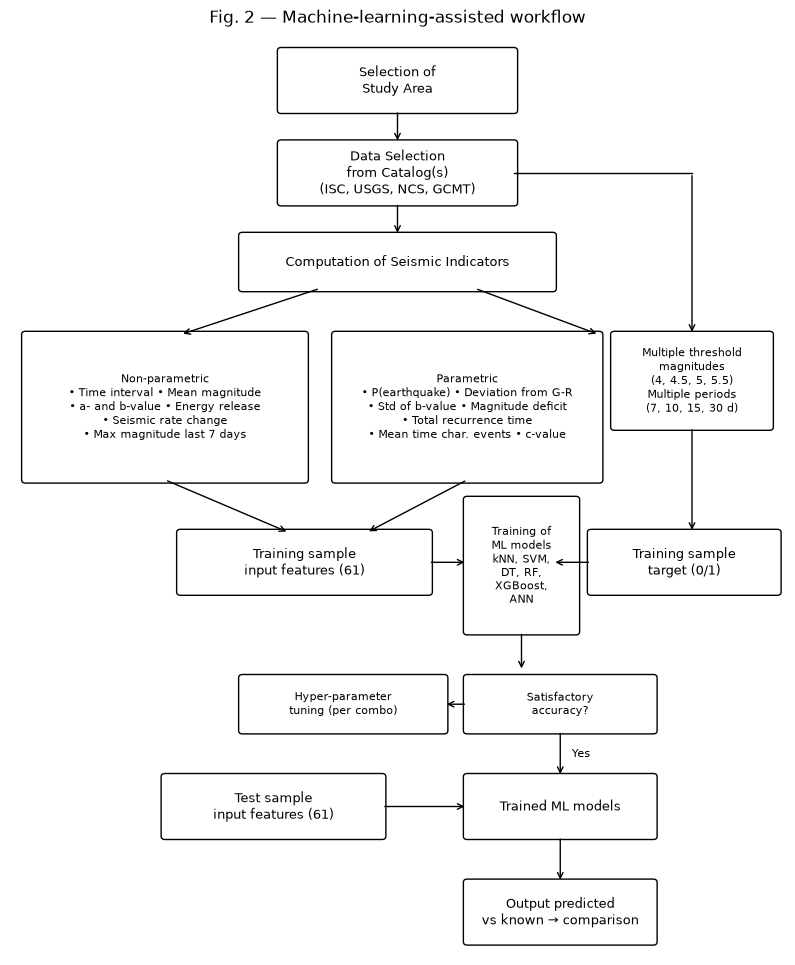

In [9]:
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(10, 12)); ax.axis('off'); ax.set_xlim(0, 10); ax.set_ylim(0, 14)
def box(x, y, w, h, t, fs=9):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.05', fc='white', ec='black')); ax.text(x + w/2, y + h/2, t, ha='center', va='center', fontsize=fs)
def arr(x1, y1, x2, y2): ax.annotate('', xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle='->'))
box(3.5, 12.8, 3, 0.9, 'Selection of\nStudy Area'); arr(5, 12.8, 5, 12.3)
box(3.5, 11.4, 3, 0.9, 'Data Selection\nfrom Catalog(s)\n(ISC, USGS, NCS, GCMT)'); arr(5, 11.4, 5, 10.9)
box(3, 10.1, 4, 0.8, 'Computation of Seismic Indicators'); arr(4, 10.1, 2.2, 9.4); arr(6, 10.1, 7.6, 9.4); ax.plot([6.5, 8.8], [11.85, 11.85], 'k-', lw=1); arr(8.8, 11.85, 8.8, 9.4)
box(0.2, 7.2, 3.6, 2.2, 'Non-parametric\n• Time interval • Mean magnitude\n• a- and b-value • Energy release\n• Seismic rate change\n• Max magnitude last 7 days', 8)
box(4.2, 7.2, 3.4, 2.2, 'Parametric\n• P(earthquake) • Deviation from G-R\n• Std of b-value • Magnitude deficit\n• Total recurrence time\n• Mean time char. events • c-value', 8)
box(7.8, 8.0, 2.0, 1.4, 'Multiple threshold\nmagnitudes\n(4, 4.5, 5, 5.5)\nMultiple periods\n(7, 10, 15, 30 d)', 8)
arr(2, 7.2, 3.6, 6.4); arr(5.9, 7.2, 4.6, 6.4); arr(8.8, 8.0, 8.8, 6.4)
box(2.2, 5.5, 3.2, 0.9, 'Training sample\ninput features (61)'); box(7.5, 5.5, 2.4, 0.9, 'Training sample\ntarget (0/1)'); arr(5.4, 5.95, 5.9, 5.95); arr(7.5, 5.95, 7.0, 5.95)
box(5.9, 4.9, 1.4, 2.0, 'Training of\nML models\nkNN, SVM,\nDT, RF,\nXGBoost,\nANN', 8); arr(6.6, 4.9, 6.6, 4.3)
box(3.0, 3.4, 2.6, 0.8, 'Hyper-parameter\ntuning (per combo)', 8); box(5.9, 3.4, 2.4, 0.8, 'Satisfactory\naccuracy?', 8); arr(5.9, 3.8, 5.6, 3.8)
arr(7.1, 3.4, 7.1, 2.7); ax.text(7.25, 3.0, 'Yes', fontsize=8)
box(5.9, 1.8, 2.4, 0.9, 'Trained ML models'); box(2.0, 1.8, 2.8, 0.9, 'Test sample\ninput features (61)'); arr(4.8, 2.25, 5.9, 2.25)
arr(7.1, 1.8, 7.1, 1.1); box(5.9, 0.2, 2.4, 0.9, 'Output predicted\nvs known → comparison'); 
plt.title('Fig. 2 — Machine-learning-assisted workflow'); plt.savefig(f'{FIG_DIR}/Fig2_workflow.png', dpi=200, bbox_inches='tight'); plt.show()

### A3. Fig. 4 / S1–S3 — full correlation matrix of the 61 input features (plain heatmap)
Full square matrix (both triangles), red = positive, blue = negative, same style as your `feature_correlation_matrix.png`. The matrix is window-independent (features don't depend on the 7/10/15/30-day target), so the same figure is saved as Fig. 4 and as S1–S3 copies. Set `EQ_CORR_ANNOT=1` to print the correlation number inside every cell.

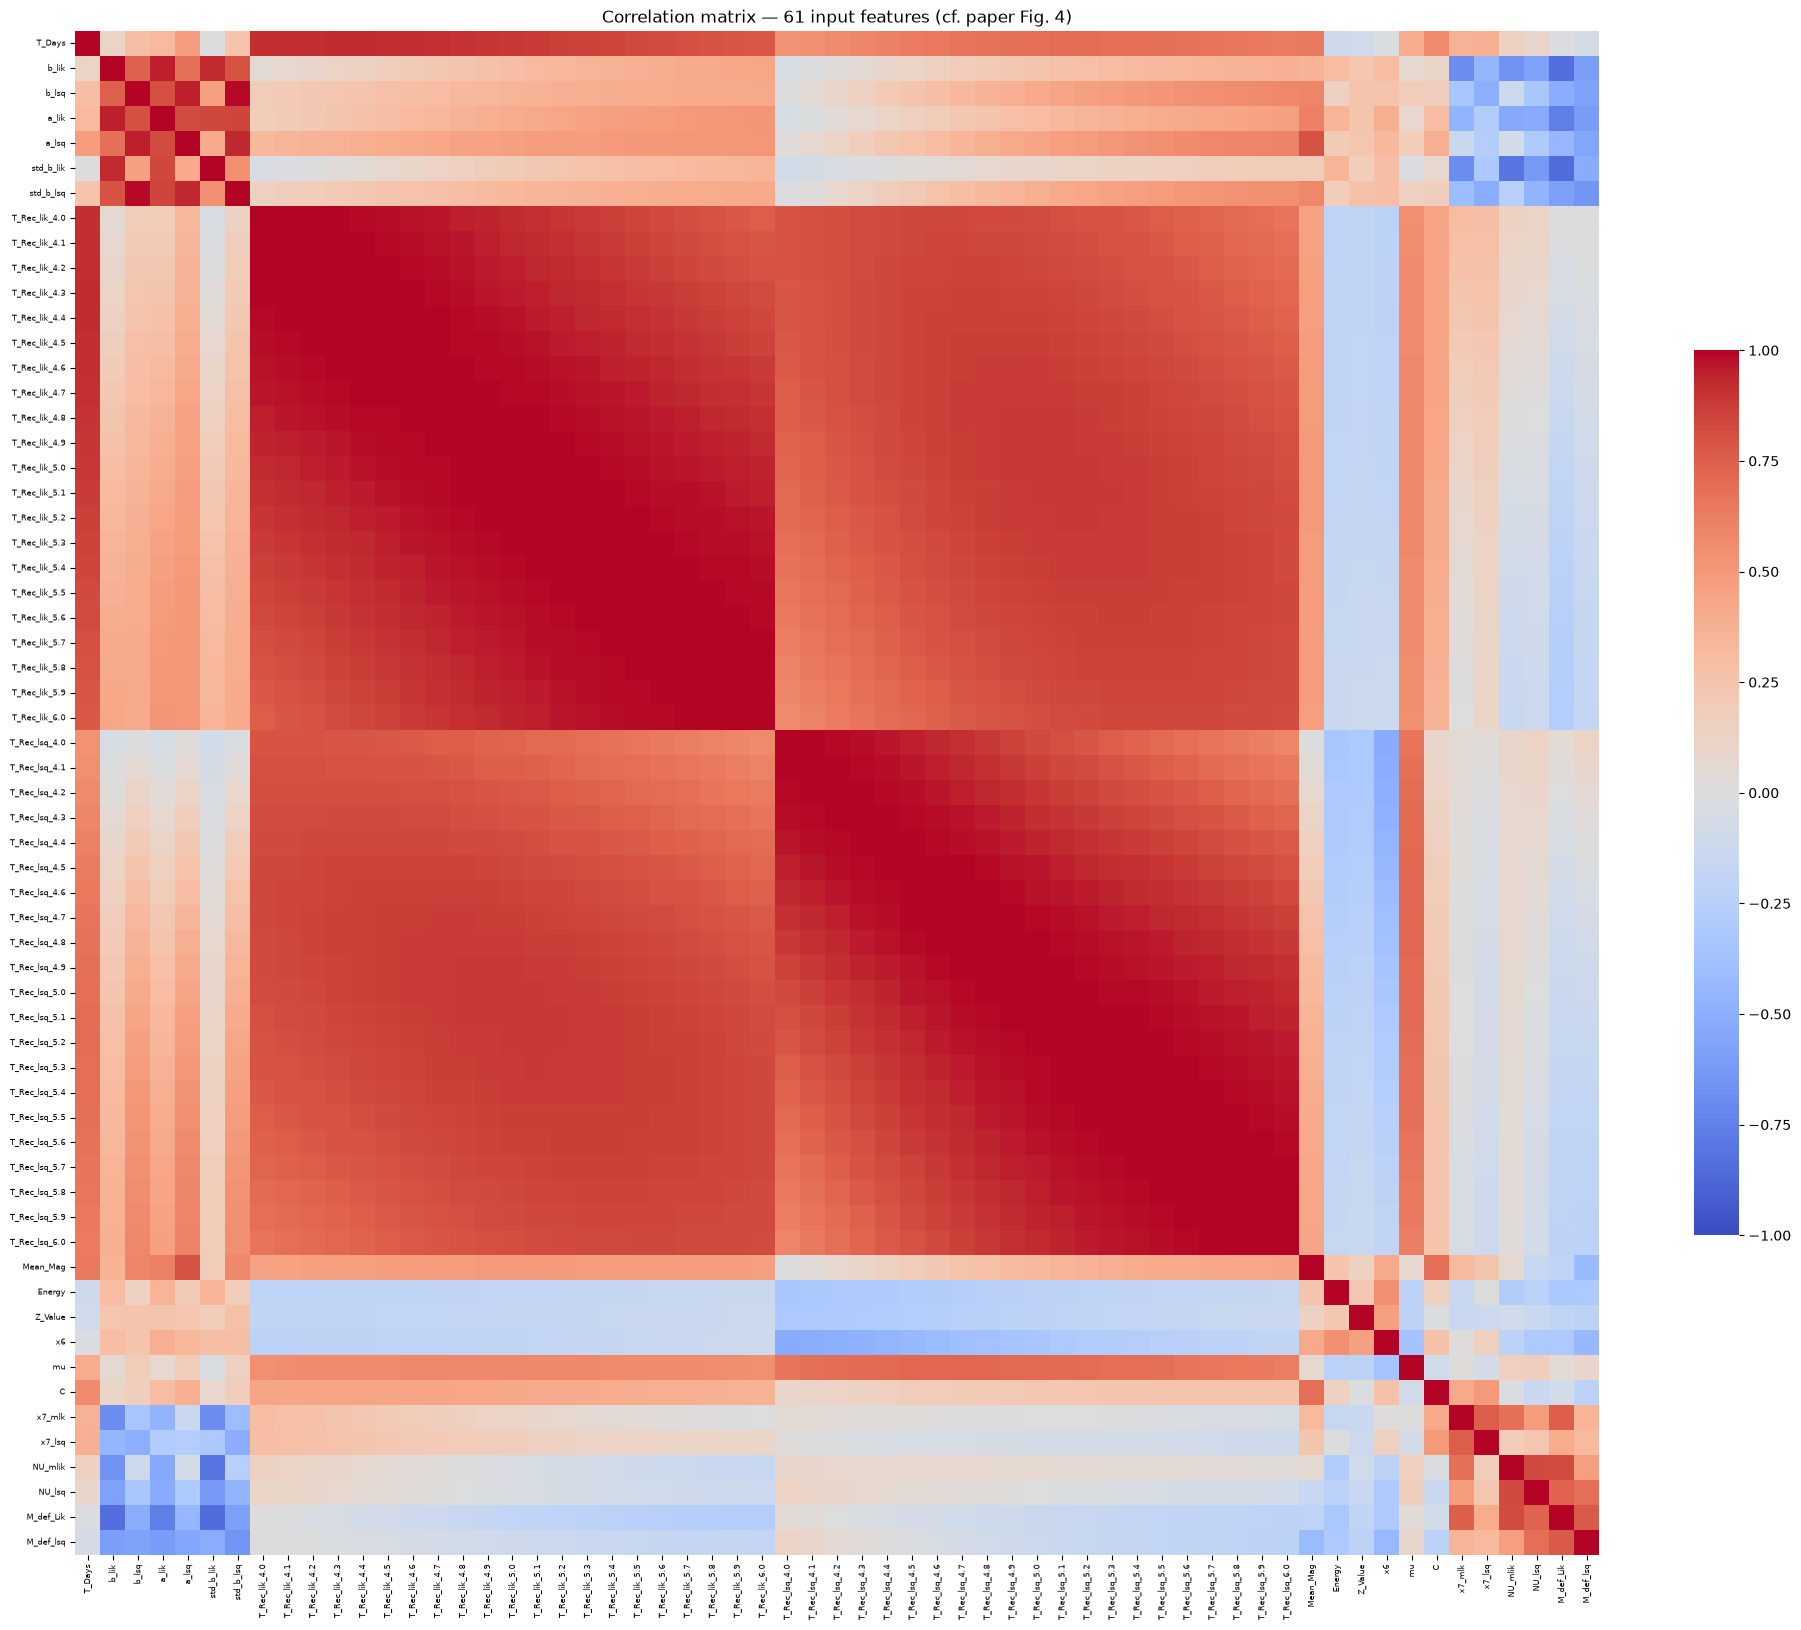

In [10]:
CORR_ANNOT = os.environ.get('EQ_CORR_ANNOT', '0') == '1'
corr = feat_df_clean[FEATURE_COLS].corr()
corr.to_csv(f'{FIG_DIR}/Fig4_correlation_matrix.csv'); corr.round(2).to_excel(f'{FIG_DIR}/Fig4_correlation_matrix.xlsx')
plt.figure(figsize=(20, 18))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, square=True, cbar_kws={'shrink': .5},
            annot=CORR_ANNOT, fmt='.2f', annot_kws={'size': 3})
plt.title('Correlation matrix — 61 input features (cf. paper Fig. 4)')
plt.xticks(fontsize=6, rotation=90); plt.yticks(fontsize=6, rotation=0)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/Fig4_correlation_matrix.png', dpi=200); plt.savefig(f'{FIG_DIR}/Fig4_correlation_matrix.pdf'); plt.show()
for d, no in [(10, 'S1'), (15, 'S2'), (30, 'S3')]:      # identical matrix: features are window-independent
    shutil.copy(f'{FIG_DIR}/Fig4_correlation_matrix.png', f'{FIG_DIR}/Fig{no}_correlation_matrix_{d}d.png')

### A4. Fig. 5 / 6 — **Boruta-SHAP** feature ranking (training set and test set)
Implementation follows the paper's Appendix 1: (1) every feature gets a *shadow* copy with its values randomly permuted; (2) a RandomForest is trained on real + shadow features; (3) **SHAP** values (Shapley, TreeExplainer) give each feature's importance = mean |SHAP|; (4) a real feature scores a *hit* when its importance beats the **best shadow feature**; (5) after several trials a binomial test marks each feature **Confirmed / Tentative / Rejected**; (6) final ranking = mean |SHAP| of the features.
Done separately on the training and test portions (as in the paper), for each threshold (7-day window; `EQ_BORUTA_ALL=1` for all windows).

Boruta-SHAP done: window 7d, thr>=4.0, train
Boruta-SHAP done: window 7d, thr>=4.0, test
Boruta-SHAP done: window 7d, thr>=4.5, train
Boruta-SHAP done: window 7d, thr>=4.5, test
Boruta-SHAP done: window 7d, thr>=5.0, train
Boruta-SHAP done: window 7d, thr>=5.0, test
Boruta-SHAP done: window 7d, thr>=5.5, train
Boruta-SHAP done: window 7d, thr>=5.5, test


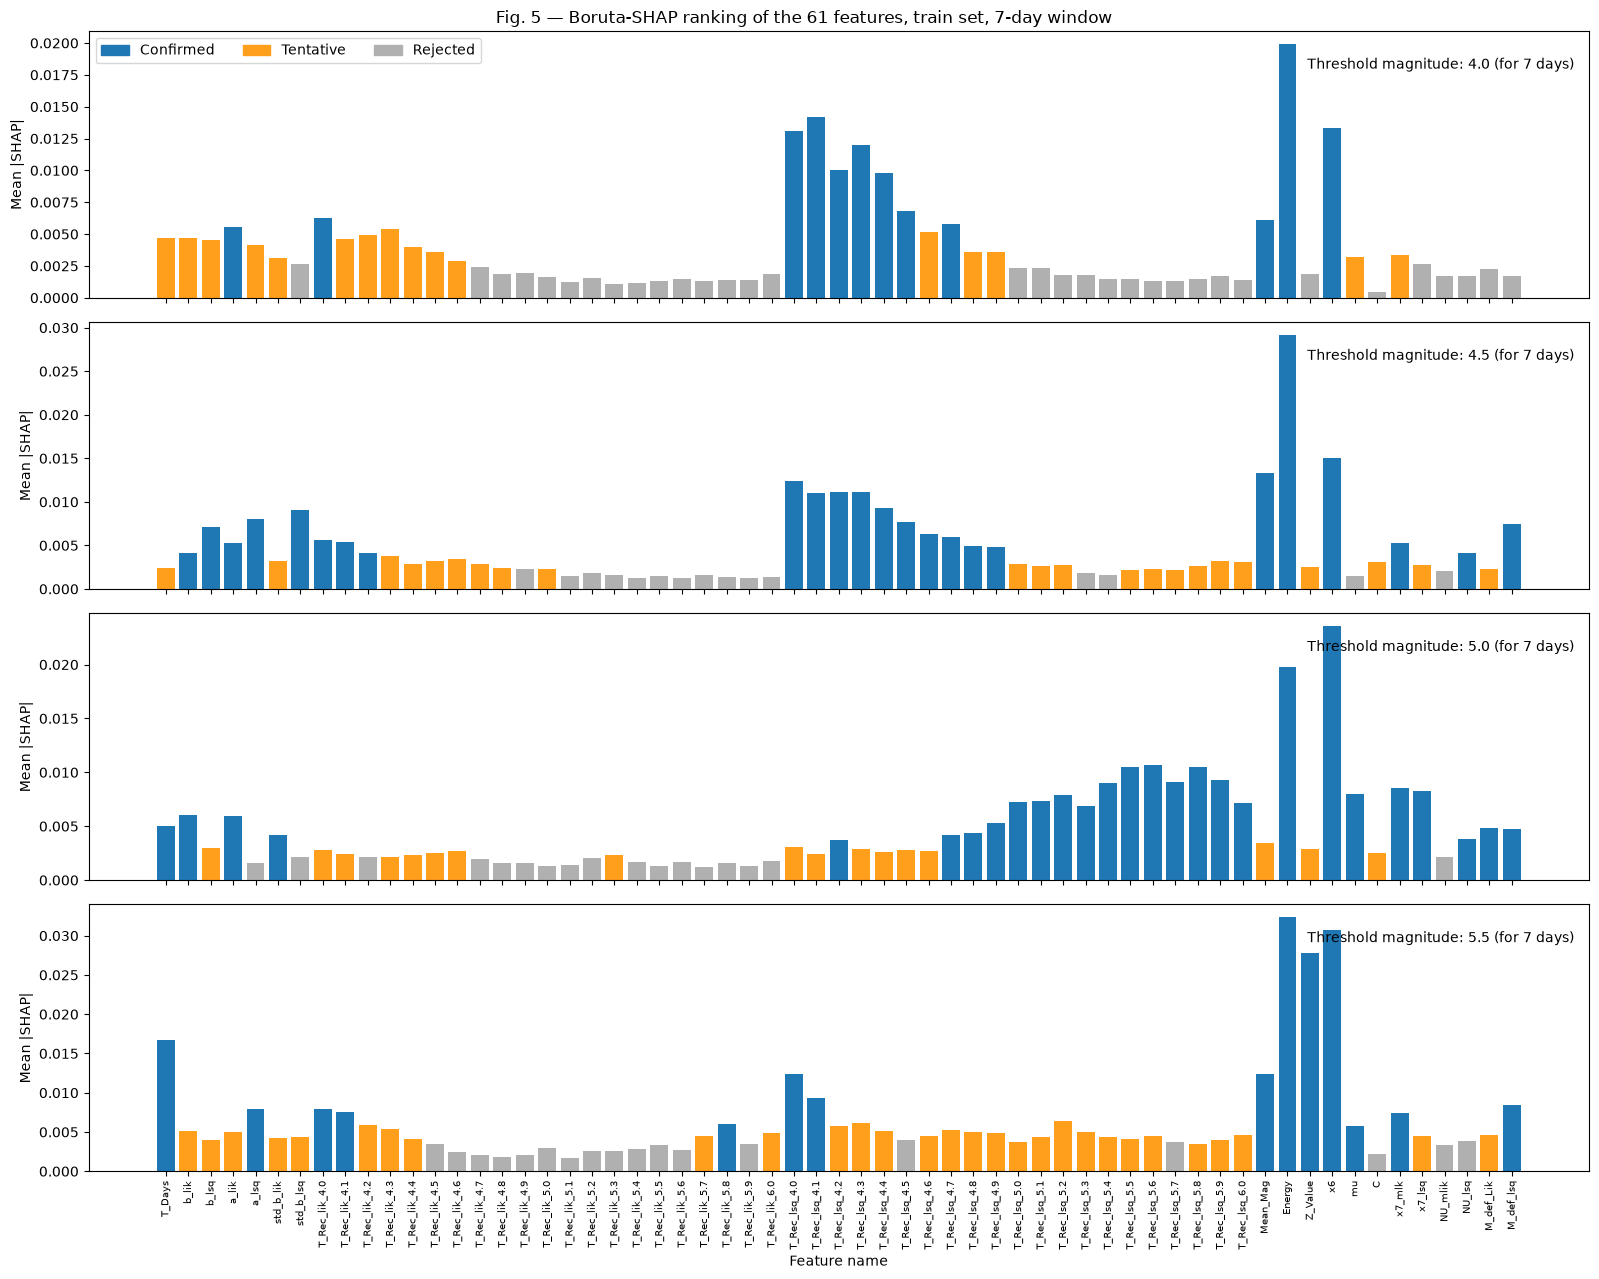

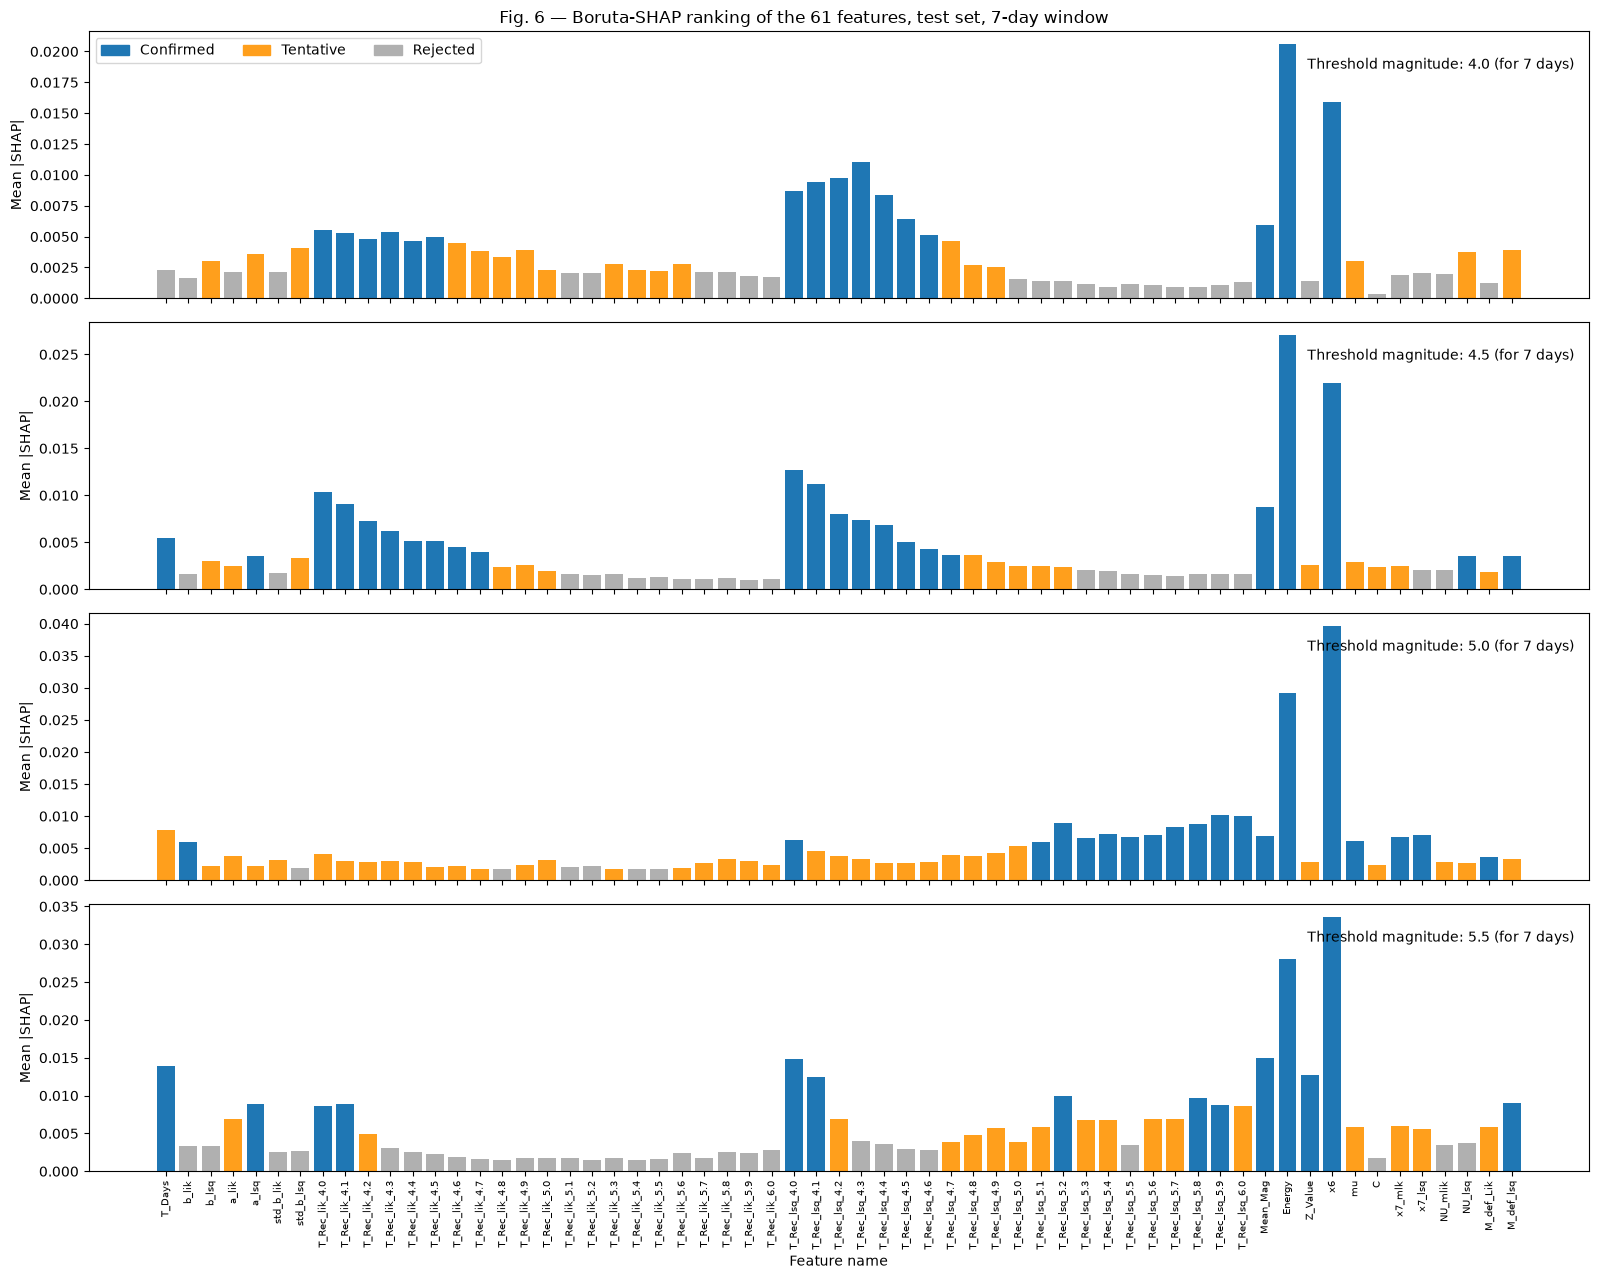

,Window,Threshold,Set,Top-10 features (rank order),# Confirmed,# Tentative,# Rejected
0,7,4.0,train,Energy > T_Rec_lsq_4.1 > x6 > T_Rec_lsq_4.0 > ...,12,16,33
1,7,4.0,test,Energy > x6 > T_Rec_lsq_4.3 > T_Rec_lsq_4.2 > ...,16,18,27
2,7,4.5,train,Energy > x6 > Mean_Mag > T_Rec_lsq_4.0 > T_Rec...,24,22,15
3,7,4.5,test,Energy > x6 > T_Rec_lsq_4.0 > T_Rec_lsq_4.1 > ...,23,16,22
4,7,5.0,train,x6 > Energy > T_Rec_lsq_5.6 > T_Rec_lsq_5.5 > ...,27,17,17
5,7,5.0,test,x6 > Energy > T_Rec_lsq_5.9 > T_Rec_lsq_6.0 > ...,19,36,6
6,7,5.5,train,Energy > x6 > Z_Value > T_Days > T_Rec_lsq_4.0...,14,29,18
7,7,5.5,test,x6 > Energy > Mean_Mag > T_Rec_lsq_4.0 > T_Day...,14,17,30


In [11]:
def _shap_importance(rf, Xc):
    sv = shap.TreeExplainer(rf).shap_values(Xc, check_additivity=False)
    if isinstance(sv, list): sv = sv[1]
    elif np.ndim(sv) == 3:   sv = sv[:, :, 1]
    return np.abs(sv).mean(axis=0)

def boruta_shap(X, y, names, n_trials=BORUTA_TRIALS, seed=RNG_SEED, max_rows=3000, shap_rows=800, alpha=0.05):
    rng = np.random.RandomState(seed); p = X.shape[1]
    if len(y) > max_rows:
        idx = rng.choice(len(y), max_rows, replace=False); X, y = X[idx], y[idx]
    hits = np.zeros(p, int); imp_hist = []
    for t in range(n_trials):
        shadow = np.column_stack([rng.permutation(X[:, j]) for j in range(p)])
        Xc = np.hstack([X, shadow])
        rf = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=2, class_weight='balanced',
                                    n_jobs=-1, random_state=seed + t).fit(Xc, y)
        sidx = rng.choice(len(y), min(shap_rows, len(y)), replace=False)
        imp = _shap_importance(rf, Xc[sidx]); real, shd = imp[:p], imp[p:]
        hits += (real > shd.max()); imp_hist.append(real)
    status = []
    for h in hits:
        up = binomtest(int(h), n_trials, 0.5, alternative='greater').pvalue
        lo = binomtest(int(h), n_trials, 0.5, alternative='less').pvalue
        status.append('Confirmed' if up < alpha else 'Rejected' if lo < alpha else 'Tentative')
    df = pd.DataFrame({'Feature': names, 'Hits': hits, 'Status': status, 'MeanAbsSHAP': np.mean(imp_hist, 0)})
    df['Rank'] = df['MeanAbsSHAP'].rank(ascending=False, method='first').astype(int)
    return df

def run_boruta(days):
    out = {}
    for thr in THRESHOLDS:
        for phase in ['train', 'test']:
            f = f'{ART_DIR}/boruta_{days}_{thr}_{phase}.joblib'
            if os.path.exists(f): out[(thr, phase)] = joblib.load(f); continue
            labels = make_labels(raw_df, feat_df_clean, days, thr)
            X_tr, y_tr, X_te, y_te = split_train_test(feat_df_clean, labels)
            X, y = (X_tr, y_tr) if phase == 'train' else (X_te, y_te)
            out[(thr, phase)] = boruta_shap(X, y, FEATURE_COLS); joblib.dump(out[(thr, phase)], f)
            print(f'Boruta-SHAP done: window {days}d, thr>={thr}, {phase}')
    return out

COL = {'Confirmed': '#1f77b4', 'Tentative': '#ff9f1c', 'Rejected': '#b0b0b0'}
def plot_boruta(res, days, phase, fig_no):
    fig, axes = plt.subplots(4, 1, figsize=(16, 13), sharex=True)
    for ax, thr in zip(axes, THRESHOLDS):
        d = res[(thr, phase)]
        ax.bar(range(len(d)), d['MeanAbsSHAP'], color=[COL[s] for s in d['Status']])
        ax.set_ylabel('Mean |SHAP|'); ax.text(0.99, 0.9, f'Threshold magnitude: {thr} (for {days} days)', transform=ax.transAxes, ha='right', va='top')
    axes[-1].set_xticks(range(len(FEATURE_COLS))); axes[-1].set_xticklabels(FEATURE_COLS, rotation=90, fontsize=7)
    axes[-1].set_xlabel('Feature name')
    from matplotlib.patches import Patch
    axes[0].legend(handles=[Patch(color=c, label=k) for k, c in COL.items()], loc='upper left', ncol=3)
    fig.suptitle(f'Fig. {fig_no} — Boruta-SHAP ranking of the 61 features, {phase} set, {days}-day window'); plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/Fig{fig_no}_BorutaSHAP_{phase}_{days}d.png', dpi=200); plt.show()

for days in (WINDOWS if BORUTA_ALL else [7]):
    res = run_boruta(days)
    plot_boruta(res, days, 'train', '5' if days == 7 else f'5_{days}d'); plot_boruta(res, days, 'test', '6' if days == 7 else f'6_{days}d')
    rows = []
    for thr in THRESHOLDS:
        for phase in ['train', 'test']:
            d = res[(thr, phase)].sort_values('Rank')
            rows.append({'Window': days, 'Threshold': thr, 'Set': phase, 'Top-10 features (rank order)': ' > '.join(d['Feature'].head(10)),
                         '# Confirmed': int((d.Status == 'Confirmed').sum()), '# Tentative': int((d.Status == 'Tentative').sum()), '# Rejected': int((d.Status == 'Rejected').sum())})
    bs = pd.DataFrame(rows); display(bs); bs.to_csv(f'{FIG_DIR}/BorutaSHAP_summary_{days}d.csv', index=False)
    pd.concat({f'{t}_{p}': res[(t, p)].set_index('Feature') for (t, p) in res}, axis=1).to_csv(f'{FIG_DIR}/BorutaSHAP_full_{days}d.csv')

## B. Train the six models for all combos (slow — **resumable**)
Every model's train-CV and test predictions/scores + best hyper-parameters are stored per combo in `paper_artifacts/`. If the run stops, run this cell again: finished models are skipped.

In [12]:
def svm_base():
    return Pipeline([('tf', TFS[0]), ('m', SVC(kernel='rbf', cache_size=1500, random_state=RNG_SEED))])
def ann_base(n_members=1):
    return Pipeline([('tf', TFS[0]), ('m', MLPEnsemble2(n_members=n_members, max_iter=MAX_ITER, random_state=RNG_SEED))])
def _cv5(): return StratifiedKFold(5, shuffle=True, random_state=RNG_SEED)

def art_classical(name, est, dist, X_tr, y_tr, X_te, y_te, inner):
    search = RandomizedSearchCV(est, dist, n_iter=N_ITER[name], scoring='accuracy', cv=inner,
                                random_state=RNG_SEED, n_jobs=-1, refit=True).fit(X_tr, y_tr)
    model = search.best_estimator_
    s_tr = cross_val_predict(model, X_tr, y_tr, cv=_cv5(), method='predict_proba', n_jobs=-1)[:, 1]
    s_te = model.predict_proba(X_te)[:, 1]
    return dict(params=search.best_params_, thr=0.5, s_tr=s_tr.astype('float32'), yp_tr=(s_tr > 0.5).astype('int8'),
                s_te=s_te.astype('float32'), yp_te=(s_te > 0.5).astype('int8'))

def art_svm(X_tr, y_tr, X_te, y_te, inner):
    dist = {'tf': TFS, 'm__C': loguniform(1, 1e4), 'm__gamma': loguniform(1e-4, 1), 'm__class_weight': [None, 'balanced']}
    search = HalvingRandomSearchCV(svm_base(), dist, n_candidates=SVM_CANDIDATES, factor=3, min_resources=1000, scoring='accuracy',
                                   cv=inner, random_state=RNG_SEED, n_jobs=-1, refit=True).fit(X_tr, y_tr)
    model = search.best_estimator_
    cvs = cross_val_predict(model, X_tr, y_tr, cv=_cv5(), method='decision_function', n_jobs=-1)
    t_use = best_threshold(cvs, y_tr) if SVM_TUNE_THRESHOLD else 0.0
    sc = model.decision_function(X_te)
    return dict(params=search.best_params_, thr=float(t_use), s_tr=cvs.astype('float32'), yp_tr=(cvs >= t_use).astype('int8'),
                s_te=sc.astype('float32'), yp_te=(sc >= t_use).astype('int8'))

def art_ann(X_tr, y_tr, X_te, y_te, inner):
    est = ann_base(SEARCH_MEMBERS)
    dist = {'tf': TFS, 'm__hidden_layer_sizes': HIDDEN, 'm__activation': ['relu', 'tanh'],
            'm__solver': ['adam', 'lbfgs'] if BIG else ['adam'], 'm__alpha': loguniform(1e-7, 1e-2),
            'm__learning_rate_init': loguniform(5e-4, 1e-2), 'm__batch_size': [128, 256, 512], 'm__oversample': [False, True]}
    Xs, ys = X_tr, y_tr
    if len(y_tr) > SEARCH_ROWS:
        Xs, _, ys, _ = train_test_split(X_tr, y_tr, train_size=SEARCH_ROWS, random_state=RNG_SEED, stratify=y_tr)
    search = RandomizedSearchCV(est, dist, n_iter=ANN_ITER, scoring='accuracy', cv=inner, random_state=RNG_SEED,
                                n_jobs=-1, refit=False).fit(Xs, ys)
    res = pd.DataFrame(search.cv_results_).sort_values('rank_test_score').head(TOP_K)
    plist = [{**p, 'm__n_members': ANN_MEMBERS} for p in res['params']]
    model = AvgProba(models=[clone(est).set_params(**p) for p in plist]).fit(X_tr, y_tr)
    one = clone(est).set_params(**{**plist[0], 'm__n_members': 1})
    s_tr = cross_val_predict(one, X_tr, y_tr, cv=StratifiedKFold(3, shuffle=True, random_state=RNG_SEED),
                             method='predict_proba', n_jobs=-1)[:, 1]
    s_te = model.predict_proba(X_te)[:, 1]
    return dict(params=plist, thr=0.5, s_tr=s_tr.astype('float32'), yp_tr=(s_tr > 0.5).astype('int8'),
                s_te=s_te.astype('float32'), yp_te=(s_te >= 0.5).astype('int8'))

t0 = time.time()
for days in [d for d in WINDOWS if d in WINDOWS_RUN]:
    for thr in THRESHOLDS:
        if COMBOS == 'weak' and thr >= 5.0: continue
        path = f'{ART_DIR}/{days}_{thr}.joblib'
        rec = joblib.load(path) if os.path.exists(path) else {'meta': {}, 'models': {}}
        todo = [m for m in MODEL_ORDER if m in RUN_MODELS and m not in rec['models']]
        if not todo: continue
        labels = make_labels(raw_df, feat_df_clean, days, thr)
        X_tr, y_tr, X_te, y_te = split_train_test(feat_df_clean, labels)
        rec['meta'] = dict(days=days, thr=thr, n_train=len(y_tr), n_pos=int(y_tr.sum()), n_neg=int((y_tr == 0).sum()),
                           n_test=len(y_te), y_tr=y_tr.astype('int8'), y_te=y_te.astype('int8'), spw=float((y_tr == 0).sum() / max(y_tr.sum(), 1)))
        inner = StratifiedKFold(SEARCH_CV, shuffle=True, random_state=RNG_SEED)
        for name in todo:
            if name in ('kNN', 'DT', 'RF', 'XGBoost'):
                est, dist = classical_specs(rec['meta']['spw'])[name]
                a = art_classical(name, est, dist, X_tr, y_tr, X_te, y_te, inner)
            elif name == 'SVM': a = art_svm(X_tr, y_tr, X_te, y_te, inner)
            else:               a = art_ann(X_tr, y_tr, X_te, y_te, inner)
            rec['models'][name] = a; joblib.dump(rec, path)
            print(f'[{time.time()-t0:7.1f}s] window={days:>2}d thr>={thr} {name:<8} train acc={accuracy_score(y_tr, a["yp_tr"])*100:.2f}  test acc={accuracy_score(y_te, a["yp_te"])*100:.2f}')
print('training stage finished')

[   69.9s] window= 7d thr>=4.0 kNN      train acc=76.93  test acc=78.78
[  309.2s] window= 7d thr>=4.0 SVM      train acc=87.20  test acc=87.42
[  345.0s] window= 7d thr>=4.0 DT       train acc=78.10  test acc=78.86
[  662.0s] window= 7d thr>=4.0 RF       train acc=81.08  test acc=82.61
[  784.9s] window= 7d thr>=4.0 XGBoost  train acc=84.86  test acc=86.94
[ 1090.0s] window= 7d thr>=4.0 ANN      train acc=82.72  test acc=87.34
[ 1149.8s] window= 7d thr>=4.5 kNN      train acc=78.46  test acc=79.34
[ 1379.3s] window= 7d thr>=4.5 SVM      train acc=87.90  test acc=89.56
[ 1412.9s] window= 7d thr>=4.5 DT       train acc=81.68  test acc=82.04
[ 1712.4s] window= 7d thr>=4.5 RF       train acc=84.22  test acc=85.44
[ 1876.4s] window= 7d thr>=4.5 XGBoost  train acc=87.87  test acc=88.98
[ 2124.0s] window= 7d thr>=4.5 ANN      train acc=84.93  test acc=89.43
[ 2170.0s] window= 7d thr>=5.0 kNN      train acc=88.97  test acc=90.15
[ 2317.1s] window= 7d thr>=5.0 SVM      train acc=94.55  test ac

## C. Everything the paper shows — from the stored predictions (train **and** test)

In [13]:
ART = {}
for f in sorted(os.listdir(ART_DIR)):
    if f.endswith('.joblib') and not f.startswith('boruta'):
        d, t = f[:-7].split('_'); ART[(int(d), float(t))] = joblib.load(f'{ART_DIR}/{f}')
WIN_PRESENT = sorted({d for d, _ in ART}); models = [m for m in MODEL_ORDER if any(m in r['models'] for r in ART.values())]
print('windows:', WIN_PRESENT, '| models:', models, '| combos stored:', len(ART))

def yy(rec, phase): return rec['meta']['y_tr'] if phase == 'Train' else rec['meta']['y_te']
def get_art(rec, name, phase):
    a = rec['models'][name]; return (a['yp_tr'], a['s_tr']) if phase == 'Train' else (a['yp_te'], a['s_te'])

rows = []
for (days, thr), rec in sorted(ART.items()):
    for name in models:
        if name not in rec['models']: continue
        for phase in ['Train', 'Test']:
            yp, sc = get_art(rec, name, phase)
            rows.append({'Phase': phase, 'Days': days, 'Threshold': thr, 'Model': name, **metrics_from_preds(yy(rec, phase), yp, sc)})
all_metrics = pd.DataFrame(rows)
train_summary = all_metrics[all_metrics.Phase == 'Train'].drop(columns='Phase').reset_index(drop=True)
test_summary  = all_metrics[all_metrics.Phase == 'Test'].drop(columns='Phase').reset_index(drop=True)
all_metrics.to_csv(f'{FIG_DIR}/ALL_metrics_train_and_test.csv', index=False)

windows: [7, 10, 15, 30] | models: ['kNN', 'SVM', 'DT', 'RF', 'XGBoost', 'ANN'] | combos stored: 16


### C1. Tables 4–7 — TN, FP, FN, TP, Precision, Recall, F1, Accuracy, AUC (one table per window; train (CV) and test)

In [14]:
for k, days in enumerate(WIN_PRESENT):
    for phase in ['Train', 'Test']:
        t = all_metrics[(all_metrics.Phase == phase) & (all_metrics.Days == days)].drop(columns=['Phase', 'Days'])
        for c in ['Precision', 'Recall', 'F1', 'Accuracy', 'AUC']: t[c] = t[c].astype(float).round(4)
        t = t.sort_values(['Threshold', 'Model'], key=lambda s: s.map({m: i for i, m in enumerate(MODEL_ORDER)}) if s.name == 'Model' else s)
        print(f'\n=== Table {4+WINDOWS.index(days)} (paper numbering) — {days}-day window — {phase.upper()} {"(5-fold / 3-fold CV predictions)" if phase=="Train" else "(hold-out 25 %)"} ===')
        display(t.reset_index(drop=True)); t.to_csv(f'{FIG_DIR}/Table{4+WINDOWS.index(days)}_{days}d_{phase}.csv', index=False)
print('\nMean metrics per model (all combos):')
display(all_metrics.groupby(['Phase', 'Model'])[['Precision', 'Recall', 'F1', 'Accuracy', 'AUC']].mean().loc[[(p, m) for p in ['Train', 'Test'] for m in models]].round(4))


=== Table 4 (paper numbering) — 7-day window — TRAIN (5-fold / 3-fold CV predictions) ===


,Threshold,Model,TN,FP,FN,TP,Precision,Recall,F1,Accuracy,AUC
0,4.0,kNN,1524,1709,877,7098,0.8059,0.8900,0.8459,0.7693,0.8181
1,4.0,SVM,2412,821,614,7361,0.8997,0.9230,0.9112,0.8720,0.9070
2,4.0,DT,1862,1371,1084,6891,0.8341,0.8641,0.8488,0.7810,0.7944
3,4.0,RF,1501,1732,389,7586,0.8141,0.9512,0.8773,0.8108,0.8759
4,4.0,XGBoost,2159,1074,623,7352,0.8725,0.9219,0.8965,0.8486,0.9064
5,4.0,ANN,2167,1066,871,7104,0.8695,0.8908,0.8800,0.8272,0.8803
6,4.5,kNN,5121,687,1727,3673,0.8424,0.6802,0.7527,0.7846,0.8823
7,4.5,SVM,5196,612,744,4656,0.8838,0.8622,0.8729,0.8790,0.9092
8,4.5,DT,4910,898,1155,4245,0.8254,0.7861,0.8053,0.8168,0.8488
9,4.5,RF,5168,640,1129,4271,0.8697,0.7909,0.8284,0.8422,0.9311



=== Table 4 (paper numbering) — 7-day window — TEST (hold-out 25 %) ===


,Threshold,Model,TN,FP,FN,TP,Precision,Recall,F1,Accuracy,AUC
0,4.0,kNN,582,496,297,2362,0.8265,0.8883,0.8563,0.7878,0.8495
1,4.0,SVM,839,239,231,2428,0.9104,0.9131,0.9118,0.8742,0.9190
2,4.0,DT,578,500,290,2369,0.8257,0.8909,0.8571,0.7886,0.8212
3,4.0,RF,548,530,120,2539,0.8273,0.9549,0.8865,0.8261,0.8959
4,4.0,XGBoost,752,326,162,2497,0.8845,0.9391,0.9110,0.8694,0.9302
5,4.0,ANN,858,220,253,2406,0.9162,0.9049,0.9105,0.8734,0.9413
6,4.5,kNN,1692,245,527,1273,0.8386,0.7072,0.7673,0.7934,0.8955
7,4.5,SVM,1752,185,205,1595,0.8961,0.8861,0.8911,0.8956,0.9245
8,4.5,DT,1648,289,382,1418,0.8307,0.7878,0.8087,0.8204,0.8507
9,4.5,RF,1739,198,346,1454,0.8801,0.8078,0.8424,0.8544,0.9361



=== Table 5 (paper numbering) — 10-day window — TRAIN (5-fold / 3-fold CV predictions) ===


,Threshold,Model,TN,FP,FN,TP,Precision,Recall,F1,Accuracy,AUC
0,4.0,kNN,1152,1102,692,8262,0.8823,0.9227,0.9021,0.8399,0.8611
1,4.0,SVM,1544,710,362,8592,0.9237,0.9596,0.9413,0.9044,0.9186
2,4.0,DT,1252,1002,925,8029,0.8890,0.8967,0.8929,0.8281,0.7937
3,4.0,RF,751,1503,137,8817,0.8544,0.9847,0.9149,0.8537,0.8946
4,4.0,XGBoost,1391,863,360,8594,0.9087,0.9598,0.9336,0.8909,0.9243
5,4.0,ANN,1424,830,561,8393,0.9100,0.9373,0.9235,0.8759,0.8978
6,4.5,kNN,4154,820,1507,4727,0.8522,0.7583,0.8025,0.7924,0.8893
7,4.5,SVM,4314,660,506,5728,0.8967,0.9188,0.9076,0.8960,0.9418
8,4.5,DT,4008,966,1216,5018,0.8386,0.8049,0.8214,0.8053,0.8488
9,4.5,RF,4423,551,1149,5085,0.9022,0.8157,0.8568,0.8483,0.9353


... (8 outputs left out)


=== Table 7 (paper numbering) — 30-day window — TEST (hold-out 25 %) ===


,Threshold,Model,TN,FP,FN,TP,Precision,Recall,F1,Accuracy,AUC
0,4.0,kNN,26,68,16,3627,0.9816,0.9956,0.9886,0.9775,0.9031
1,4.0,SVM,60,34,132,3511,0.9904,0.9638,0.9769,0.9556,0.8899
2,4.0,DT,8,86,14,3629,0.9769,0.9962,0.9864,0.9732,0.7523
3,4.0,RF,15,79,11,3632,0.9787,0.9970,0.9878,0.9759,0.9524
4,4.0,XGBoost,39,55,17,3626,0.9851,0.9953,0.9902,0.9807,0.9586
5,4.0,ANN,43,51,13,3630,0.9861,0.9964,0.9913,0.9829,0.9660
6,4.5,kNN,434,189,142,2972,0.9402,0.9544,0.9473,0.9114,0.9434
7,4.5,SVM,549,74,61,3053,0.9763,0.9804,0.9784,0.9639,0.9636
8,4.5,DT,433,190,193,2921,0.9389,0.9380,0.9385,0.8975,0.8668
9,4.5,RF,536,87,188,2926,0.9711,0.9396,0.9551,0.9264,0.9604



Mean metrics per model (all combos):


Precision  Recall      F1  Accuracy     AUC
Phase Model                                               
Train kNN         0.9079  0.7963  0.8434    0.8821  0.9201
      SVM         0.9321  0.9281  0.9299    0.9390  0.9430
      DT          0.8760  0.8336  0.8532    0.8825  0.8604
      RF          0.9061  0.8862  0.8946    0.9102  0.9485
      XGBoost     0.9372  0.9174  0.9267    0.9354  0.9640
      ANN         0.9064  0.9027  0.9040    0.9193  0.9480
Test  kNN         0.9170  0.8182  0.8612    0.8927  0.9333
      SVM         0.9427  0.9369  0.9396    0.9471  0.9523
      DT          0.8864  0.8405  0.8615    0.8897  0.8730
      RF          0.9147  0.8973  0.9047    0.9179  0.9587
      XGBoost     0.9430  0.9299  0.9361    0.9434  0.9735
      ANN         0.9445  0.9344  0.9392    0.9469  0.9774

### C2. Table 2 (training sample / folds) and Table 3 (hyper-parameters) — yours

In [15]:
t2 = pd.DataFrame([{'Days': d, 'Threshold': t, 'Training sample (all rows, no under-sampling)': r['meta']['n_train'],
                    'class-1': r['meta']['n_pos'], 'class-0': r['meta']['n_neg'], 'Test sample': r['meta']['n_test'],
                    'CV folds (train accuracy)': '5 (ANN: 3)'} for (d, t), r in sorted(ART.items())])
print('Table 2 (yours) — the paper under-sampled thresholds 4.5/5.0/5.5; here every row is kept'); display(t2); t2.to_csv(f'{FIG_DIR}/Table2_training_samples.csv', index=False)

def fmt_params(p):
    if isinstance(p, list): p = p[0]
    return ', '.join(f"{k.split('__')[-1]}={(type(v).__name__ if hasattr(v, 'fit') else (round(v, 5) if isinstance(v, float) else v))}" for k, v in sorted(p.items()))
t3 = pd.DataFrame([{'Days': d, 'Threshold': t, 'Model': m, 'Best hyper-parameters': fmt_params(r['models'][m]['params'])}
                   for (d, t), r in sorted(ART.items()) for m in models if m in r['models']])
t3.to_csv(f'{FIG_DIR}/Table3_hyperparameters_all_combos.csv', index=False)
pd.set_option('display.max_colwidth', 250)
print('Table 3 (yours, per-combo tuned; 7-day shown here, all combos in CSV)'); display(t3[t3.Days == WIN_PRESENT[0]].reset_index(drop=True))

Table 2 (yours) — the paper under-sampled thresholds 4.5/5.0/5.5; here every row is kept


,Days,Threshold,"Training sample (all rows, no under-sampling)",class-1,class-0,Test sample,CV folds (train accuracy)
0,7,4.0,11208,7975,3233,3737,5 (ANN: 3)
1,7,4.5,11208,5400,5808,3737,5 (ANN: 3)
2,7,5.0,11208,2773,8435,3737,5 (ANN: 3)
3,7,5.5,11208,1162,10046,3737,5 (ANN: 3)
4,10,4.0,11208,8954,2254,3737,5 (ANN: 3)
5,10,4.5,11208,6234,4974,3737,5 (ANN: 3)
6,10,5.0,11208,3214,7994,3737,5 (ANN: 3)
7,10,5.5,11208,1457,9751,3737,5 (ANN: 3)
8,15,4.0,11208,9962,1246,3737,5 (ANN: 3)
9,15,4.5,11208,7437,3771,3737,5 (ANN: 3)


Table 3 (yours, per-combo tuned; 7-day shown here, all combos in CSV)


,Days,Threshold,Model,Best hyper-parameters
0,7,4.0,kNN,"n_neighbors=13, p=1, weights=uniform"
1,7,4.0,SVM,"C=7.06897, class_weight=balanced, gamma=0.93078, tf=QuantileTransformer"
2,7,4.0,DT,"class_weight=None, criterion=gini, max_depth=17, min_samples_leaf=1, min_samples_split=8"
3,7,4.0,RF,"class_weight=None, max_depth=15, max_features=sqrt, min_samples_leaf=1, min_samples_split=11, n_estimators=287"
4,7,4.0,XGBoost,"colsample_bytree=0.69758, learning_rate=0.18753, max_depth=9, min_child_weight=7, n_estimators=294, reg_alpha=0.52083, reg_lambda=2.90293, scale_pos_weight=1.0, subsample=0.69434"
5,7,4.0,ANN,"activation=tanh, alpha=4e-05, batch_size=128, hidden_layer_sizes=(128, 64), learning_rate_init=0.00657, n_members=3, oversample=False, solver=adam, tf=QuantileTransformer"
6,7,4.5,kNN,"n_neighbors=10, p=1, weights=uniform"
7,7,4.5,SVM,"C=1216.41394, class_weight=None, gamma=0.50723, tf=PowerTransformer"
8,7,4.5,DT,"class_weight=None, criterion=gini, max_depth=17, min_samples_leaf=1, min_samples_split=8"
9,7,4.5,RF,"class_weight=balanced, max_depth=19, max_features=sqrt, min_samples_leaf=3, min_samples_split=6, n_estimators=234"


### C3. Table 8 / 9 — accuracy: yours vs the base paper (train and test), mean accuracy

In [16]:
MODEL_ORDER = ['kNN', 'SVM', 'DT', 'RF', 'XGBoost', 'ANN']
# Paper values transcribed from Table 8 (train) and Table 9 (test); columns = kNN, SVM, DT, RF, XGBoost, ANN
paper_test = {
 (4.0,7):[78.7473,80.2730,82.1734,81.8255,90.6049,87.5803],(4.0,10):[86.8308,87.5267,85.7602,91.7559,93.5492,88.5439],
 (4.0,15):[89.3469,93.0139,92.9068,94.5128,97.0824,95.9582],(4.0,30):[98.9026,99.0364,98.5814,99.1167,99.4111,98.5814],
 (4.5,7):[73.8223,74.3576,75.6959,78.2387,83.6188,85.9743],(4.5,10):[77.0878,77.3822,79.3629,81.3169,90.6852,87.1788],
 (4.5,15):[79.9518,83.2441,83.2708,85.0642,92.2377,89.5878],(4.5,30):[89.106,89.0257,91.7291,91.6221,94.4593,95.8244],
 (5.0,7):[87.1520,87.2056,88.6777,87.8479,92.2644,94.4058],(5.0,10):[84.7163,84.6627,84.8768,88.0888,91.8897,93.9239],
 (5.0,15):[86.2687,86.8576,87.2591,89.6146,94.3790,92.6659],(5.0,30):[80.3801,85.4657,86.4561,88.2227,93.8704,92.5321],
 (5.5,7):[92.9068,93.2816,93.3083,95.2088,97.1627,98.2334],(5.5,10):[92.6392,94.3255,95.1820,96.6809,97.4572,98.4208],
 (5.5,15):[93.4957,93.3351,94.4325,95.5835,97.9122,96.9754],(5.5,30):[89.9625,91.2473,89.6948,94.4593,95.9850,97.3769]}
paper_train = {
 (4.0,7):[75,76.2,77.2,78.1,84.7,84.2],(4.0,10):[81.3,83.1,80.5,88.4,88.5,84],(4.0,15):[85.3,89.4,91,90.7,93.1,93.2],(4.0,30):[97.4,97.6,97.2,97.5,98,97.3],
 (4.5,7):[72.9,74.2,75,77.9,83.8,84.7],(4.5,10):[74.1,76.5,77.7,80.4,86.3,86.4],(4.5,15):[76.8,80.9,81,82.3,89,88.4],(4.5,30):[86.4,87.2,89.3,91,93.8,93.6],
 (5.0,7):[80,81.3,82.7,85.6,89.3,89.1],(5.0,10):[77.4,79.1,80.4,85.5,89.7,89.5],(5.0,15):[81.4,82.3,82.1,85.3,90.5,90.7],(5.0,30):[78.1,81.4,82.4,84.6,91.9,90.7],
 (5.5,7):[87.7,89.8,90.5,92.5,94.9,93.9],(5.5,10):[88.5,90.1,91.1,94,95.5,94.1],(5.5,15):[89.3,90.5,90,93.2,94.2,94.8],(5.5,30):[84.5,88.3,86.5,92.6,94,93.8]}
paper_test_df  = pd.DataFrame(paper_test,  index=MODEL_ORDER).T
paper_train_df = pd.DataFrame(paper_train, index=MODEL_ORDER).T



In [17]:
full_idx = pd.MultiIndex.from_product([THRESHOLDS, WINDOWS], names=['Threshold', 'Days'])
paper_test_df.index = full_idx; paper_train_df.index = full_idx
models = [m for m in MODEL_ORDER if m in test_summary.Model.unique()]
mine_test  = (test_summary.pivot_table(index=['Threshold','Days'], columns='Model', values='Accuracy') * 100)[models]
mine_train = (train_summary.pivot_table(index=['Threshold','Days'], columns='Model', values='Accuracy') * 100)[models]
pt, ptr = paper_test_df.reindex(mine_test.index)[models], paper_train_df.reindex(mine_train.index)[models]

print('TEST accuracy (%) — YOURS'); display(mine_test.round(2))
print('TEST accuracy (%) — BASE PAPER (Table 9)'); display(pt.round(2))
print('Difference (yours − paper), pp'); display((mine_test - pt).round(2))

summary = pd.DataFrame({'Paper Train (%)': ptr.mean(), 'Yours Train (CV) (%)': mine_train.mean(),
                        'Paper Test (%)': pt.mean(), 'Yours Test (%)': mine_test.mean()}).round(2)
summary['Train gain (pp)'] = (summary['Yours Train (CV) (%)'] - summary['Paper Train (%)']).round(2)
summary['Test gain (pp)']  = (summary['Yours Test (%)'] - summary['Paper Test (%)']).round(2)
summary['Cells beating paper (test)'] = [f"{int((mine_test[m] > pt[m]).sum())}/{len(mine_test)}" for m in models]
print('\nMEAN over combos'); display(summary)
print(f"Overall mean TEST : yours {mine_test.values.mean():.2f}%  vs paper {pt.values.mean():.2f}%  ({mine_test.values.mean()-pt.values.mean():+.2f} pp)")
print(f"Overall mean TRAIN: yours {mine_train.values.mean():.2f}%  vs paper {ptr.values.mean():.2f}%  ({mine_train.values.mean()-ptr.values.mean():+.2f} pp)")
print('Models that beat the paper on mean test accuracy:', [m for m in models if summary.loc[m, 'Test gain (pp)'] > 0])

TEST accuracy (%) — YOURS


Model             kNN    SVM     DT     RF  XGBoost    ANN
Threshold Days                                            
4.0       7     78.78  87.42  78.86  82.61    86.94  87.34
          10    84.29  91.09  83.38  85.84    89.88  90.13
          15    91.33  94.51  89.97  90.53    93.90  94.25
          30    97.75  95.56  97.32  97.59    98.07  98.29
4.5       7     79.34  89.56  82.04  85.44    88.98  89.43
          10    81.40  91.95  81.70  86.51    90.05  91.01
          15    84.19  93.23  85.36  88.79    91.70  92.05
          30    91.14  96.39  89.75  92.64    95.21  96.23
5.0       7     90.15  95.66  90.82  92.88    95.32  95.93
          10    88.60  95.00  88.65  92.35    95.16  95.93
          15    88.20  95.56  87.77  91.97    95.26  95.58
          30    88.44  96.07  86.27  91.95    95.26  95.72
5.5       7     97.14  98.47  97.35  98.10    98.58  98.29
          10    96.57  98.21  96.49  97.48    98.21  98.34
          15    96.25  98.50  95.08  97.35    98.64  98.50
          30    94.76  98.23  92.75  96.60    98.23  98.10

TEST accuracy (%) — BASE PAPER (Table 9)


kNN    SVM     DT     RF  XGBoost    ANN
Threshold Days                                            
4.0       7     78.75  80.27  82.17  81.83    90.60  87.58
          10    86.83  87.53  85.76  91.76    93.55  88.54
          15    89.35  93.01  92.91  94.51    97.08  95.96
          30    98.90  99.04  98.58  99.12    99.41  98.58
4.5       7     73.82  74.36  75.70  78.24    83.62  85.97
          10    77.09  77.38  79.36  81.32    90.69  87.18
          15    79.95  83.24  83.27  85.06    92.24  89.59
          30    89.11  89.03  91.73  91.62    94.46  95.82
5.0       7     87.15  87.21  88.68  87.85    92.26  94.41
          10    84.72  84.66  84.88  88.09    91.89  93.92
          15    86.27  86.86  87.26  89.61    94.38  92.67
          30    80.38  85.47  86.46  88.22    93.87  92.53
5.5       7     92.91  93.28  93.31  95.21    97.16  98.23
          10    92.64  94.33  95.18  96.68    97.46  98.42
          15    93.50  93.34  94.43  95.58    97.91  96.98
          30    89.96  91.25  89.69  94.46    95.98  97.38

Difference (yours − paper), pp


Model            kNN    SVM    DT    RF  XGBoost   ANN
Threshold Days                                        
4.0       7     0.03   7.15 -3.31  0.78    -3.66 -0.24
          10   -2.54   3.56 -2.38 -5.91    -3.66  1.58
          15    1.98   1.50 -2.94 -3.99    -3.18 -1.71
          30   -1.15  -3.48 -1.26 -1.53    -1.34 -0.29
4.5       7     5.52  15.21  6.35  7.20     5.36  3.46
          10    4.31  14.56  2.33  5.20    -0.64  3.83
          15    4.23   9.99  2.09  3.72    -0.53  2.46
          30    2.04   7.36 -1.98  1.02     0.75  0.40
5.0       7     3.00   8.46  2.14  5.03     3.05  1.53
          10    3.88  10.33  3.78  4.26     3.27  2.01
          15    1.93   8.70  0.51  2.36     0.88  2.92
          30    8.06  10.60 -0.18  3.72     1.39  3.19
5.5       7     4.23   5.19  4.04  2.89     1.42  0.05
          10    3.94   3.88  1.31  0.80     0.75 -0.08
          15    2.76   5.17  0.64  1.77     0.72  1.53
          30    4.79   6.99  3.05  2.14     2.25  0.72


MEAN over combos


,Paper Train (%),Yours Train (CV) (%),Paper Test (%),Yours Test (%),Train gain (pp),Test gain (pp),Cells beating paper (test)
kNN,82.26,88.21,86.33,89.27,5.95,2.94,14/16
SVM,84.24,93.90,87.52,94.71,9.66,7.19,15/16
DT,84.66,88.25,88.09,88.97,3.59,0.88,10/16
RF,87.48,91.02,89.95,91.79,3.54,1.84,13/16
XGBoost,91.08,93.54,93.91,94.34,2.46,0.43,10/16
ANN,90.52,91.93,93.36,94.69,1.41,1.33,12/16


Overall mean TEST : yours 92.30%  vs paper 89.86%  (+2.44 pp)
Overall mean TRAIN: yours 91.14%  vs paper 86.71%  (+4.44 pp)
Models that beat the paper on mean test accuracy: ['kNN', 'SVM', 'DT', 'RF', 'XGBoost', 'ANN']


### C4. Fig. 10 (training) and Fig. 11 (test) — accuracy bar charts

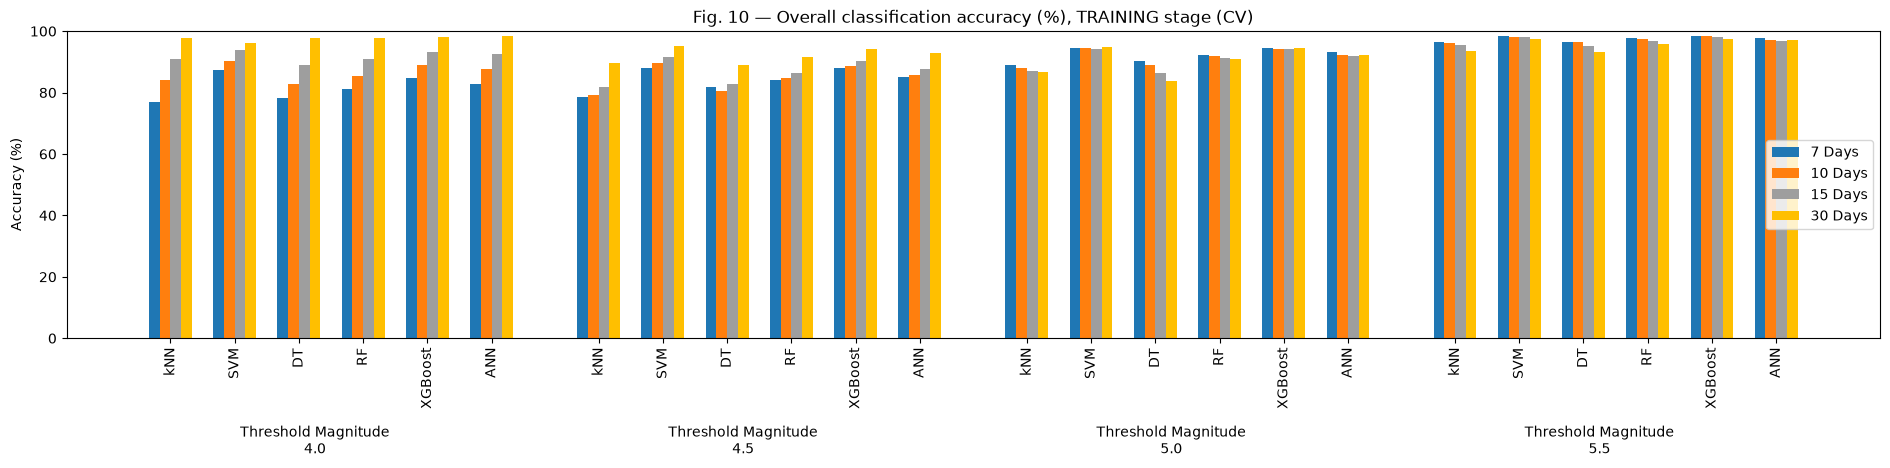

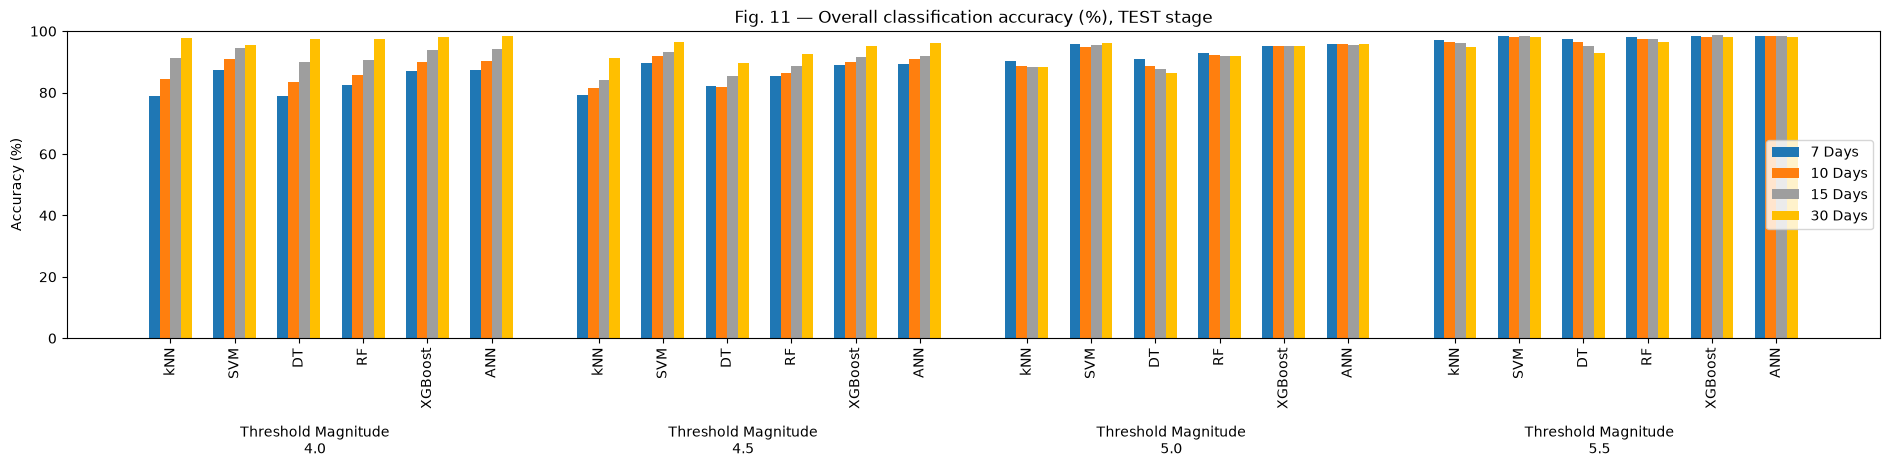

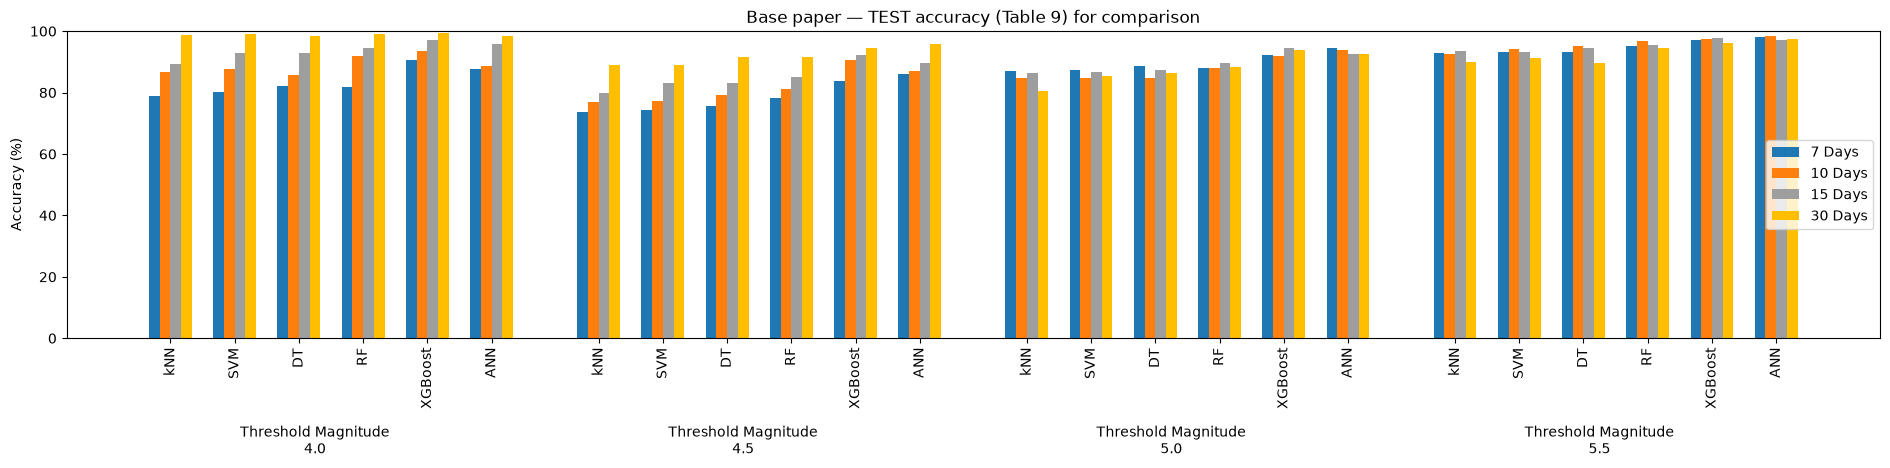

In [18]:
WCOL = {7: '#1f77b4', 10: '#ff7f0e', 15: '#9e9e9e', 30: '#ffbf00'}
def plot_acc_bars(df, title, fname):
    fig, ax = plt.subplots(figsize=(19, 5)); x = 0; ticks, labs, centers = [], [], []
    for thr in THRESHOLDS:
        start = x
        for m in models:
            for k, d in enumerate(WINDOWS):
                if (thr, d) in df.index: ax.bar(x + k * 0.2, df.loc[(thr, d), m], 0.2, color=WCOL[d], label=f'{d} Days')
            ticks.append(x + 0.3); labs.append(m); x += 1.2
        centers.append((start + x) / 2 - 0.6); x += 0.8
    ax.set_xticks(ticks); ax.set_xticklabels(labs, rotation=90)
    for c, thr in zip(centers, THRESHOLDS): ax.text(c, -28, f'Threshold Magnitude\n{thr}', ha='center', va='top', fontsize=10)
    h, l = ax.get_legend_handles_labels(); u = dict(zip(l, h)); ax.legend(u.values(), u.keys(), loc='center right')
    ax.set_ylim(0, 100); ax.set_ylabel('Accuracy (%)'); ax.set_title(title); plt.tight_layout(); plt.savefig(f'{FIG_DIR}/{fname}', dpi=200, bbox_inches='tight'); plt.show()
plot_acc_bars(mine_train, 'Fig. 10 — Overall classification accuracy (%), TRAINING stage (CV)', 'Fig10_train_accuracy.png')
plot_acc_bars(mine_test,  'Fig. 11 — Overall classification accuracy (%), TEST stage', 'Fig11_test_accuracy.png')
plot_acc_bars(pt.copy(), 'Base paper — TEST accuracy (Table 9) for comparison', 'Paper_Table9_test_accuracy.png')

### C5. Fig. 8 / S10–S12 — confusion matrices (rows = thresholds 4.0 → 5.5, columns = kNN, SVM, DT, RF, XGBoost, ANN), train and test

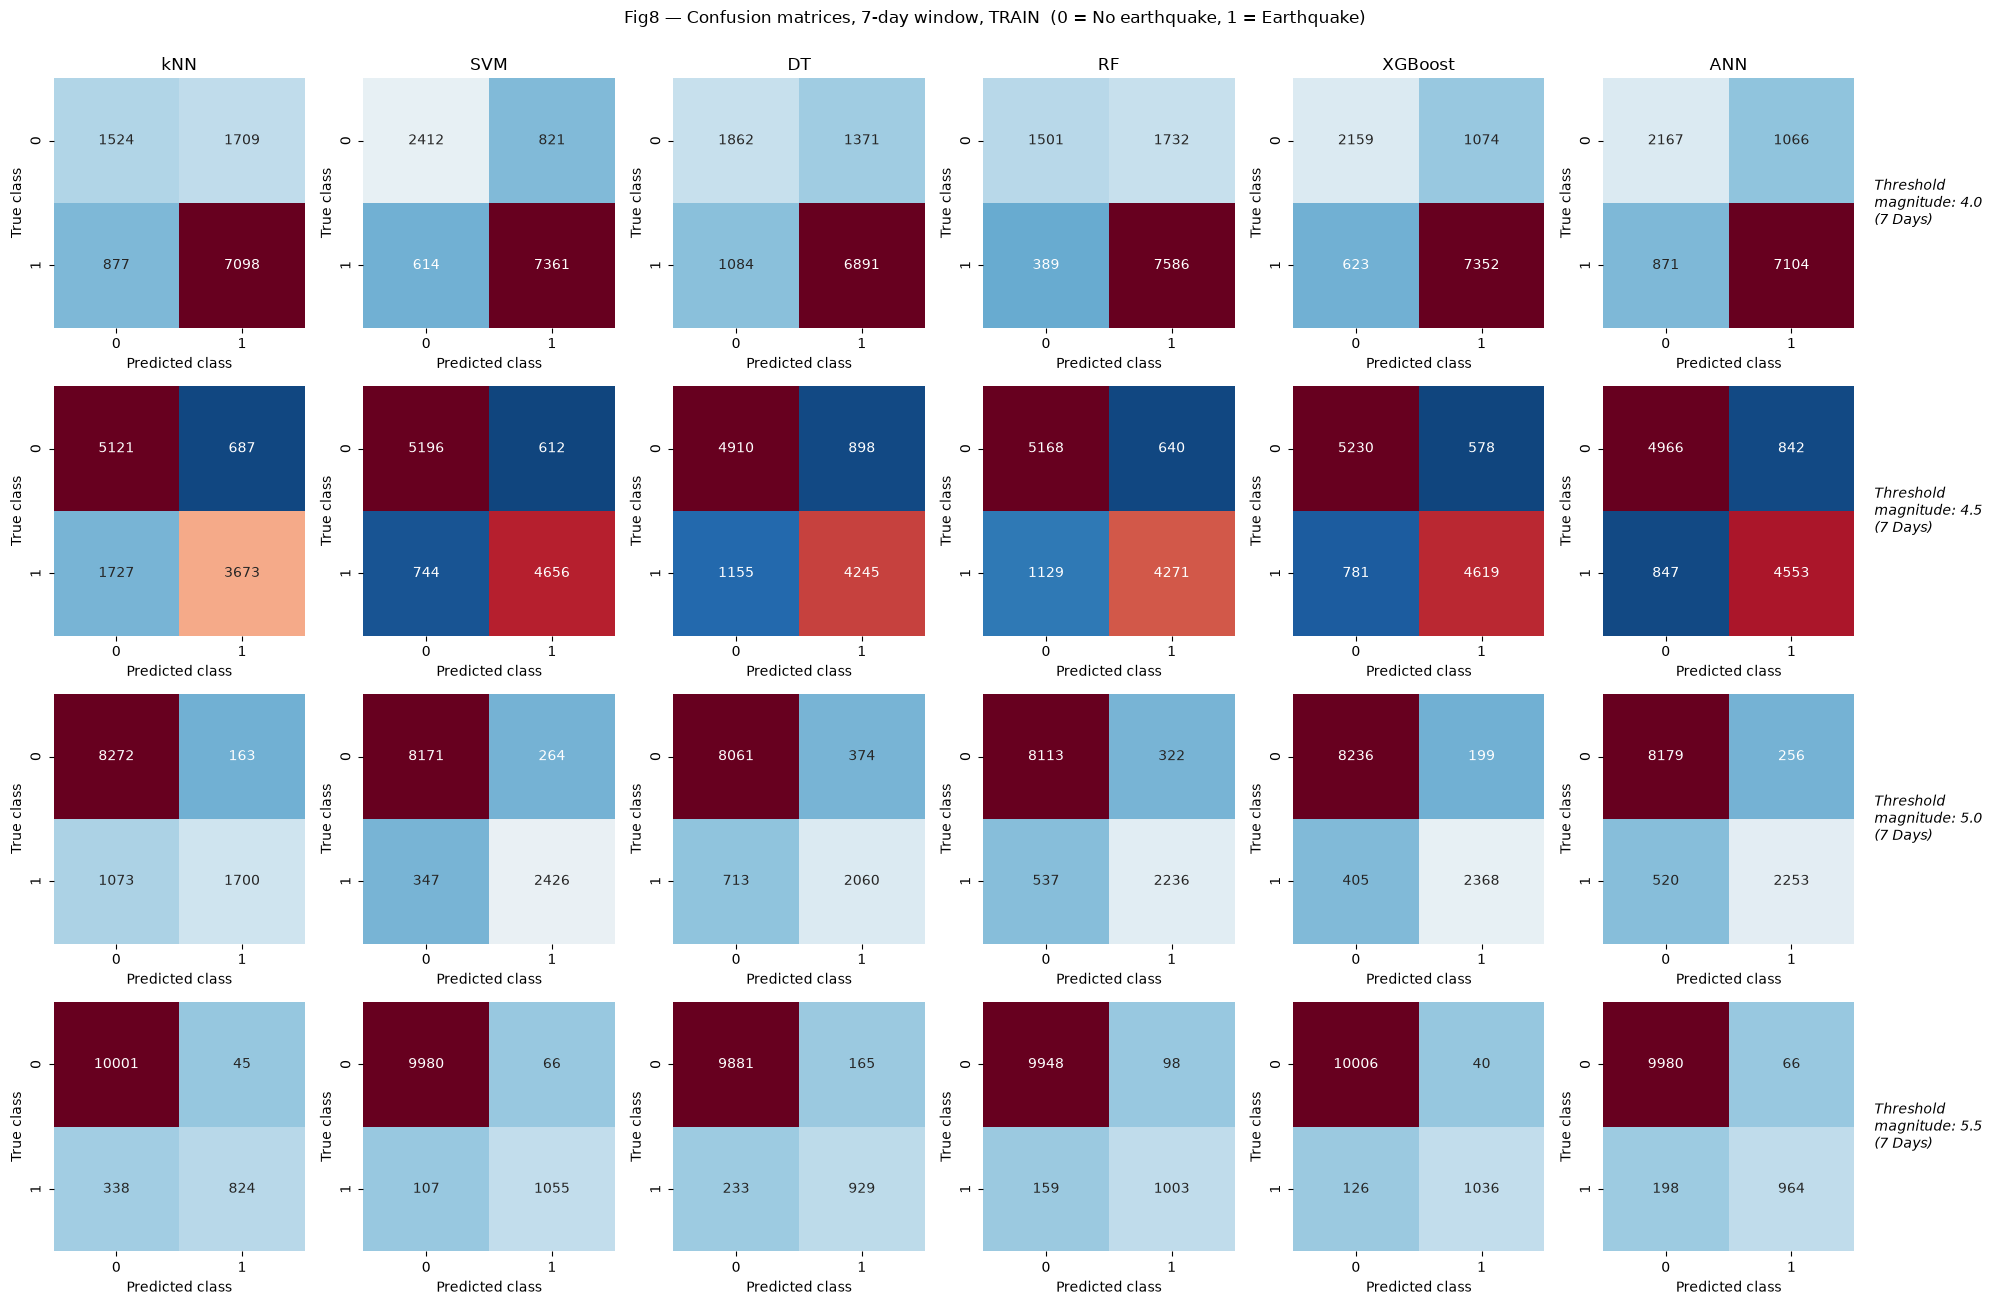

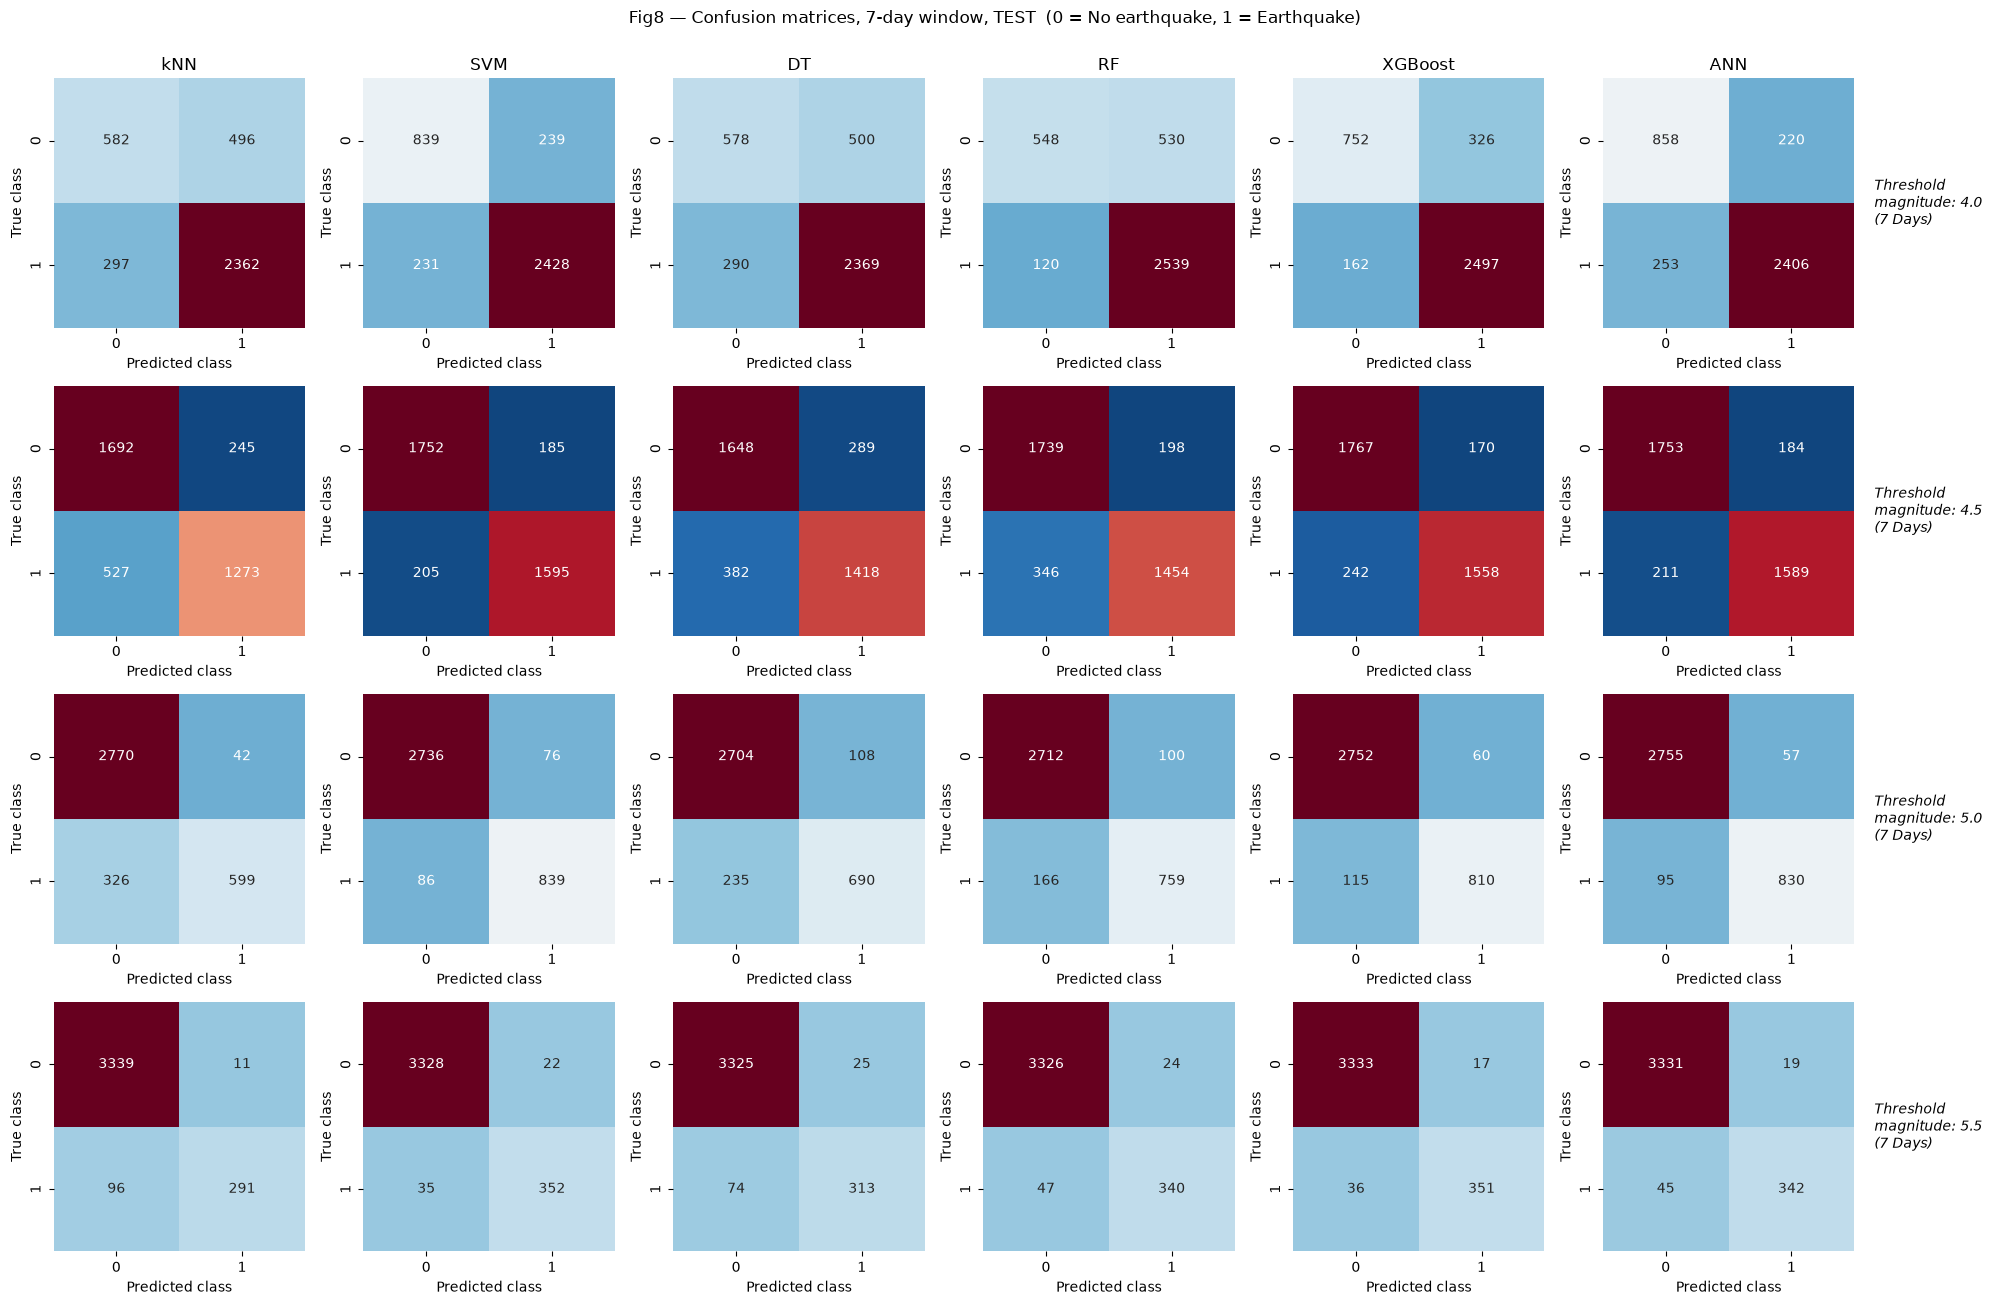

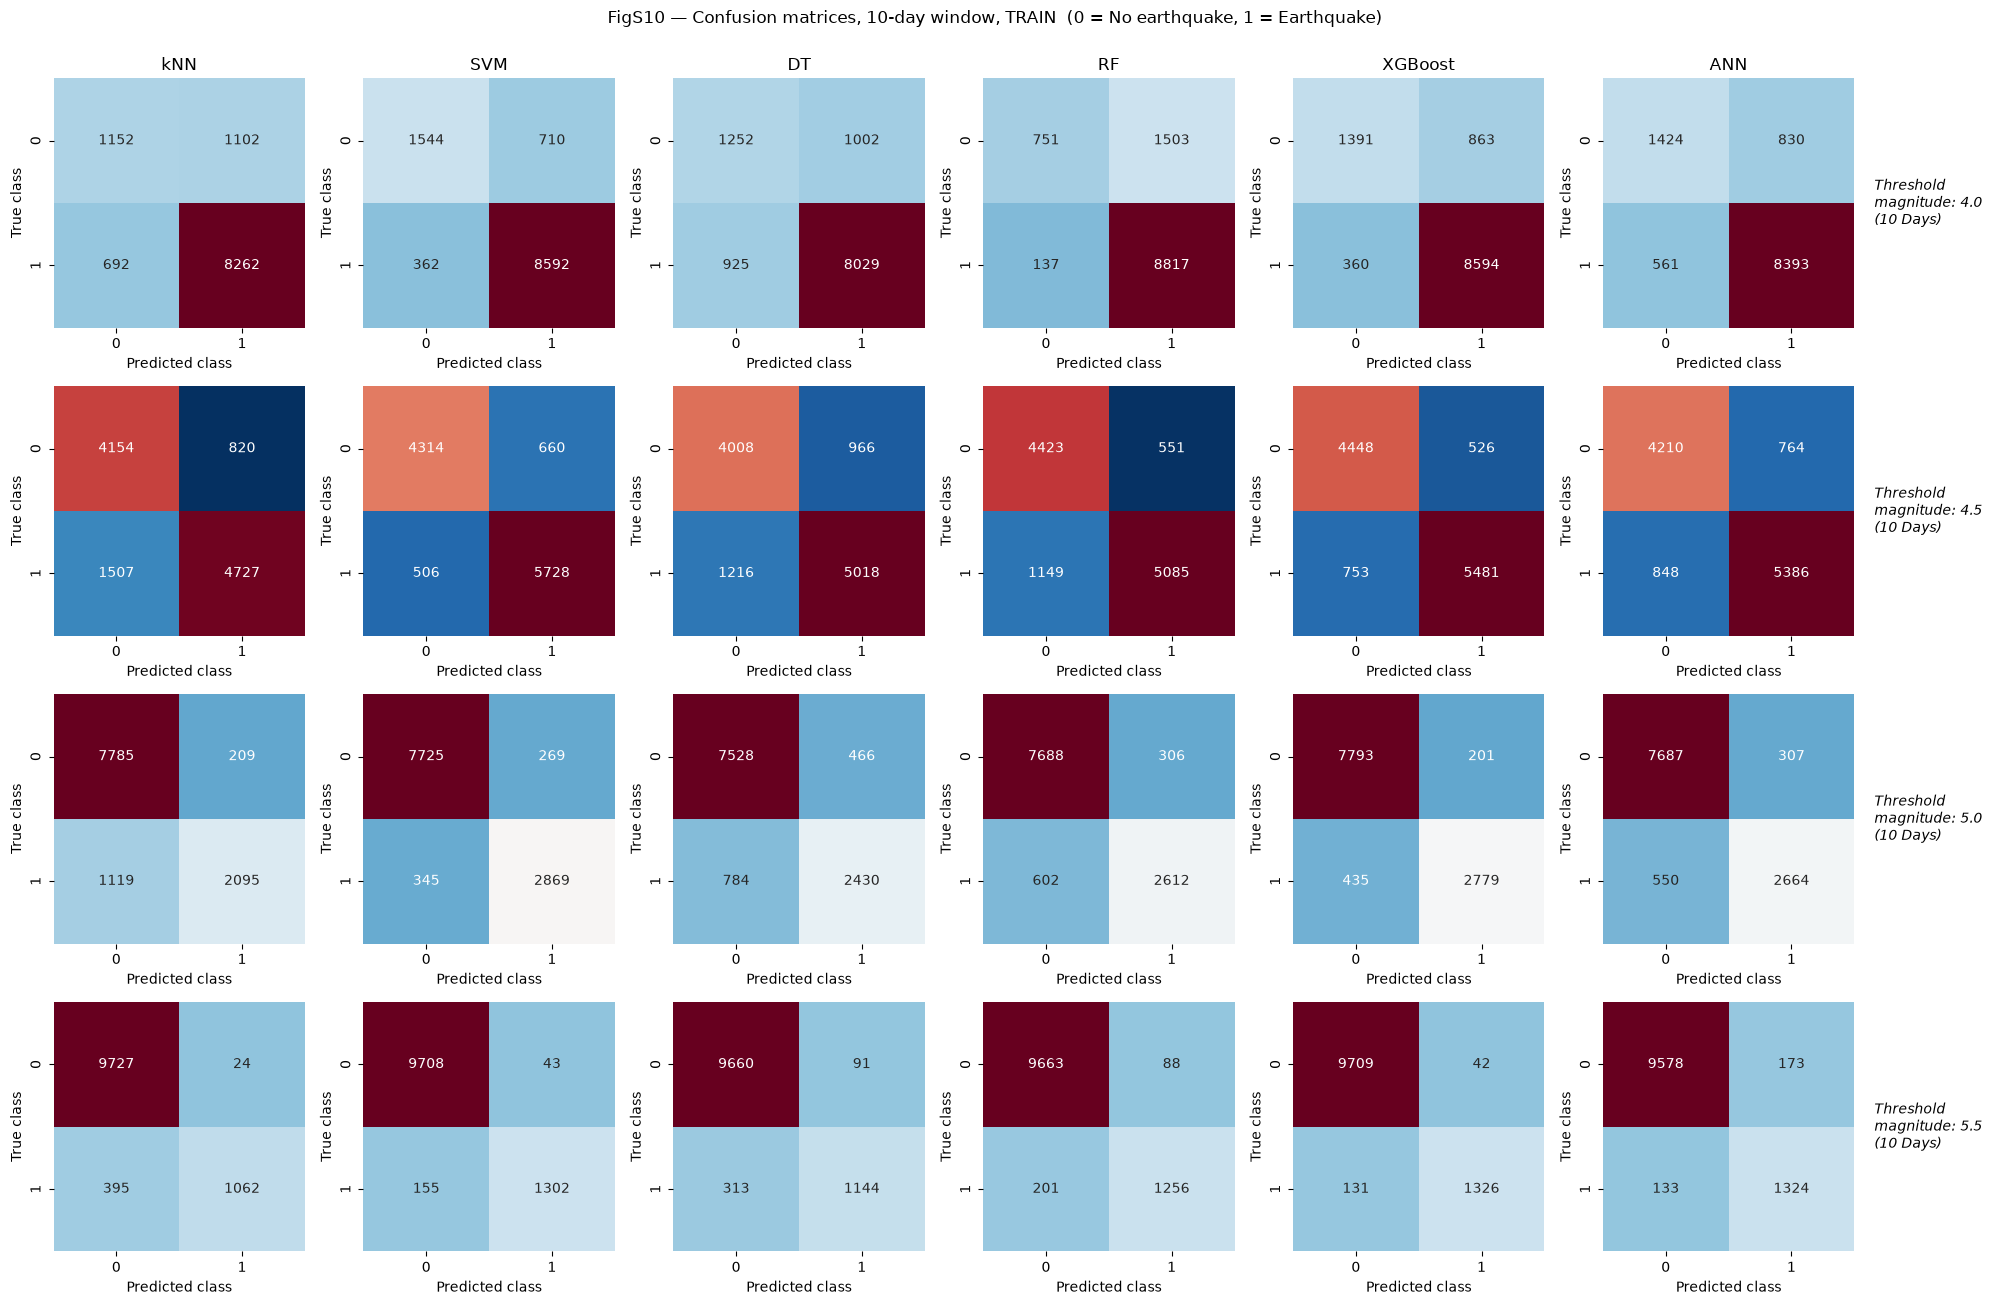

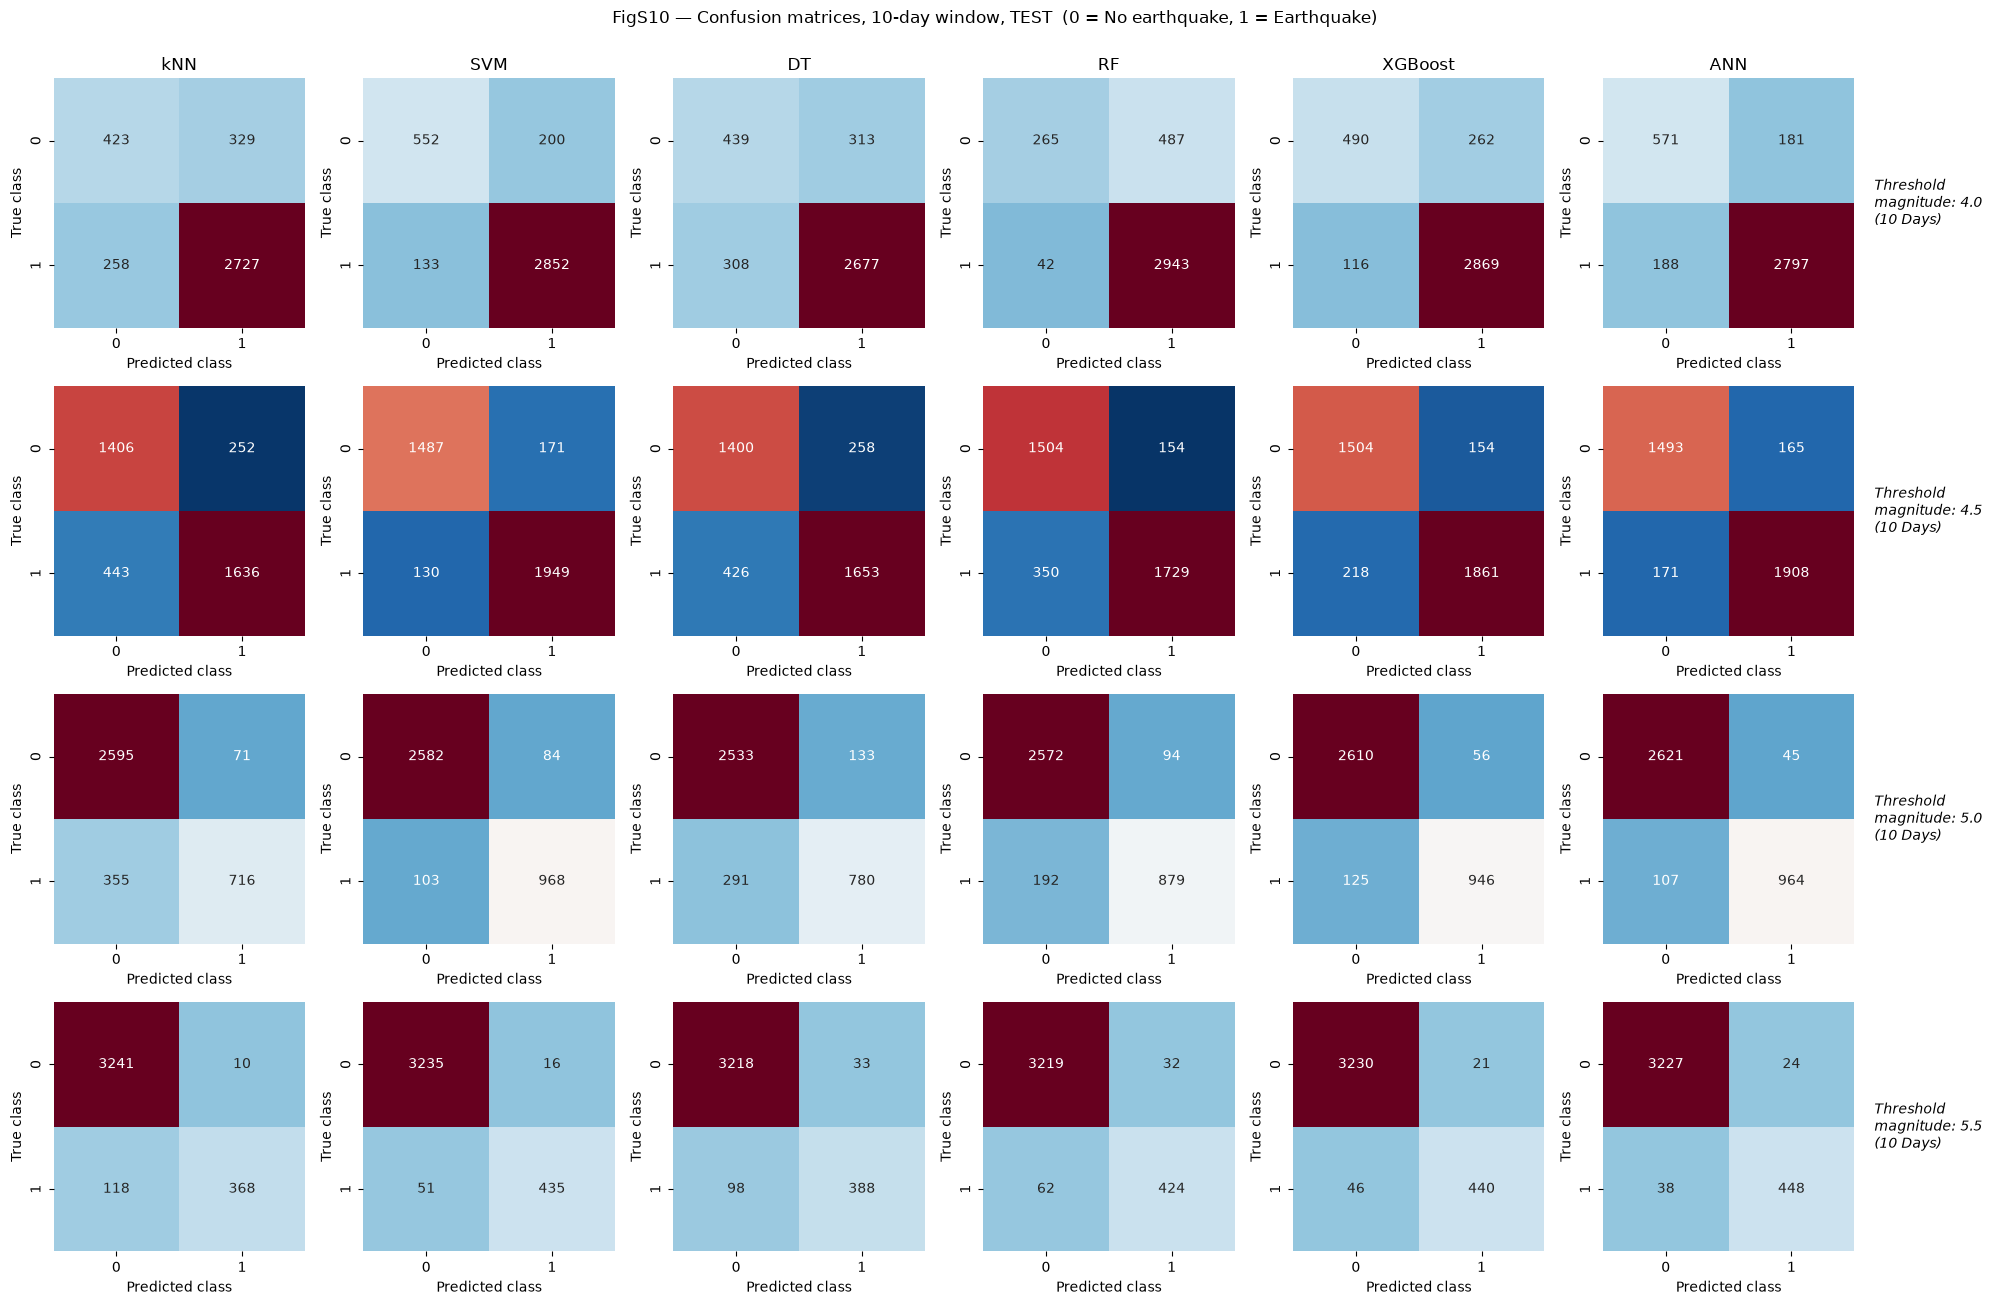

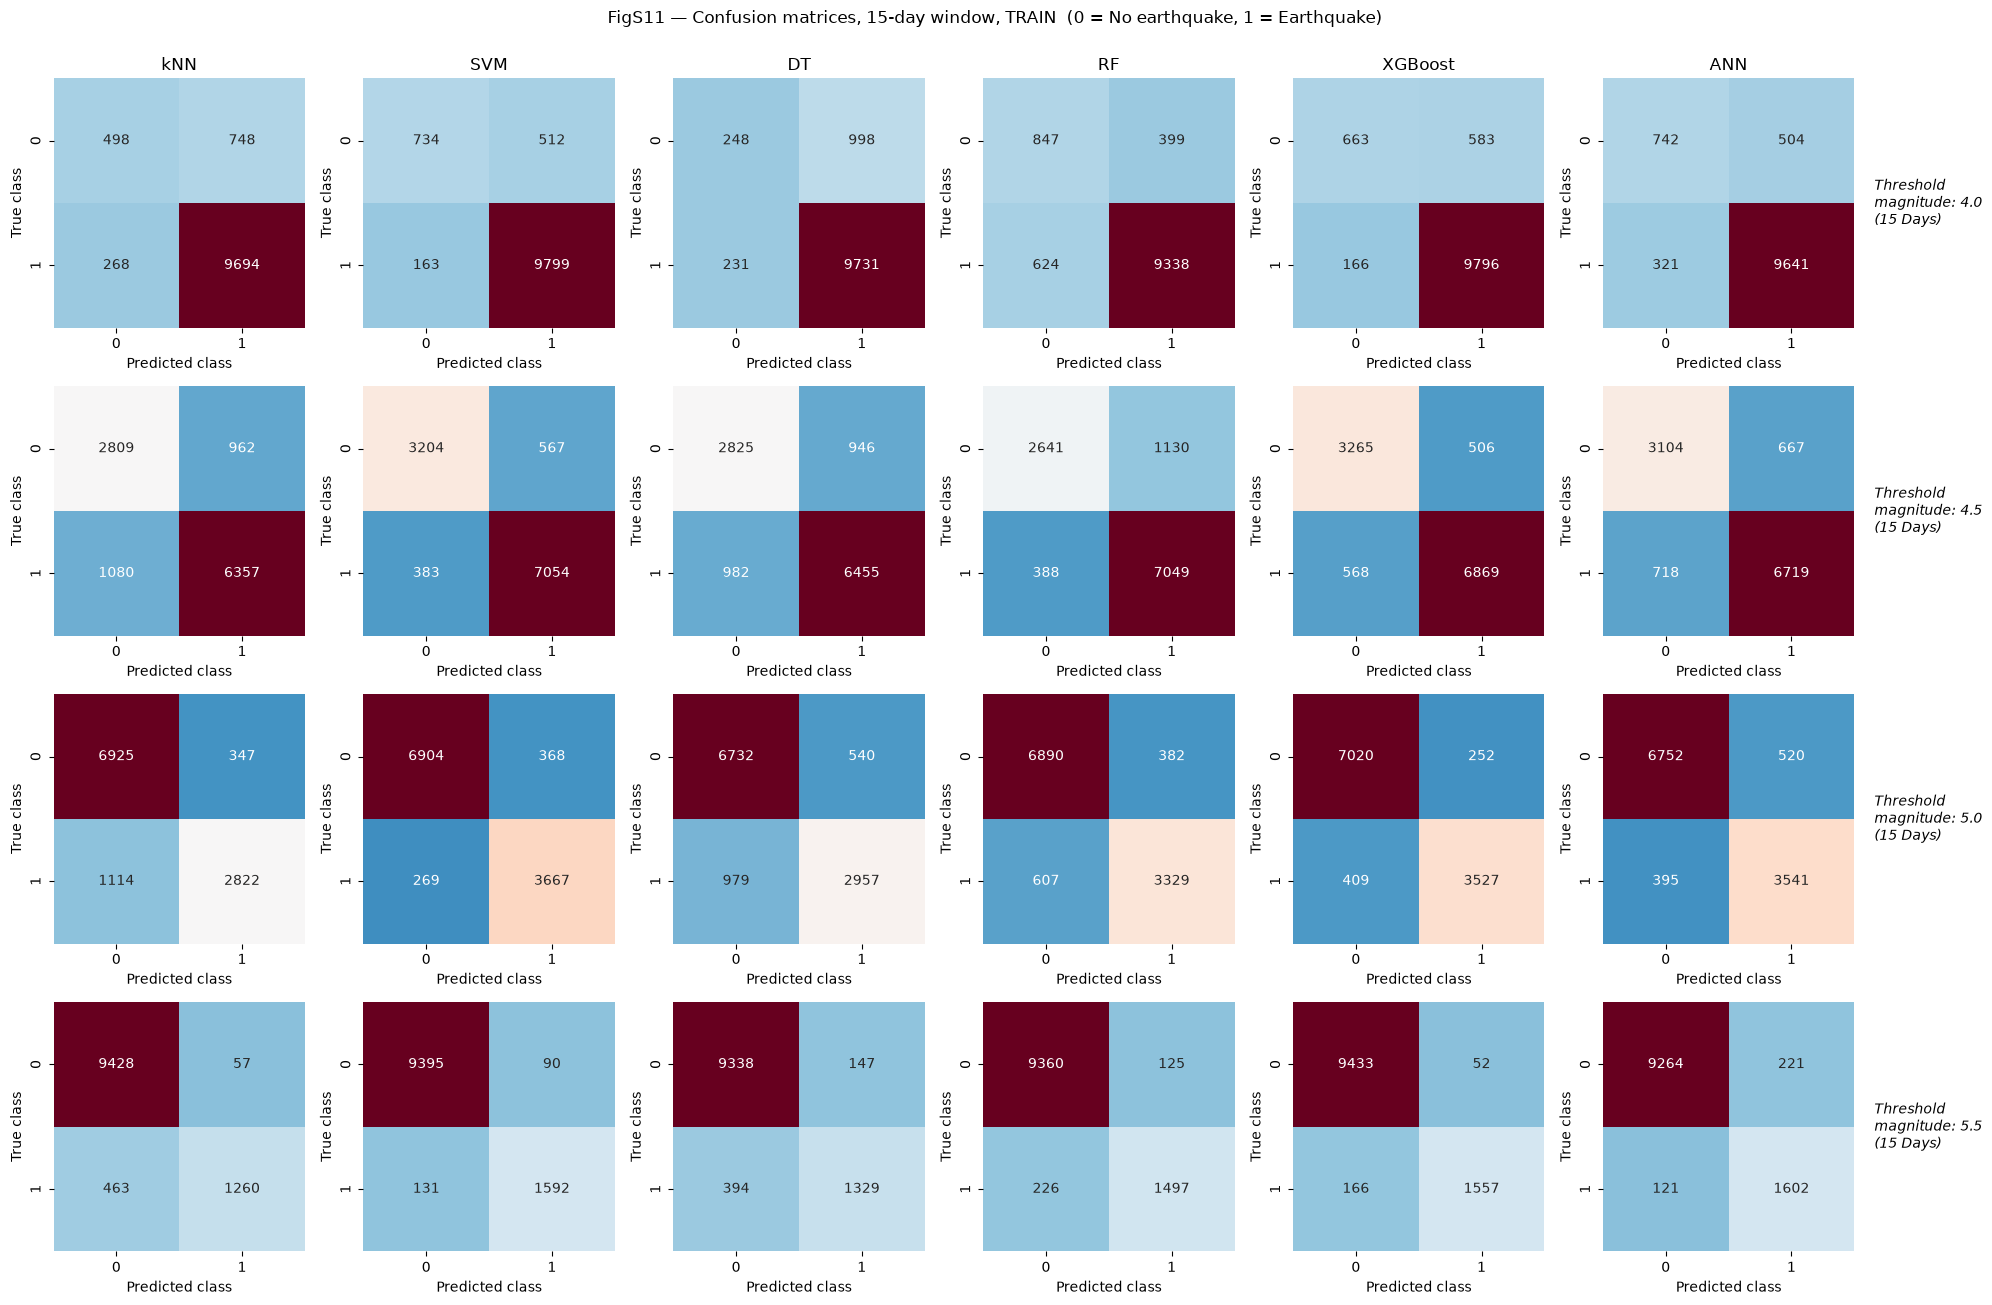

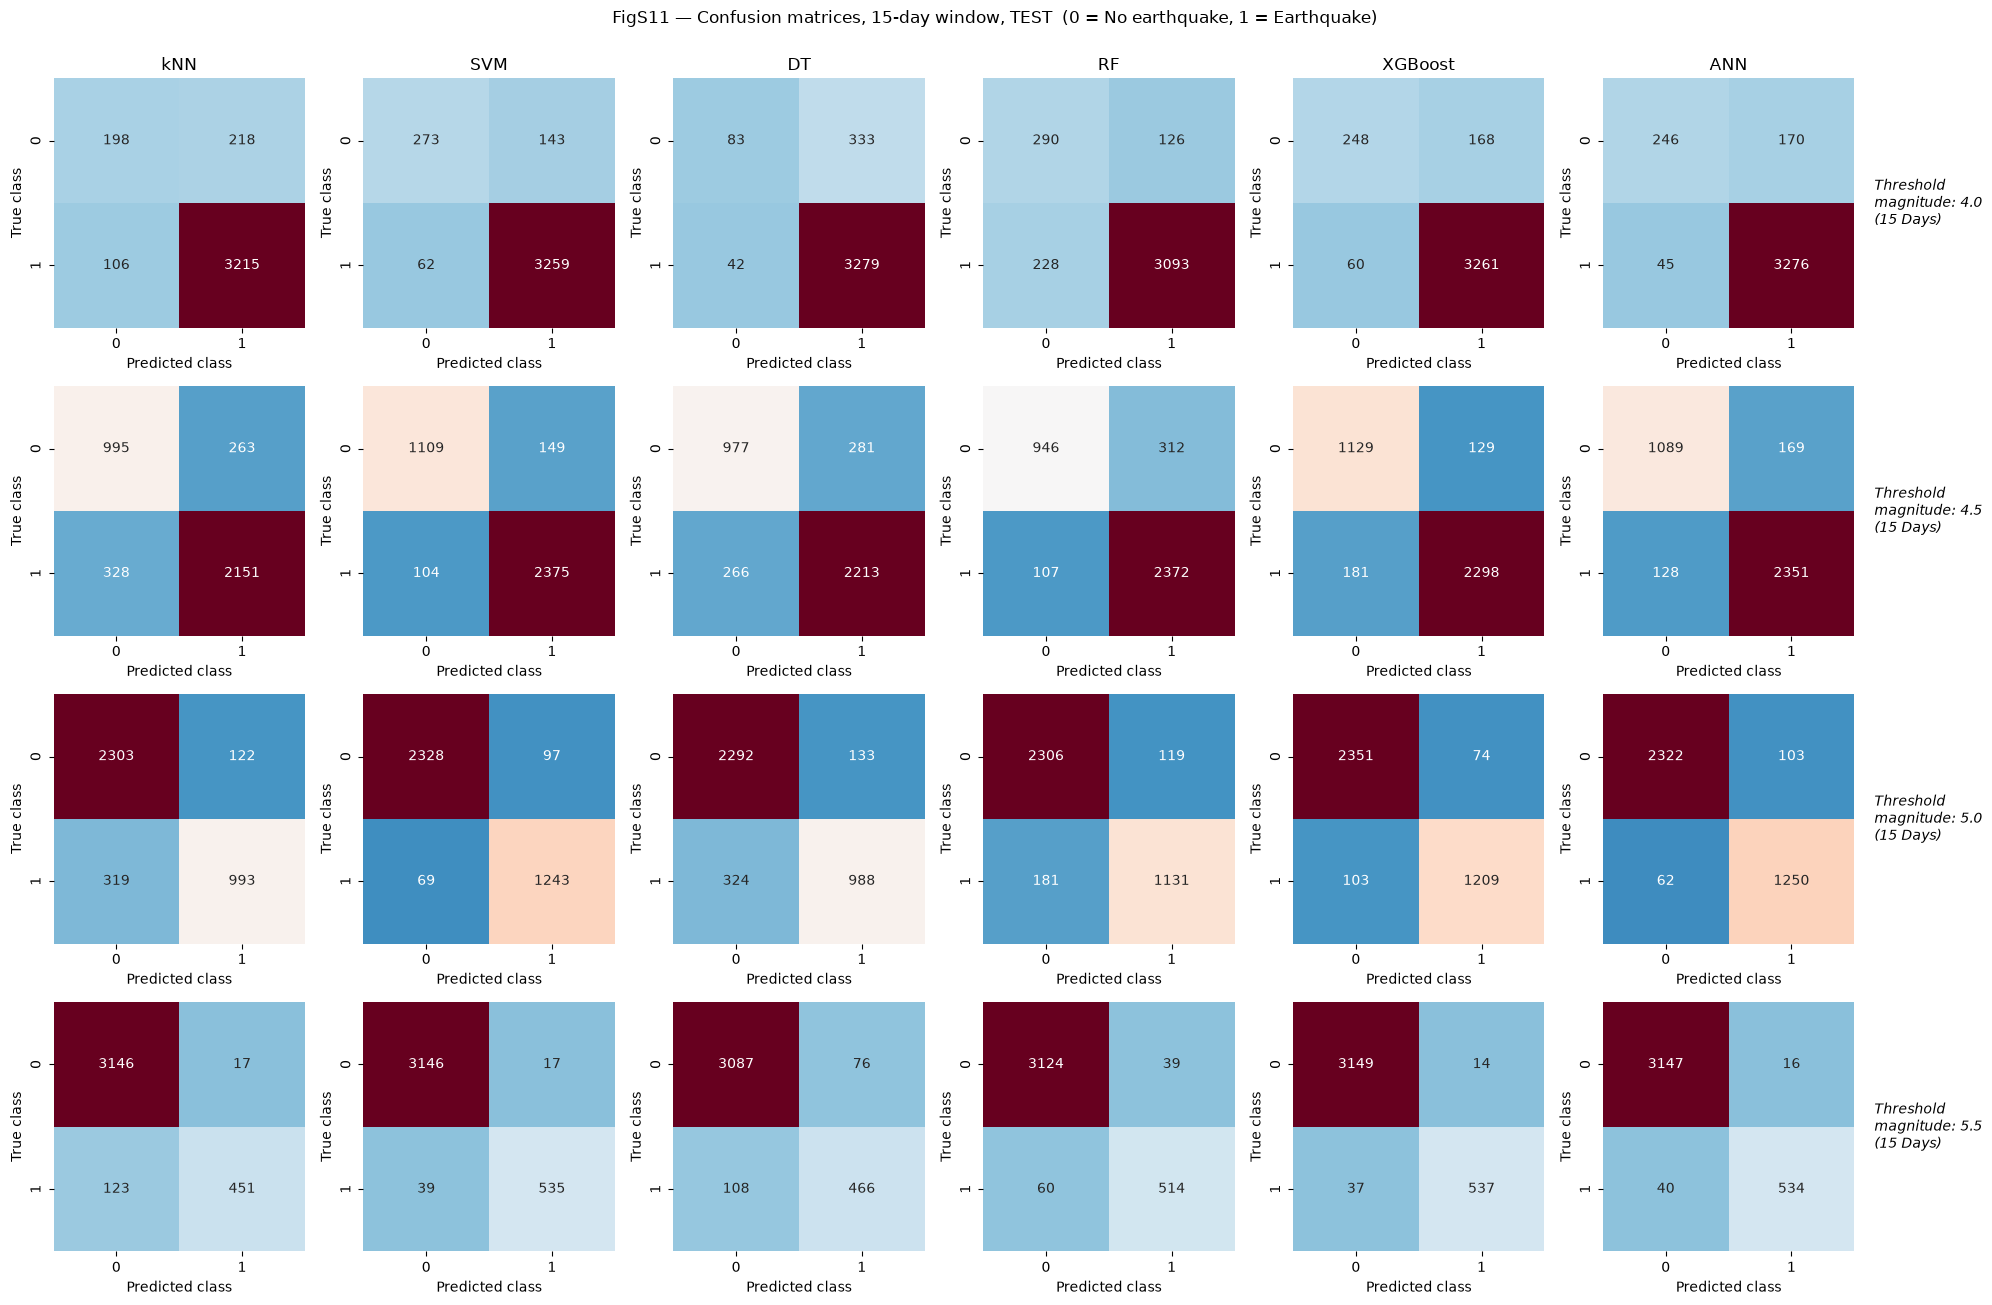

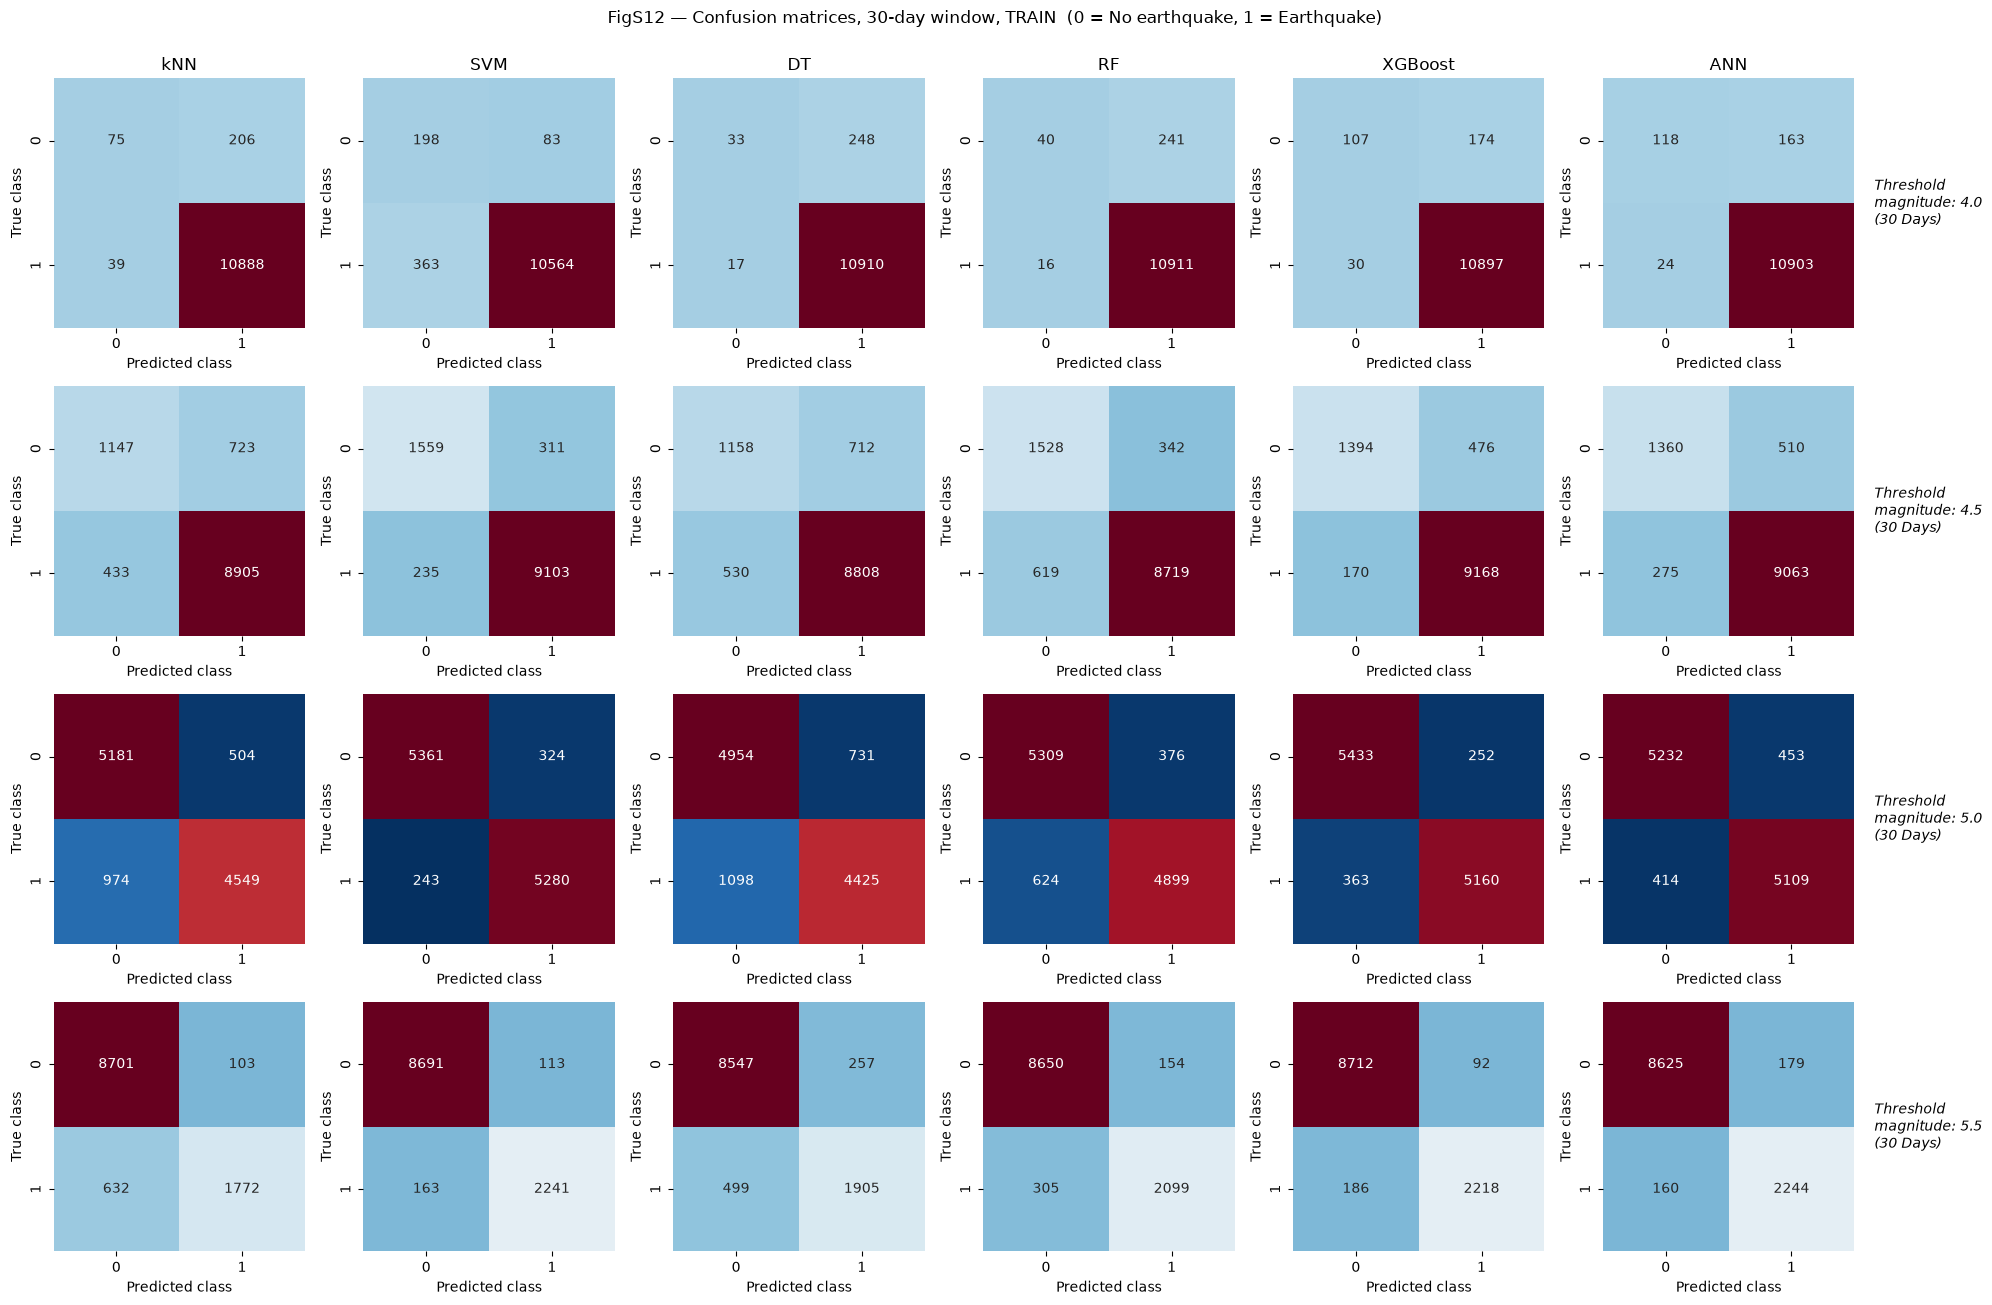

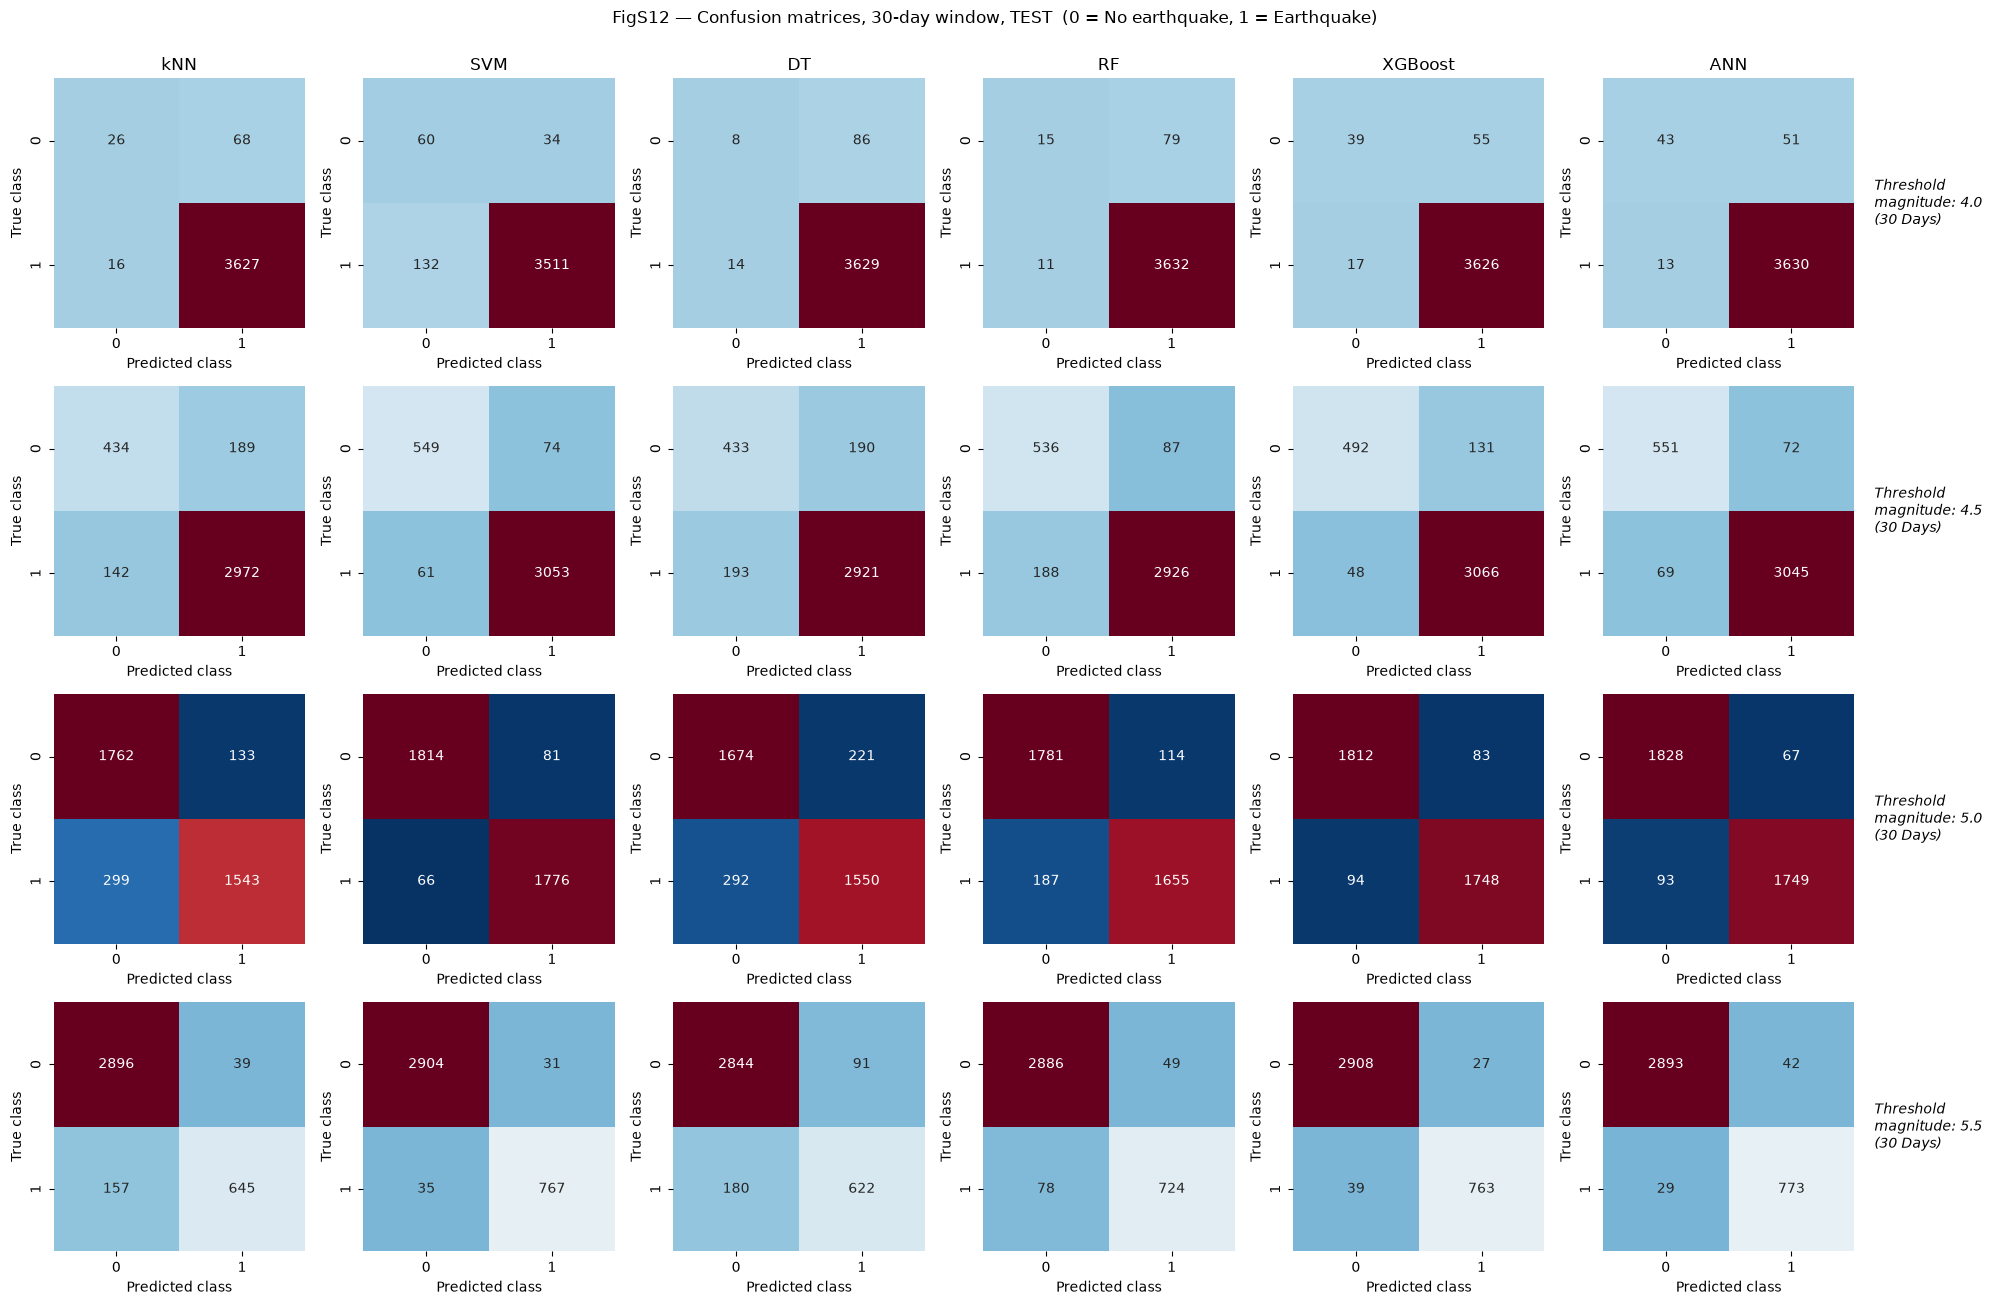

In [19]:
def plot_confusion_grid(days, phase):
    fig, axes = plt.subplots(4, 6, figsize=(20, 13))
    for ti, thr in enumerate(THRESHOLDS):
        rec = ART.get((days, thr))
        for mi, name in enumerate(MODEL_ORDER):
            ax = axes[ti, mi]
            if rec is None or name not in rec['models']: ax.axis('off'); continue
            yp, _ = get_art(rec, name, phase); cm = confusion_matrix(yy(rec, phase), yp, labels=[0, 1])
            sns.heatmap(cm, annot=True, fmt='d', cmap='RdBu_r', center=cm.sum() / 4, cbar=False, ax=ax, xticklabels=[0, 1], yticklabels=[0, 1])
            ax.set_xlabel('Predicted class'); ax.set_ylabel('True class')
            if ti == 0: ax.set_title(name)
            if mi == 5: ax.text(1.08, 0.5, f'Threshold\nmagnitude: {thr}\n({days} Days)', transform=ax.transAxes, va='center', fontstyle='italic')
    no = {7: 'Fig8', 10: 'FigS10', 15: 'FigS11', 30: 'FigS12'}[days]
    fig.suptitle(f'{no} — Confusion matrices, {days}-day window, {phase.upper()}  (0 = No earthquake, 1 = Earthquake)', y=1.0)
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/{no}_confusion_{days}d_{phase}.png', dpi=170, bbox_inches='tight'); plt.show()
for d in WIN_PRESENT:
    for ph in ['Train', 'Test']: plot_confusion_grid(d, ph)

### C6. Fig. 9 / S14–S16 — ROC curves with AUC (red = earthquake class 1, blue = no-earthquake class 0, dots = operating points), train and test

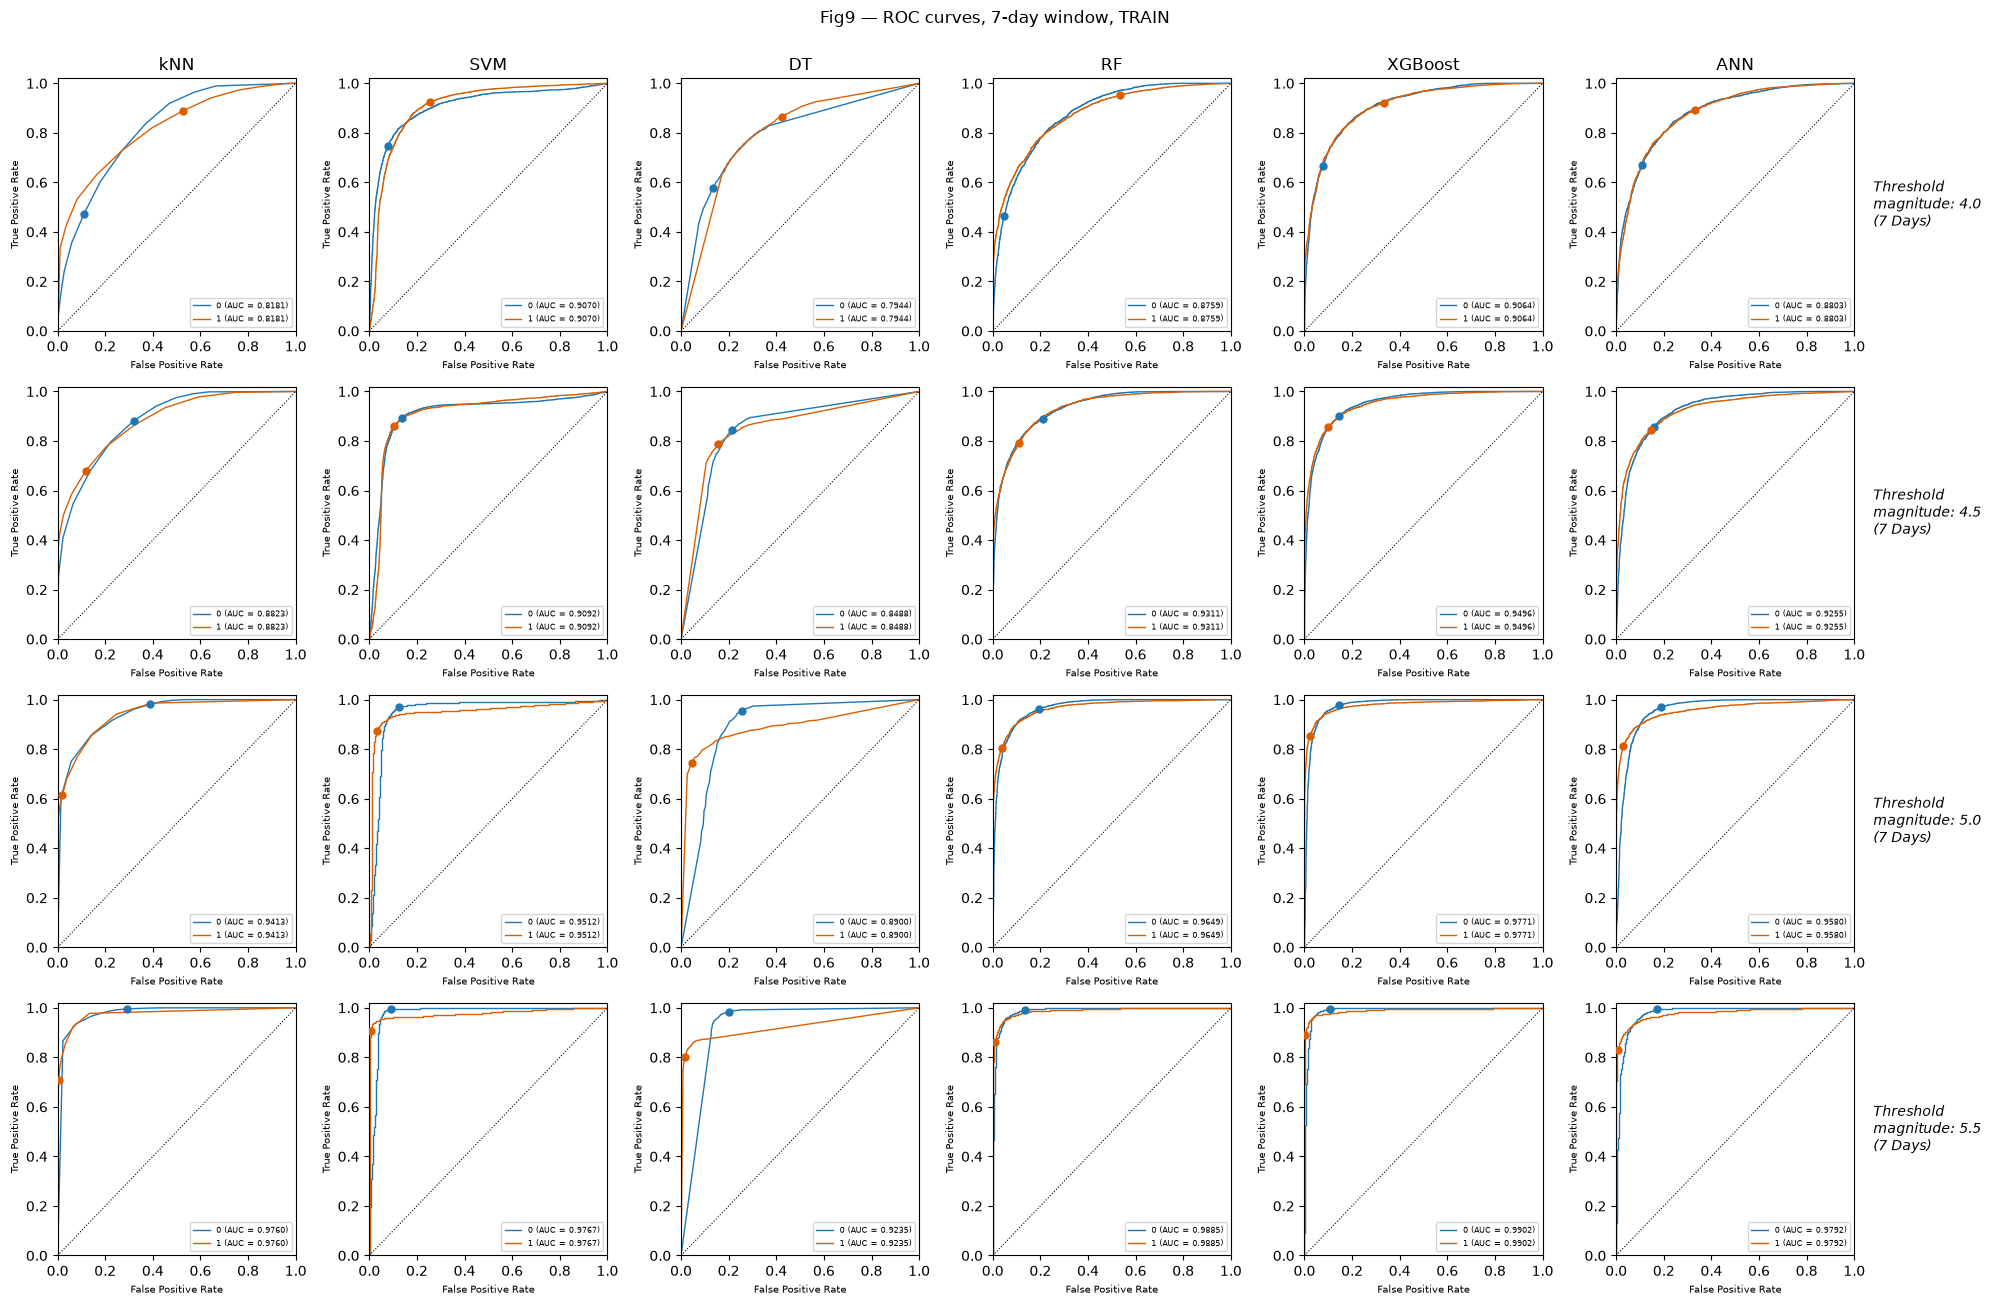

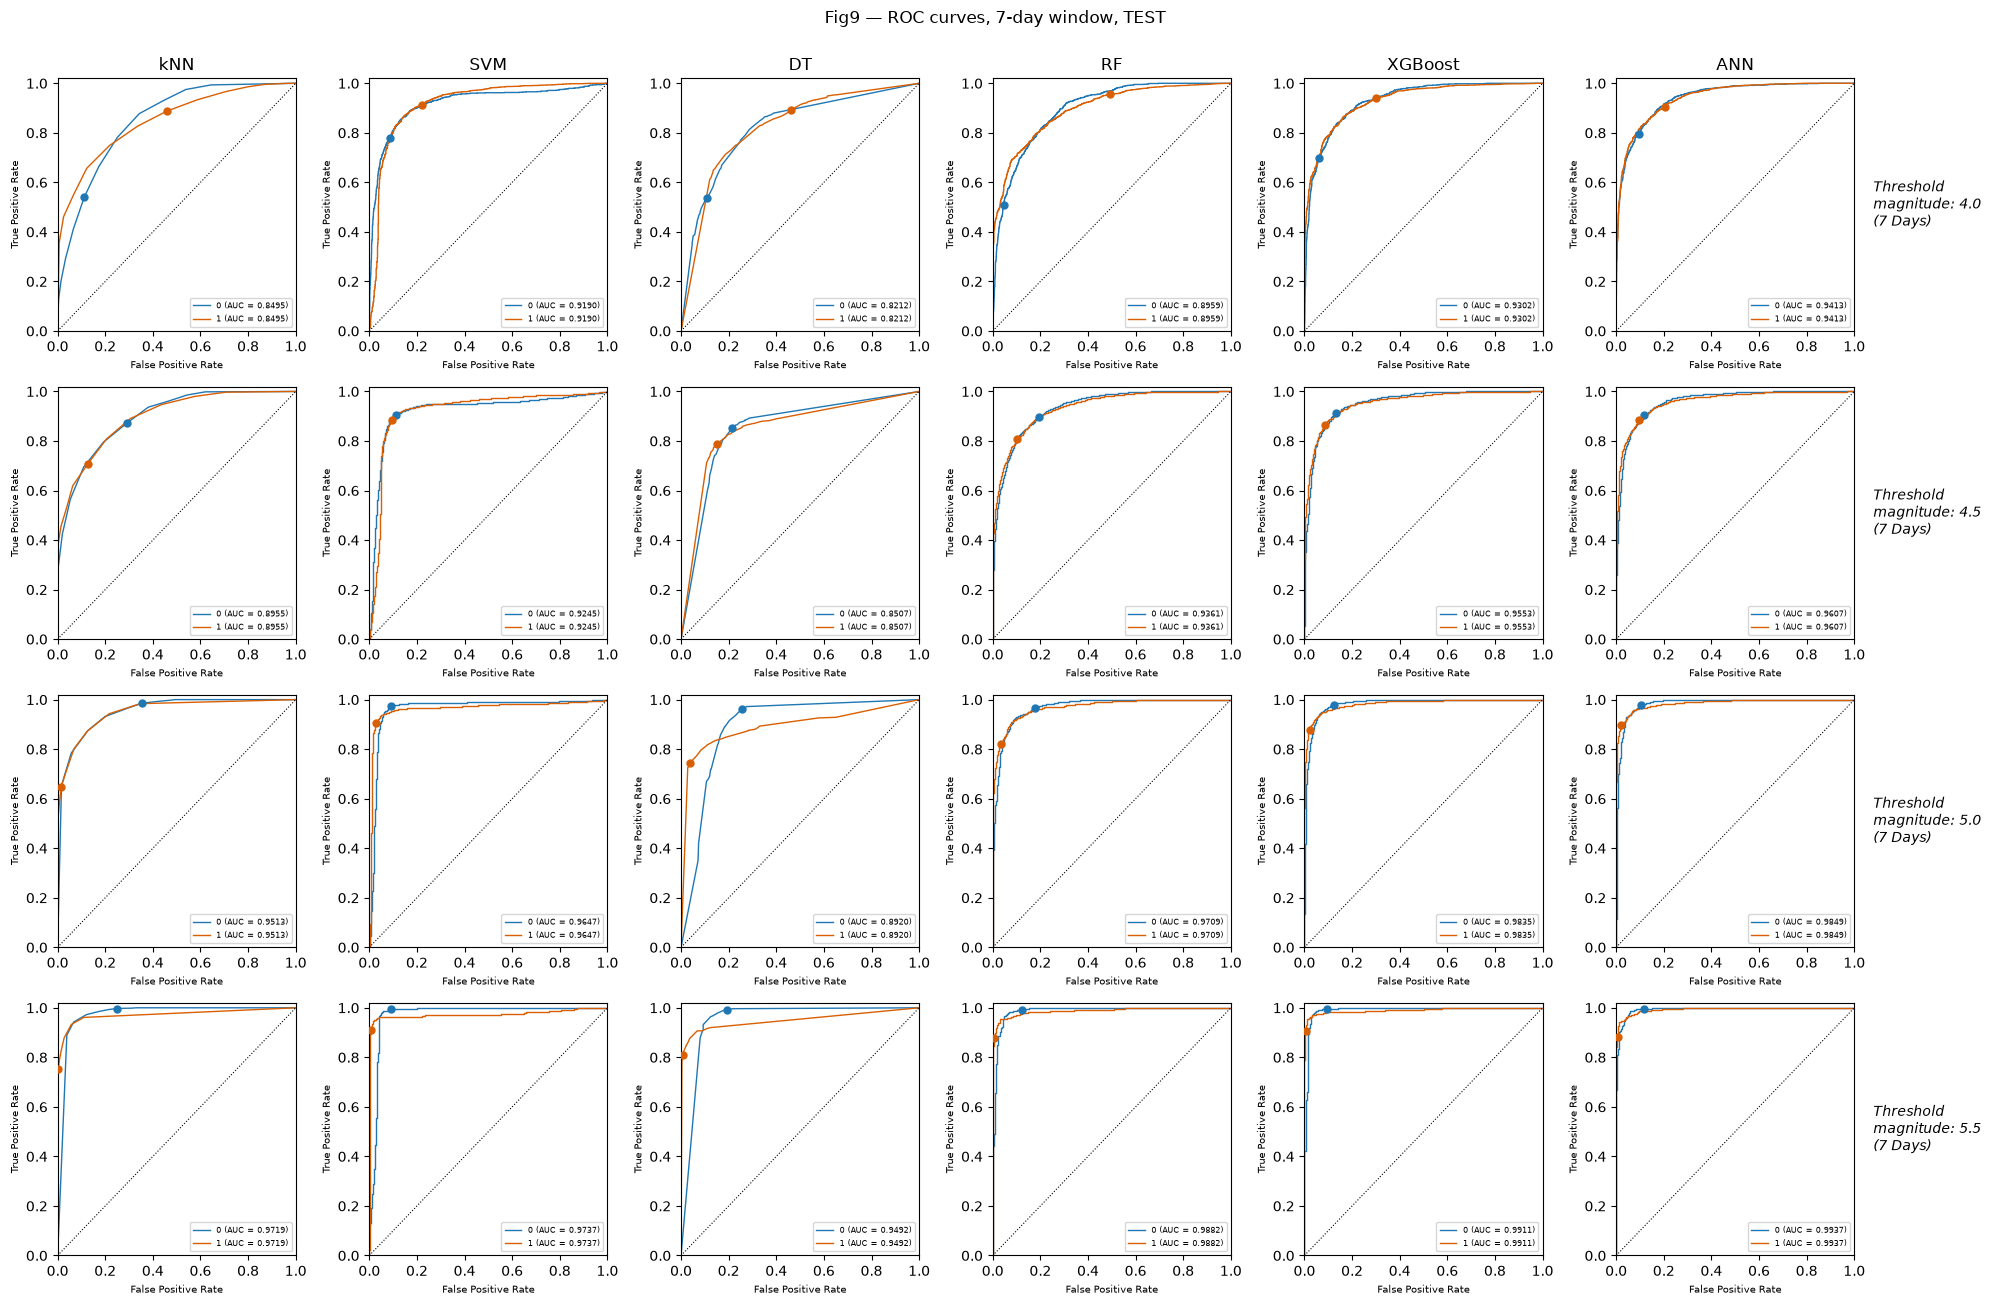

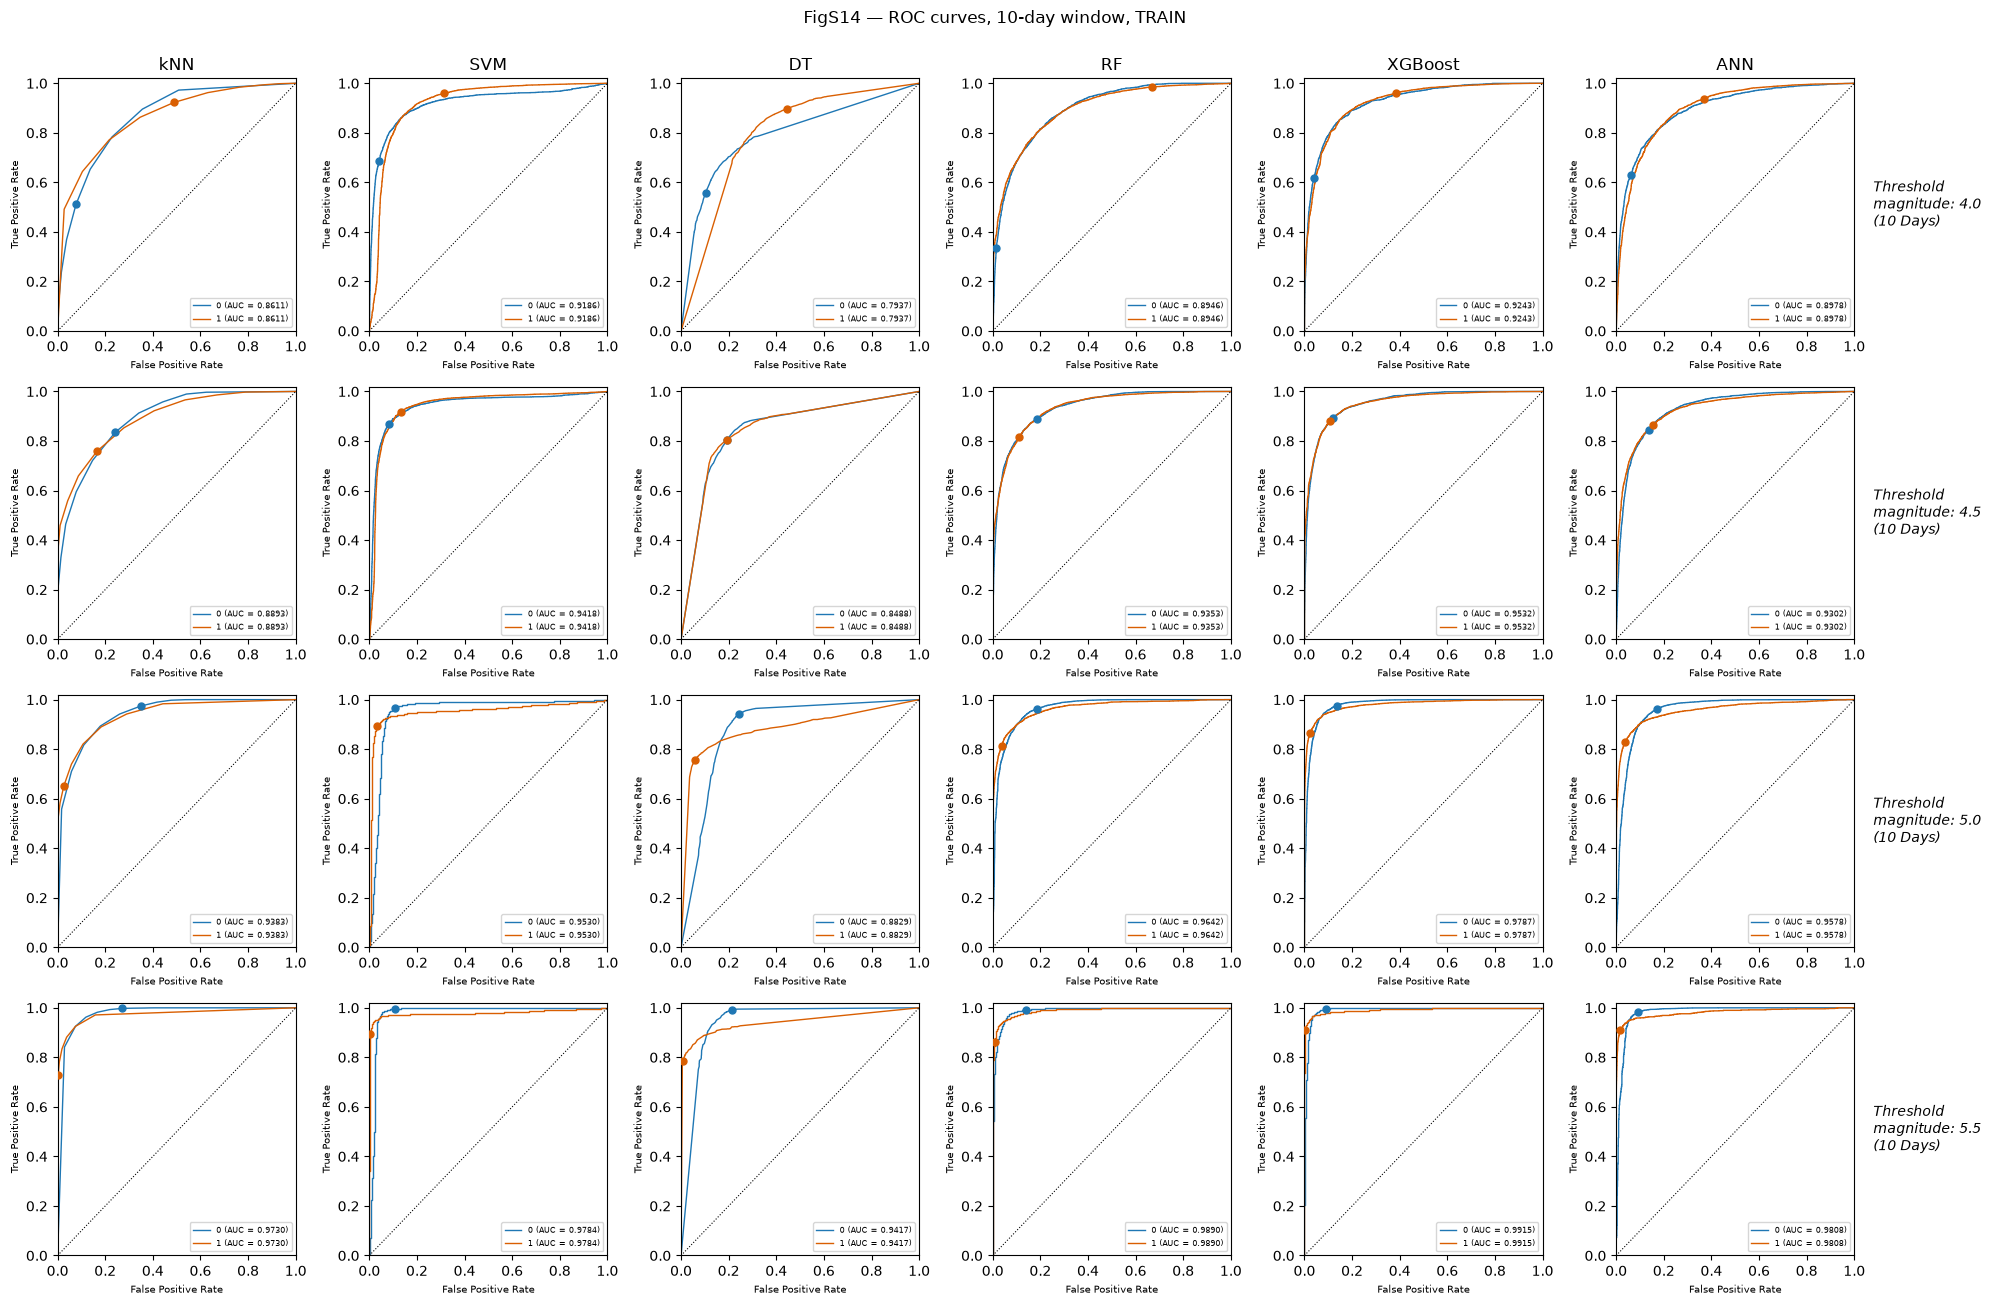

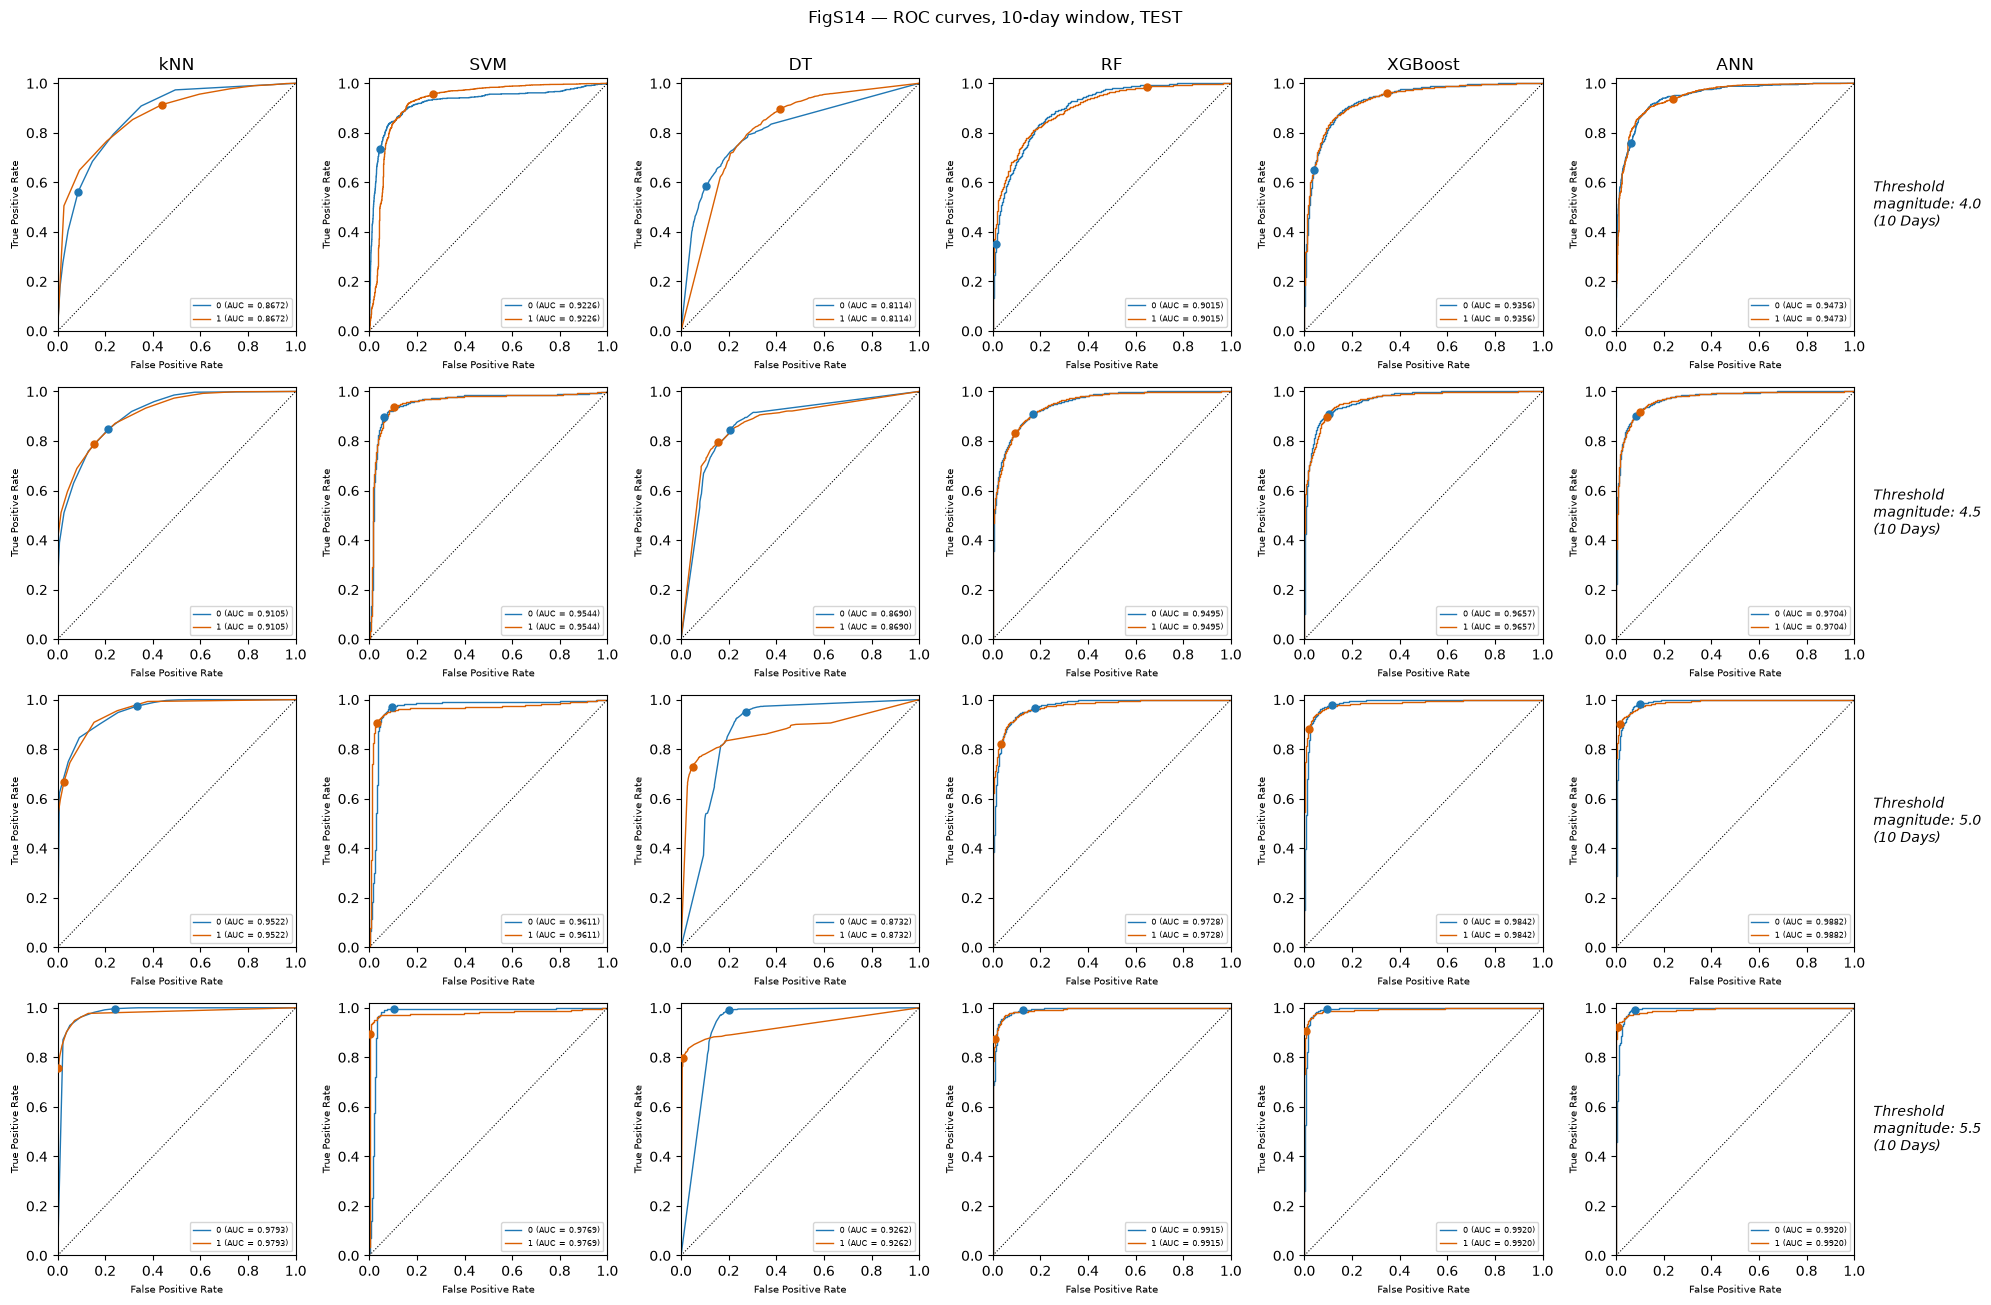

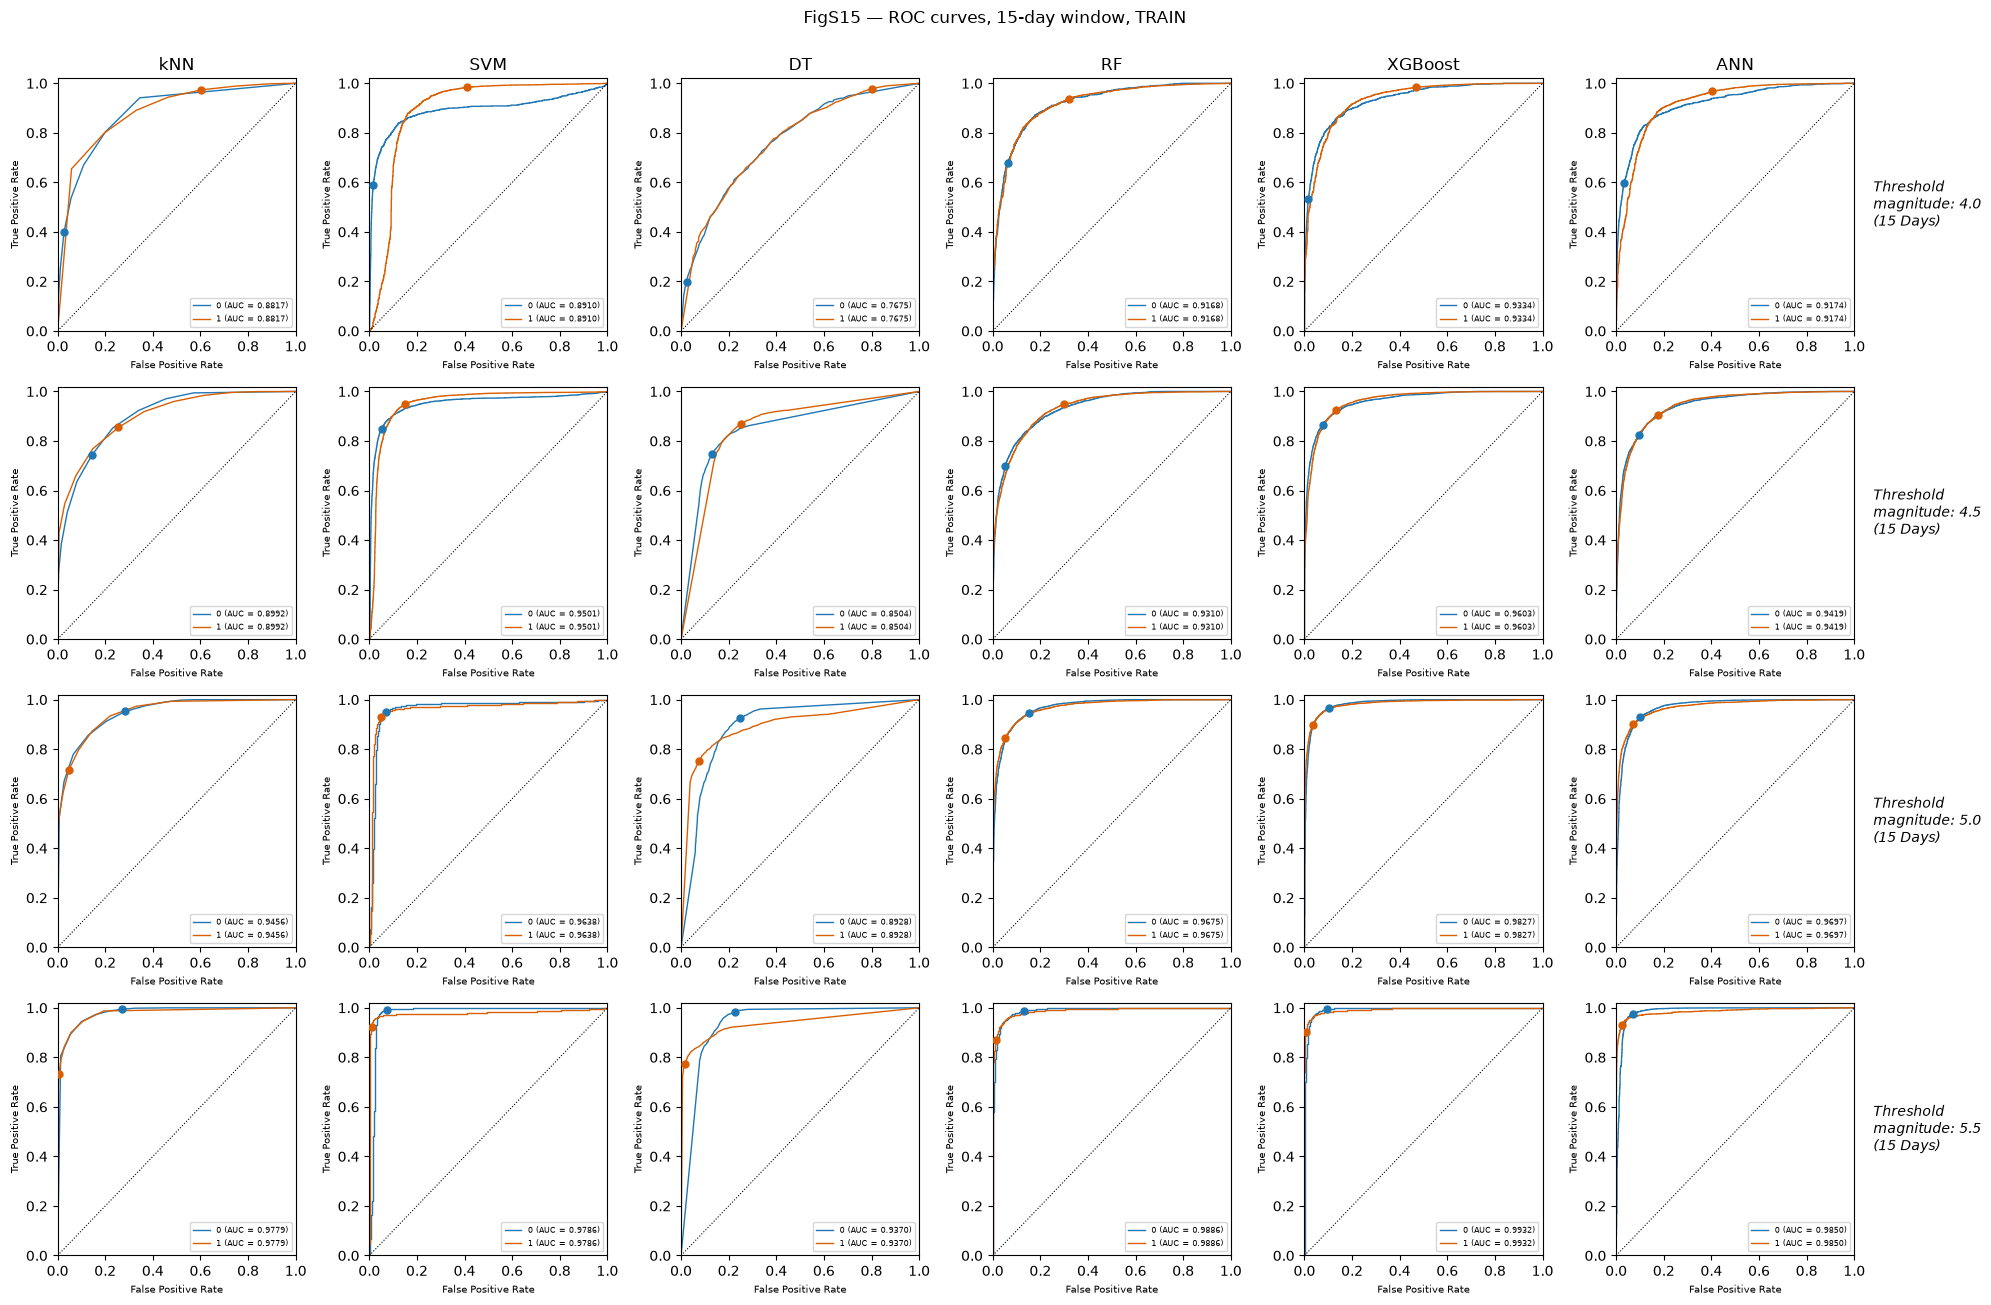

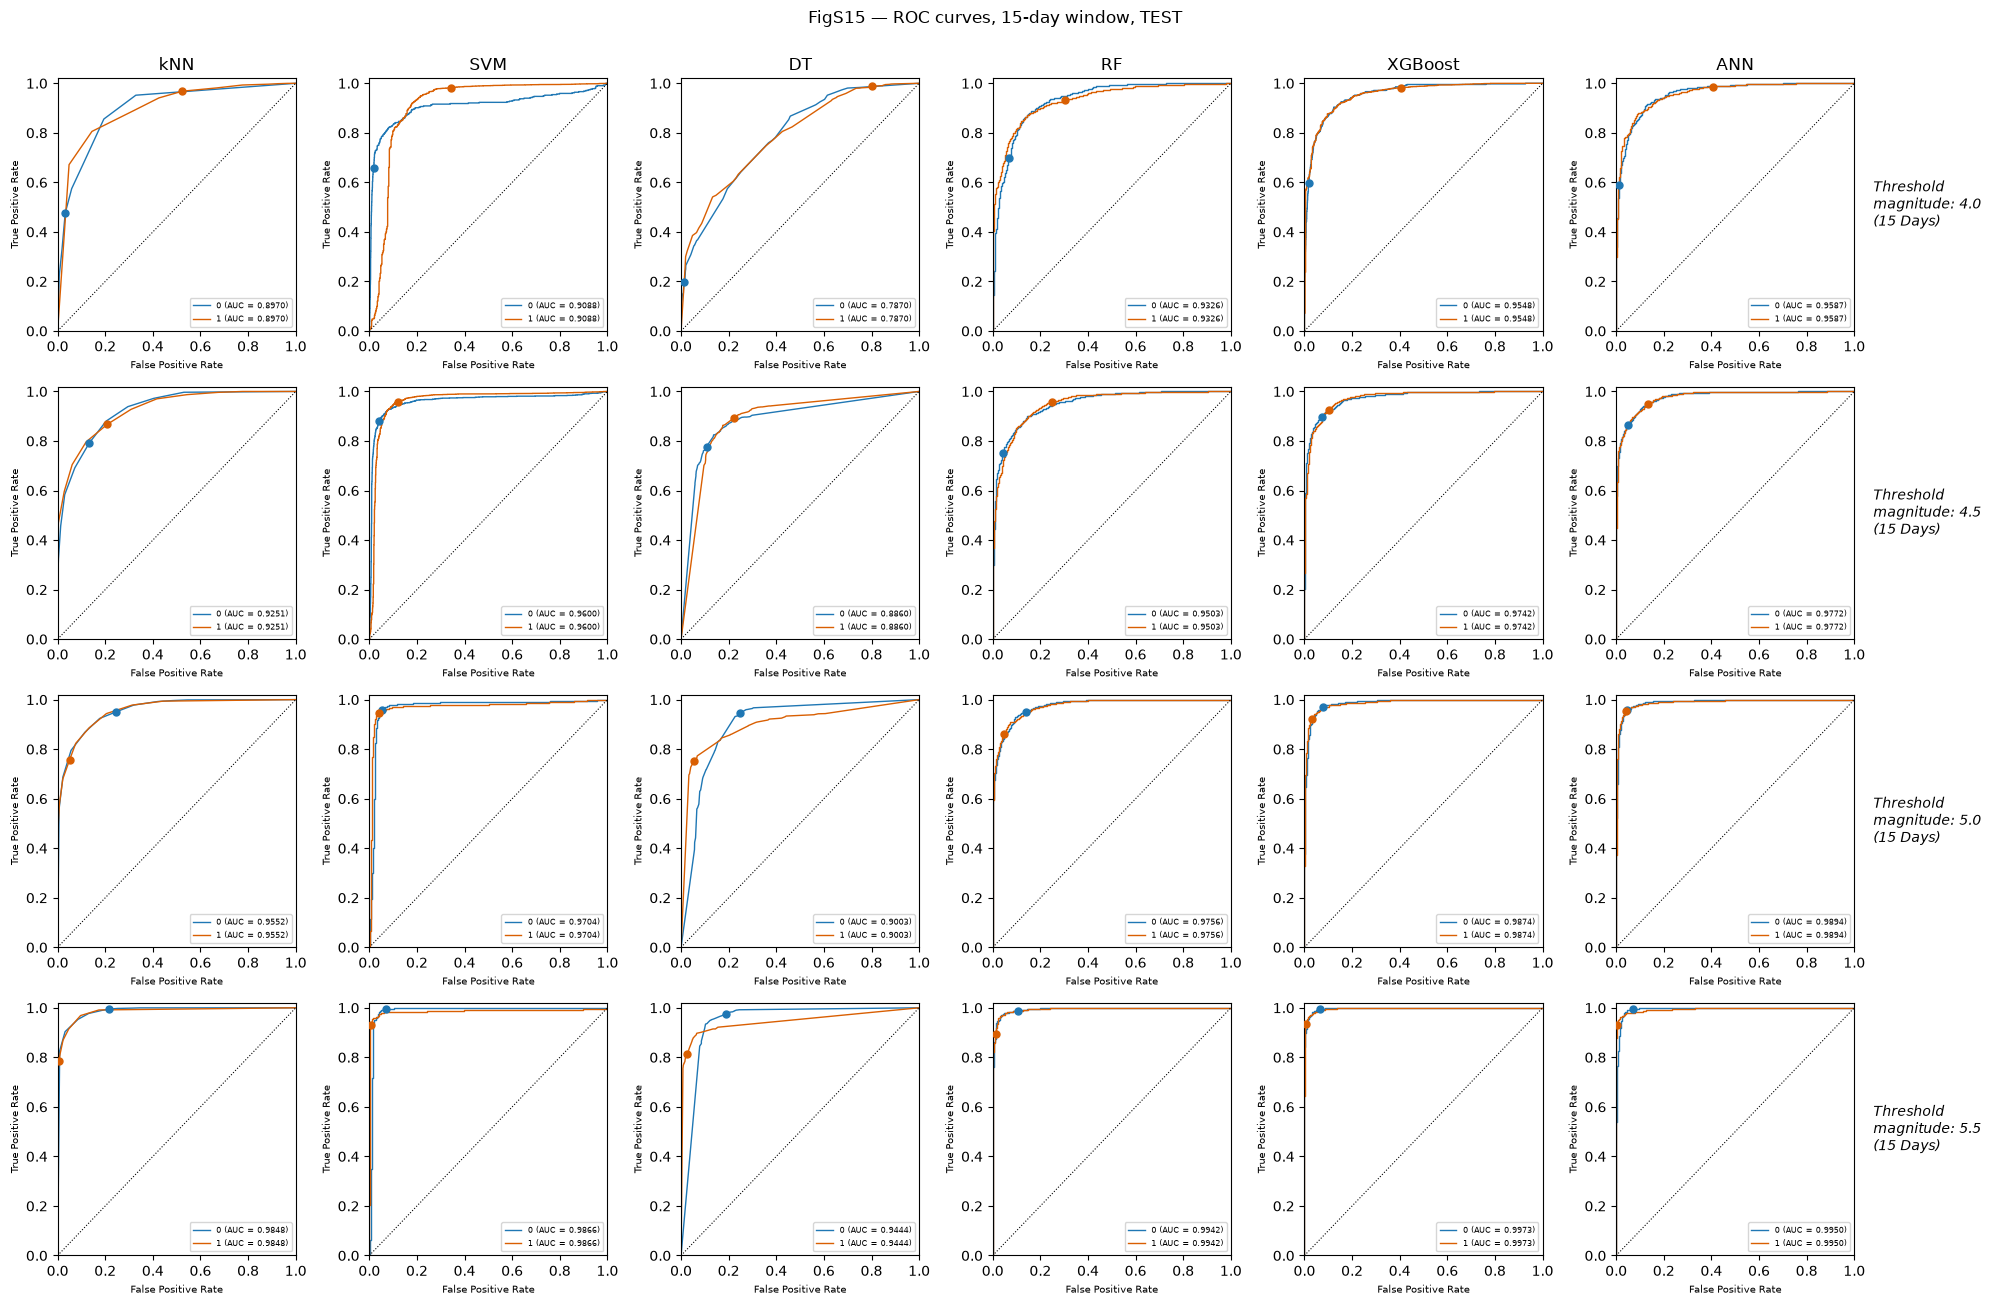

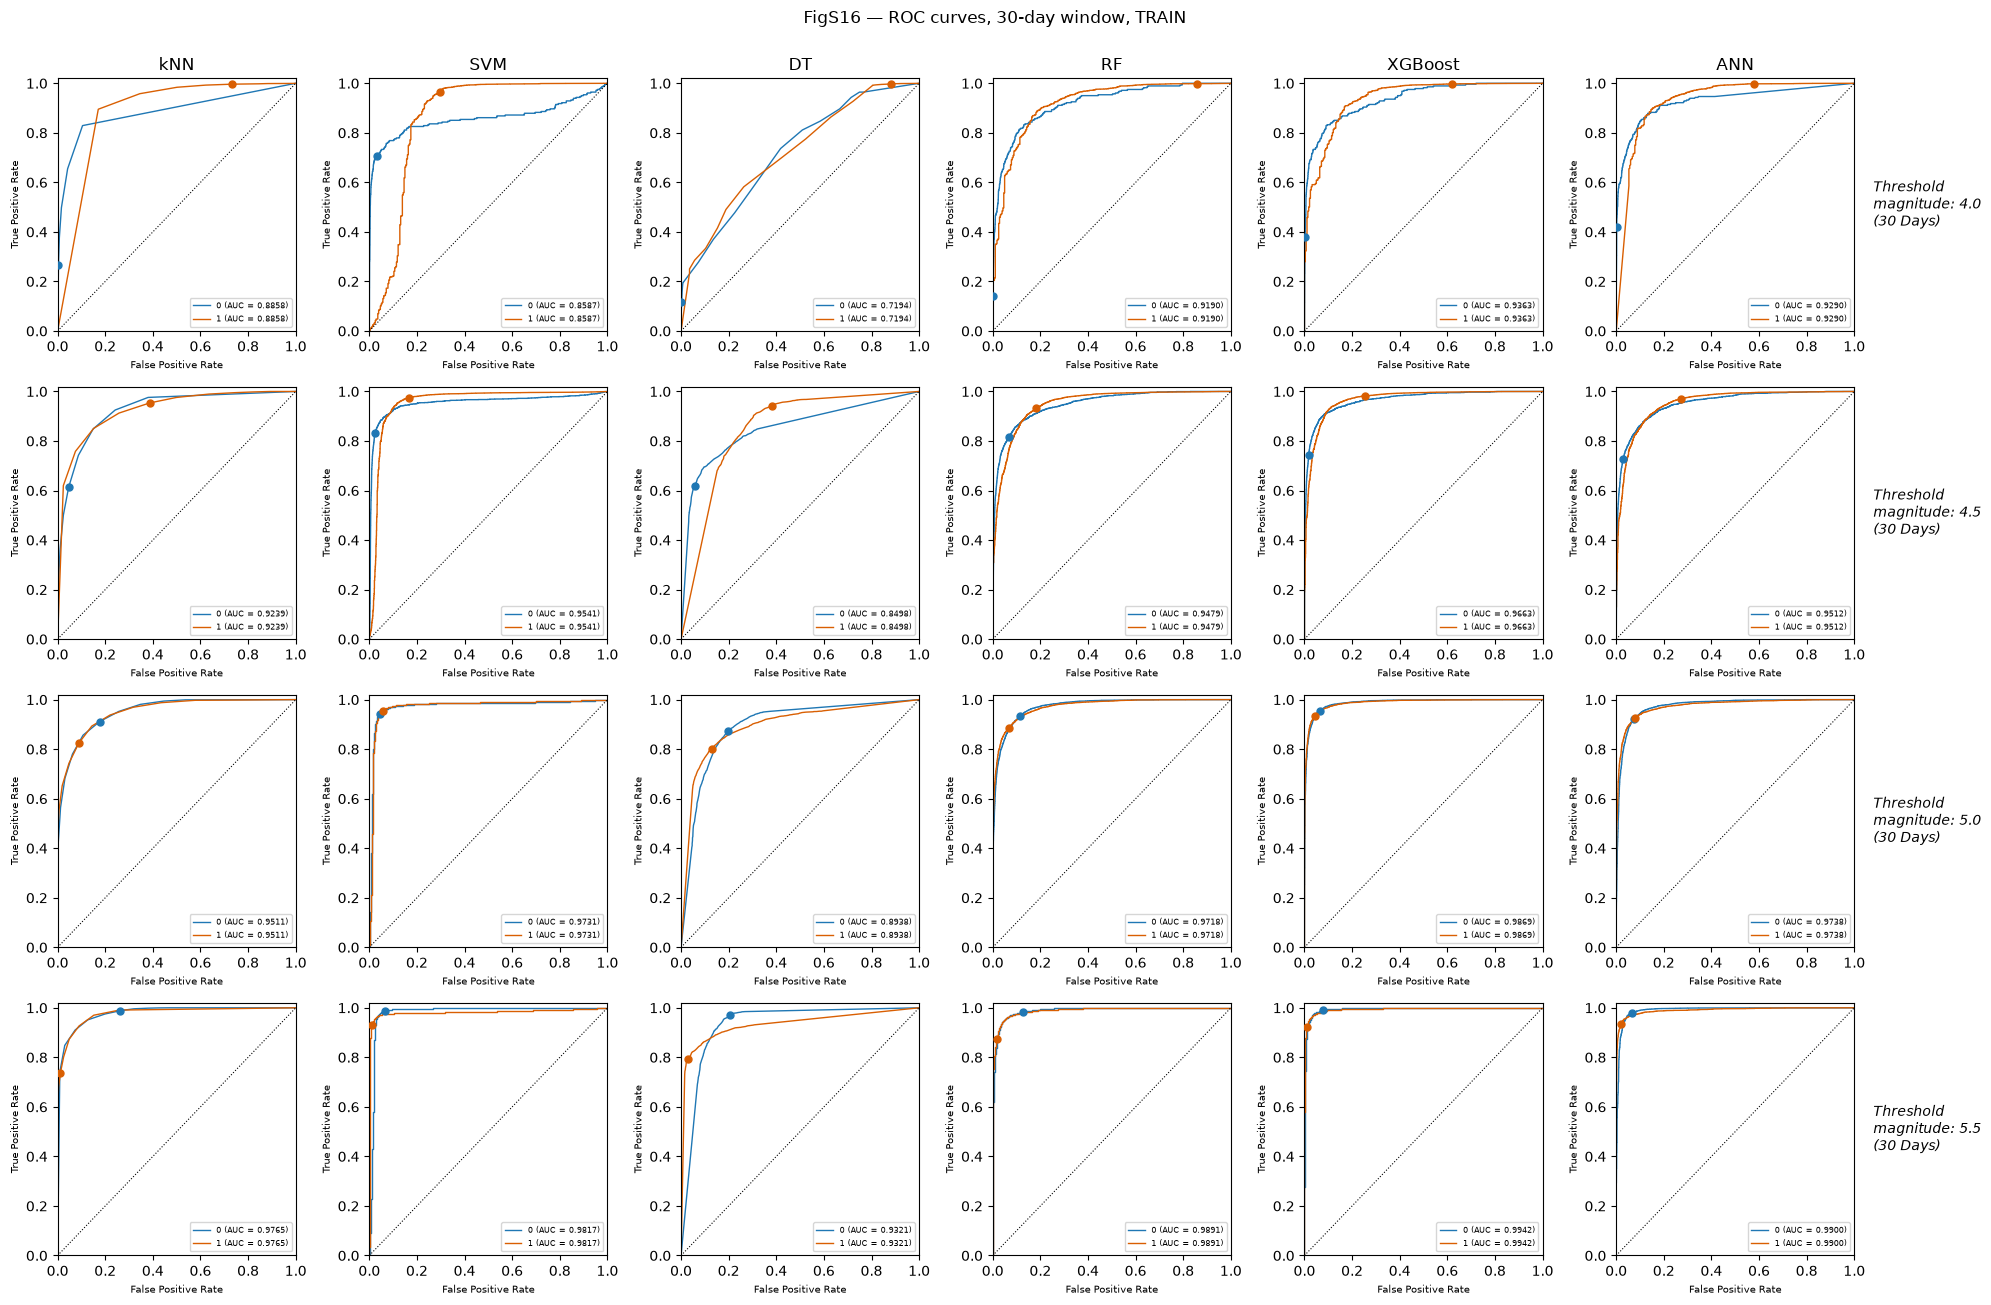

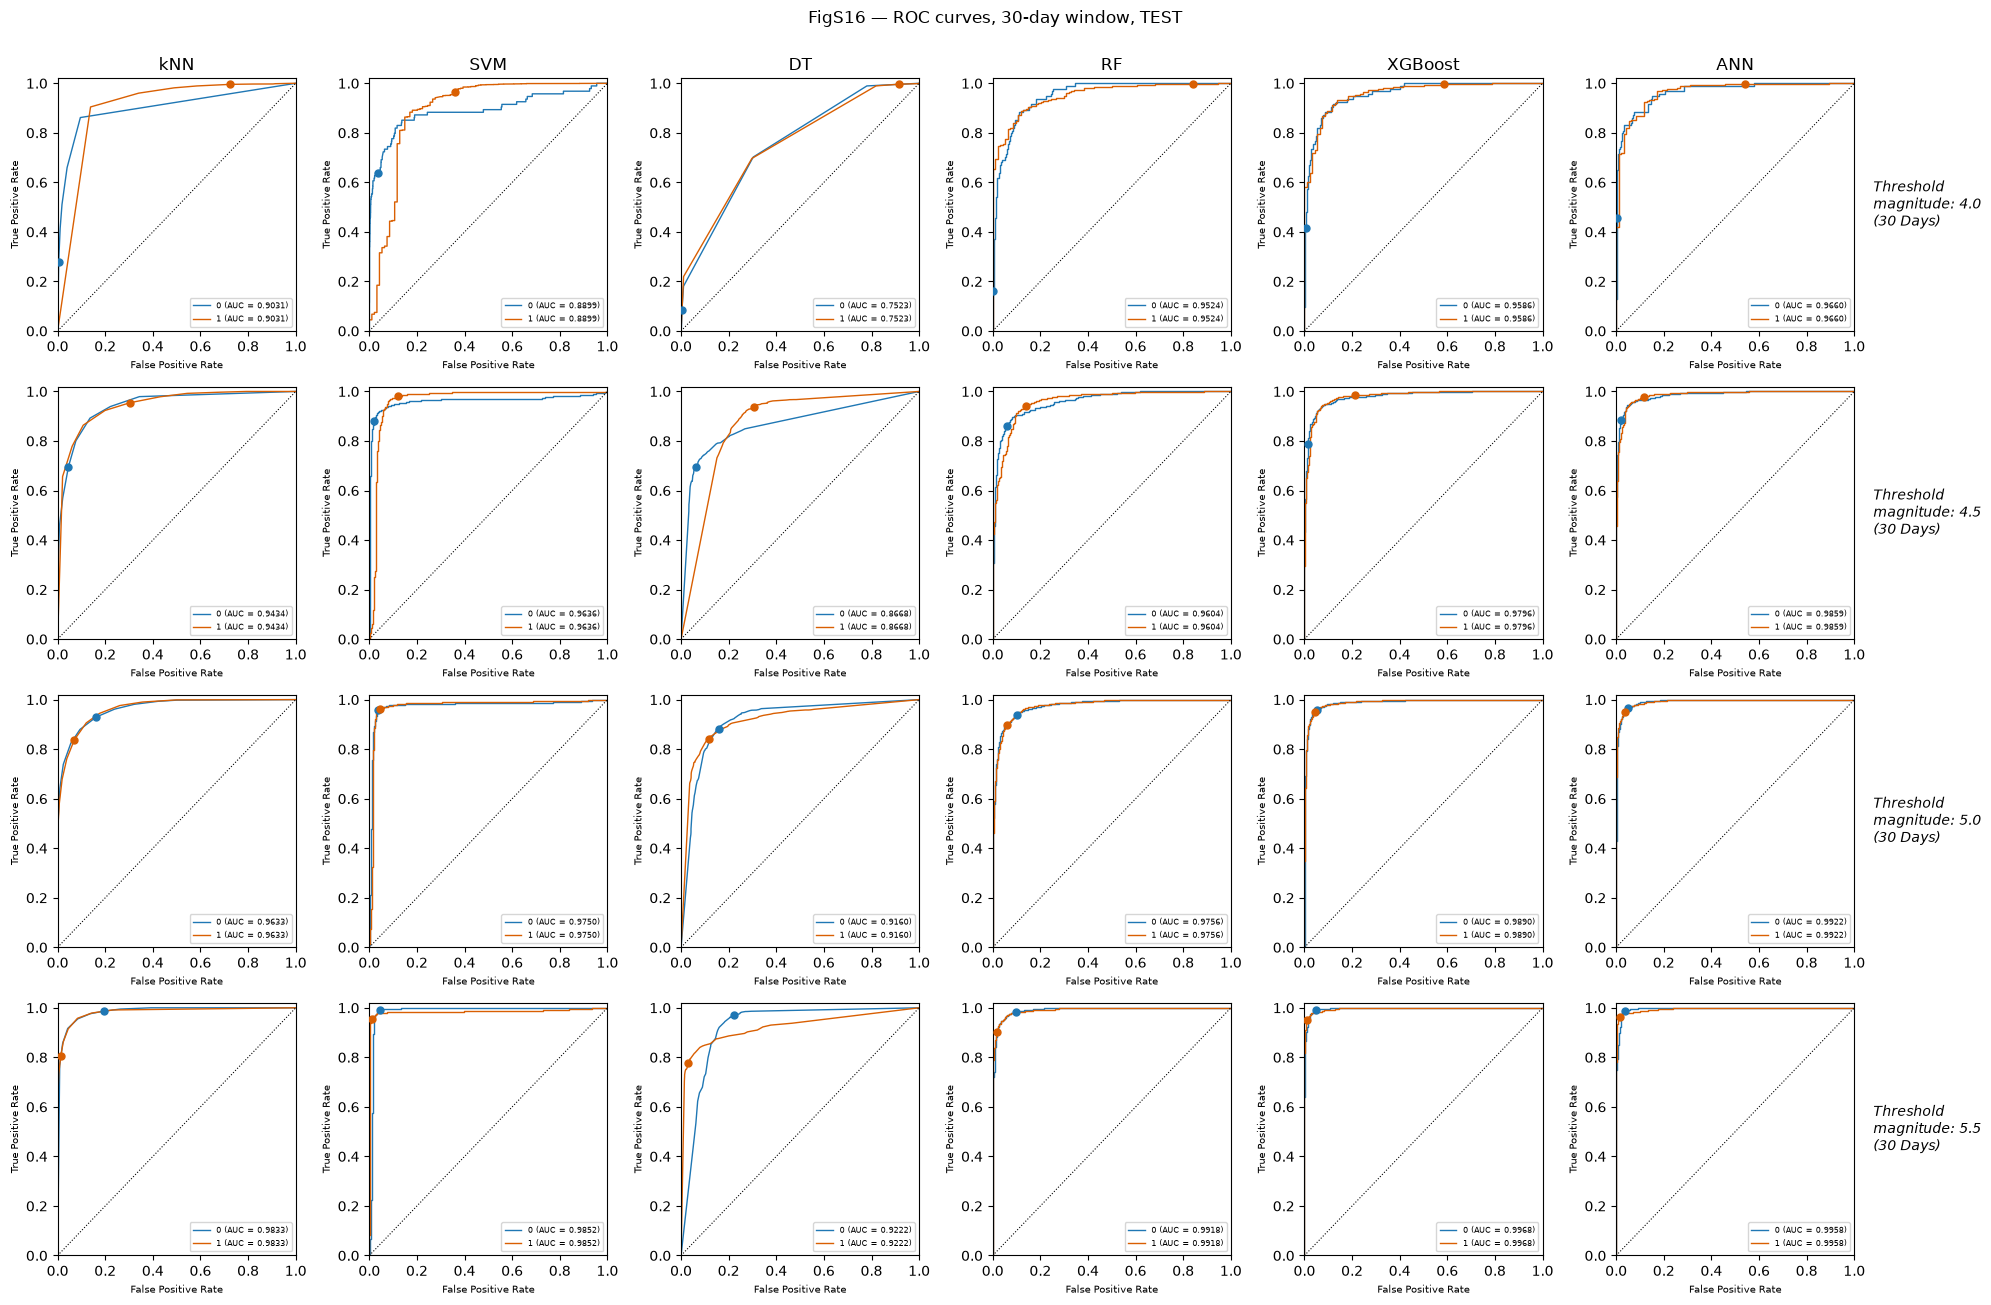

In [20]:
def plot_roc_grid(days, phase):
    fig, axes = plt.subplots(4, 6, figsize=(20, 13))
    for ti, thr in enumerate(THRESHOLDS):
        rec = ART.get((days, thr))
        for mi, name in enumerate(MODEL_ORDER):
            ax = axes[ti, mi]
            if rec is None or name not in rec['models']: ax.axis('off'); continue
            y = yy(rec, phase); yp, sc = get_art(rec, name, phase)
            f1, t1, _ = roc_curve(y, sc); f0, t0_, _ = roc_curve(1 - y, -sc); auc = roc_auc_score(y, sc)
            tn, fp, fn, tp = confusion_matrix(y, yp, labels=[0, 1]).ravel()
            ax.plot(f0, t0_, color='#1f77b4', lw=1, label=f'0 (AUC = {auc:.4f})'); ax.plot(f1, t1, color='#d95f02', lw=1, label=f'1 (AUC = {auc:.4f})')
            ax.scatter([fn / max(fn + tp, 1)], [tn / max(tn + fp, 1)], color='#1f77b4', zorder=5, s=25)
            ax.scatter([fp / max(fp + tn, 1)], [tp / max(tp + fn, 1)], color='#d95f02', zorder=5, s=25)
            ax.plot([0, 1], [0, 1], 'k:', lw=0.8); ax.legend(fontsize=6, loc='lower right'); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
            ax.set_xlabel('False Positive Rate', fontsize=7); ax.set_ylabel('True Positive Rate', fontsize=7)
            if ti == 0: ax.set_title(name)
            if mi == 5: ax.text(1.08, 0.5, f'Threshold\nmagnitude: {thr}\n({days} Days)', transform=ax.transAxes, va='center', fontstyle='italic')
    no = {7: 'Fig9', 10: 'FigS14', 15: 'FigS15', 30: 'FigS16'}[days]
    fig.suptitle(f'{no} — ROC curves, {days}-day window, {phase.upper()}', y=1.0)
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/{no}_ROC_{days}d_{phase}.png', dpi=170, bbox_inches='tight'); plt.show()
for d in WIN_PRESENT:
    for ph in ['Train', 'Test']: plot_roc_grid(d, ph)

### C7. Fig. 7 — learning curves (magnitude ≥ 4.0, 7-day window): training/CV accuracy and loss for each model

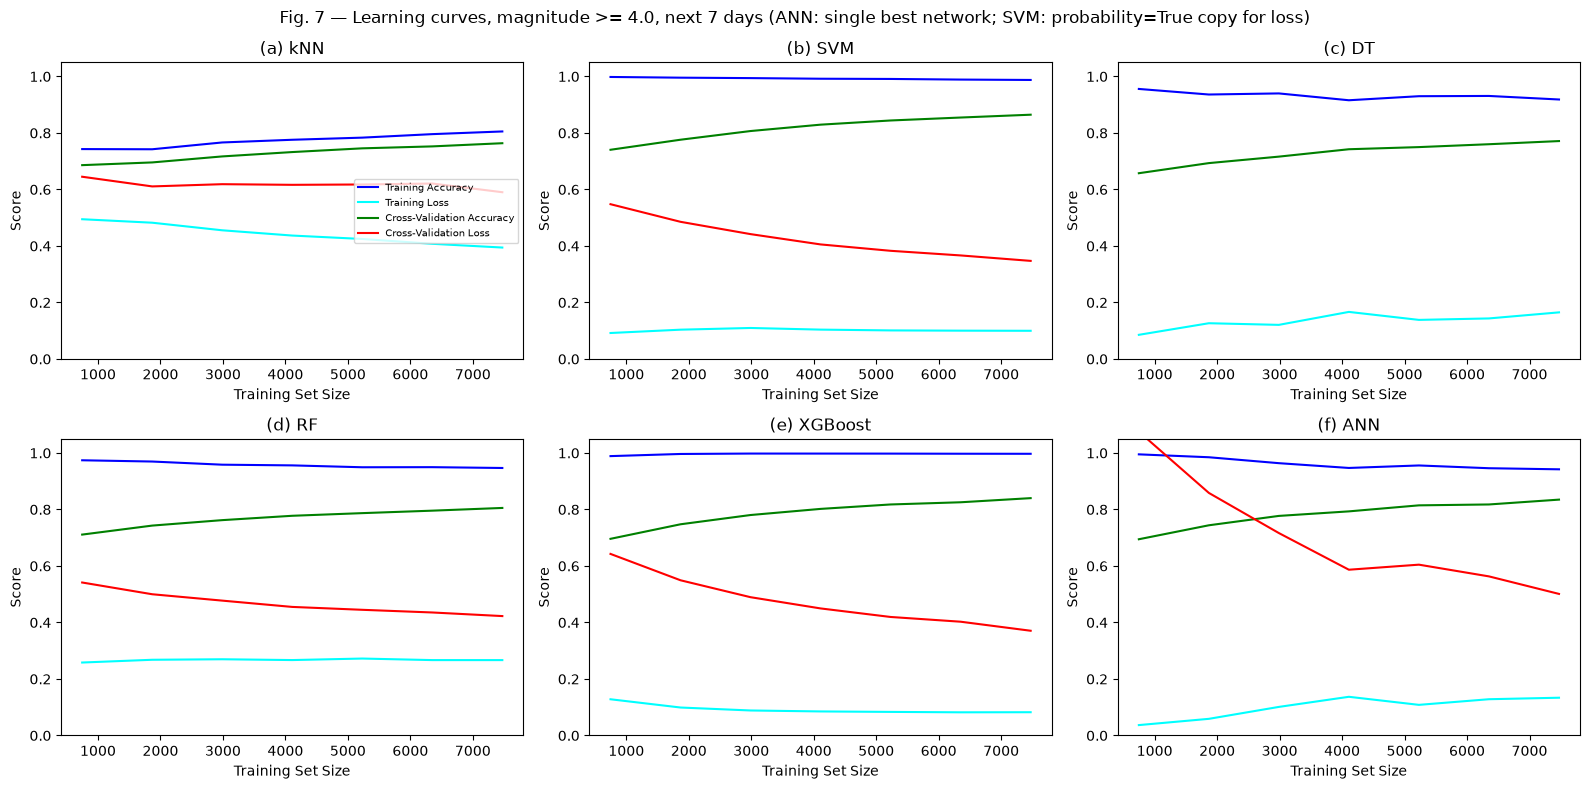

In [21]:
def curve_estimator(name, rec):
    p = rec['models'][name]['params']
    if name in ('kNN', 'DT', 'RF', 'XGBoost'):
        est, _ = classical_specs(rec['meta']['spw'])[name]; return est.set_params(**p)
    if name == 'SVM': return svm_base().set_params(**p).set_params(m__probability=True)
    return ann_base(1).set_params(**{**p[0], 'm__n_members': 1})

def learning_curves(est, X, y, fracs, n_splits=3):
    folds = list(StratifiedKFold(n_splits, shuffle=True, random_state=RNG_SEED).split(X, y))
    def one(f, tr, va):
        rng = np.random.RandomState(RNG_SEED); n = max(int(len(tr) * f), 60); sub = rng.choice(tr, n, replace=False)
        m = clone(est).fit(X[sub], y[sub]); ptr, pva = m.predict_proba(X[sub]), m.predict_proba(X[va])
        return (f, n, accuracy_score(y[sub], ptr.argmax(1)), log_loss(y[sub], ptr, labels=[0, 1]),
                accuracy_score(y[va], pva.argmax(1)), log_loss(y[va], pva, labels=[0, 1]))
    r = pd.DataFrame(Parallel(n_jobs=-1)(delayed(one)(f, tr, va) for f in fracs for tr, va in folds),
                     columns=['f', 'n', 'tr_acc', 'tr_loss', 'cv_acc', 'cv_loss'])
    return r.groupby('f').mean().reset_index()

if LEARNING and (7, 4.0) in ART:
    rec = ART[(7, 4.0)]; labels = make_labels(raw_df, feat_df_clean, 7, 4.0); X_tr, y_tr, _, _ = split_train_test(feat_df_clean, labels)
    fracs = [0.3, 1.0] if TINY else [0.1, 0.25, 0.4, 0.55, 0.7, 0.85, 1.0]
    fig, axes = plt.subplots(2, 3, figsize=(16, 8)); lc_all = []
    for ax, name in zip(axes.ravel(), MODEL_ORDER):
        if name not in rec['models']: ax.axis('off'); continue
        lc = learning_curves(curve_estimator(name, rec), X_tr, y_tr, fracs); lc['Model'] = name; lc_all.append(lc)
        ax.plot(lc.n, lc.tr_acc, color='blue', label='Training Accuracy'); ax.plot(lc.n, lc.tr_loss, color='cyan', label='Training Loss')
        ax.plot(lc.n, lc.cv_acc, color='green', label='Cross-Validation Accuracy'); ax.plot(lc.n, lc.cv_loss, color='red', label='Cross-Validation Loss')
        ax.set_title(f'({"abcdef"[MODEL_ORDER.index(name)]}) {name}'); ax.set_xlabel('Training Set Size'); ax.set_ylabel('Score'); ax.set_ylim(0, 1.05)
    axes[0, 0].legend(fontsize=7, loc='center right')
    fig.suptitle('Fig. 7 — Learning curves, magnitude >= 4.0, next 7 days (ANN: single best network; SVM: probability=True copy for loss)')
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/Fig7_learning_curves.png', dpi=200); plt.show()
    pd.concat(lc_all).to_csv(f'{FIG_DIR}/Fig7_learning_curves.csv', index=False)
else: print('learning curves skipped (EQ_LEARNING=0 or combo 7d/4.0 not trained)')

## D. Package everything

In [22]:
print(sorted(os.listdir(FIG_DIR)))
shutil.make_archive('paper_figures_and_tables', 'zip', FIG_DIR); print('ZIP ready: paper_figures_and_tables.zip')

['ALL_metrics_train_and_test.csv', 'BorutaSHAP_full_7d.csv', 'BorutaSHAP_summary_7d.csv', 'Fig10_train_accuracy.png', 'Fig11_test_accuracy.png', 'Fig1b_event_map.png', 'Fig2_workflow.png', 'Fig3_magnitude_histogram.png', 'Fig4_correlation_matrix.csv', 'Fig4_correlation_matrix.pdf', 'Fig4_correlation_matrix.png', 'Fig4_correlation_matrix.xlsx', 'Fig5_BorutaSHAP_train_7d.png', 'Fig6_BorutaSHAP_test_7d.png', 'Fig7_learning_curves.csv', 'Fig7_learning_curves.png', 'Fig8_confusion_7d_Test.png', 'Fig8_confusion_7d_Train.png', 'Fig9_ROC_7d_Test.png', 'Fig9_ROC_7d_Train.png', 'FigS10_confusion_10d_Test.png', 'FigS10_confusion_10d_Train.png', 'FigS11_confusion_15d_Test.png', 'FigS11_confusion_15d_Train.png', 'FigS12_confusion_30d_Test.png', 'FigS12_confusion_30d_Train.png', 'FigS14_ROC_10d_Test.png', 'FigS14_ROC_10d_Train.png', 'FigS15_ROC_15d_Test.png', 'FigS15_ROC_15d_Train.png', 'FigS16_ROC_30d_Test.png', 'FigS16_ROC_30d_Train.png', 'FigS1_correlation_matrix_10d.png', 'FigS2_correlation_matr

## Notes
1. **Train vs test:** "Train" metrics/matrices/ROC come from **cross-validated predictions on the training set** (classical models & SVM: 5-fold; ANN: 3-fold of its best configuration) — not from re-predicting training rows, so they are honest. "Test" = untouched 25 % hold-out. The paper's Figs 8, 9 and Tables 4–7 are *training-phase* results; Table 9 and Fig 11 are test accuracies.
2. **Under-sampling:** the paper under-sampled; this pipeline keeps all rows, so class-1/class-0 counts in Table 2 differ from the paper's.
3. **Boruta-SHAP** is a self-contained implementation (shadow features + RandomForest + SHAP TreeExplainer + binomial test), run on a ≤3000-row subsample for speed; importance values are mean |SHAP| (probability units), so their scale differs from the paper's ×10⁻⁵ axis, but the *ranking logic* is the same.
4. Random stratified split + overlapping windows can inflate test accuracy — keep the chronological-split check from the final notebook in your report.

## E. Dashboard models (feeds `app.py`)
Trains one deployable model per (window × threshold) combo with the tuned hyper-parameters from §B, stores the cleaning bounds + catalogue bbox, and records **random-split and chronological-split** test metrics so the dashboard can show honest reliability. Pickle-safe models only: `EQ_DEPLOY_MODEL` = XGBoost (default) | RF | DT | kNN.

In [23]:
from sklearn.base import clone
DEPLOY_MODEL = os.environ.get('EQ_DEPLOY_MODEL', 'XGBoost'); DASH = 'dashboard_models'; os.makedirs(DASH, exist_ok=True)
Xr = feat_df[FEATURE_COLS].replace([np.inf, -np.inf], np.nan); lo, hi = Xr.quantile(0.01), Xr.quantile(0.99)
med = Xr.clip(lower=lo, upper=hi, axis=1).median()
json.dump(dict(features=FEATURE_COLS, lo=lo.to_dict(), hi=hi.to_dict(), med=med.to_dict(), model=DEPLOY_MODEL,
               bbox=[float(raw_df.lattitude.min()) - 1, float(raw_df.lattitude.max()) + 1, float(raw_df.longitude.min()) - 1, float(raw_df.longitude.max()) + 1],
               train_minmag=float(raw_df.magnitude.min())), open(f'{DASH}/config.json', 'w'))
for days in WINDOWS:
    for thr in THRESHOLDS:
        labels = make_labels(raw_df, feat_df_clean, days, thr)
        est = clone(classical_specs(float((labels == 0).sum() / max(labels.sum(), 1)))[DEPLOY_MODEL][0])
        if (days, thr) in ART and DEPLOY_MODEL in ART[(days, thr)]['models']: est.set_params(**ART[(days, thr)]['models'][DEPLOY_MODEL]['params'])
        res = {}
        for mode in ('random', 'chronological'):
            Xtr, ytr, Xte, yte = split_train_test(feat_df_clean, labels, mode=mode); p = clone(est).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
            res[mode] = (accuracy_score(yte, p > 0.5), roc_auc_score(yte, p) if len(set(yte)) > 1 else np.nan)
        m = clone(est).fit(feat_df_clean[FEATURE_COLS].values, labels)          # final model uses all rows
        joblib.dump(dict(model=m, base_rate=float(labels.mean()), acc_rand=res['random'][0], acc_chrono=res['chronological'][0],
                         auc_chrono=res['chronological'][1]), f'{DASH}/{days}_{thr}.joblib')
        print(days, thr, DEPLOY_MODEL, 'random acc %.3f | chrono acc %.3f | chrono AUC %.3f' % (res['random'][0], res['chronological'][0], res['chronological'][1]))
print('saved ->', DASH, '| copy this folder next to app.py')

7 4.0 XGBoost random acc 0.869 | chrono acc 0.712 | chrono AUC 0.674
7 4.5 XGBoost random acc 0.890 | chrono acc 0.650 | chrono AUC 0.709
7 5.0 XGBoost random acc 0.953 | chrono acc 0.782 | chrono AUC 0.714
7 5.5 XGBoost random acc 0.986 | chrono acc 0.876 | chrono AUC 0.834
10 4.0 XGBoost random acc 0.899 | chrono acc 0.813 | chrono AUC 0.691
10 4.5 XGBoost random acc 0.900 | chrono acc 0.623 | chrono AUC 0.694
10 5.0 XGBoost random acc 0.952 | chrono acc 0.752 | chrono AUC 0.703
10 5.5 XGBoost random acc 0.982 | chrono acc 0.849 | chrono AUC 0.812
15 4.0 XGBoost random acc 0.939 | chrono acc 0.910 | chrono AUC 0.671
15 4.5 XGBoost random acc 0.917 | chrono acc 0.651 | chrono AUC 0.674
15 5.0 XGBoost random acc 0.953 | chrono acc 0.707 | chrono AUC 0.678
15 5.5 XGBoost random acc 0.986 | chrono acc 0.857 | chrono AUC 0.833
30 4.0 XGBoost random acc 0.981 | chrono acc 0.993 | chrono AUC 0.577
30 4.5 XGBoost random acc 0.952 | chrono acc 0.847 | chrono AUC 0.656
30 5.0 XGBoost random ac